# Codes
`The Retraction Epidemic in Science Across Publishers, Fields, and Countries` by Sara Venturini, Alessandra Urbinati, Paola Gallo, Jessica T. Davis, Alessandro Vespignani

In [3]:
import pandas as pd
import pandas_gbq
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from tqdm import tqdm
import pickle
import os
from scipy.optimize import curve_fit
from scipy import stats
from scipy.stats import t
from scipy.stats import linregress
from scipy.optimize import minimize
import statsmodels.api as sm
from statsmodels.genmod.families import Poisson
from statsmodels.genmod.families import NegativeBinomial 
import pycountry
import warnings
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)   
pd.set_option('display.width', None)  
pd.set_option('display.max_colwidth', None) 

## Functions

In [31]:
def try_all_fit(SCALE,alpha,df,start_year,end_year,plot_,output_folder,title,field_id_scaled_name_dict=None,field_id_scaled=None):   

    if field_id_scaled is not None and field_id_scaled in field_id_scaled_name_dict:
        field_name = field_id_scaled_name_dict[field_id_scaled]
    else:
        field_name = None
    
    results_df = pd.DataFrame()
    fig, axs = plt.subplots(4, 2,figsize=(13, 12), sharex=True)
    results_df_model, axs = fitting_fun(SCALE,alpha,df,start_year,end_year, 'GLM Poisson constant incidence',output_folder,plot_, axs, title, (64/255, 224/255, 208/255, 1), field_id_scaled_name_dict,field_id_scaled)
    results_df = pd.concat([results_df,results_df_model])
    results_df_model, axs = fitting_fun(SCALE,alpha,df,start_year,end_year, 'Poisson linear incidence',output_folder,plot_, axs, title, (64/255, 224/255, 208/255, 1), field_id_scaled_name_dict,field_id_scaled)
    results_df = pd.concat([results_df,results_df_model])
    results_df_model, axs = fitting_fun(SCALE,alpha,df,start_year,end_year, 'GLM Poisson exponential incidence',output_folder,plot_, axs, title, (64/255, 224/255, 208/255, 1), field_id_scaled_name_dict,field_id_scaled)
    results_df = pd.concat([results_df,results_df_model]).dropna(subset=['AIC']).drop(columns='AIC')

    #statistically significant
    results_df = results_df[
        (results_df['p value a'].isna()) |
        (results_df['p value b'].isna()) |
        ((results_df['p value a'] < 0.05) & (results_df['p value b'] < 0.05))
    ]

    results_df['ΔBIC'] = results_df['BIC'] - results_df['BIC'].min()

    if field_id_scaled is not None:
        results_df['ΔBIC_weighted'] = np.exp(-results_df['ΔBIC'] / 2)
        results_df['ΔBIC_weighted'] = results_df['ΔBIC_weighted'] / results_df.groupby(['field_id_scaled'])['ΔBIC_weighted'].transform('sum')   #)*100
    else:
        results_df['ΔBIC_weighted'] = np.exp(-results_df['ΔBIC'] / 2)
        results_df['ΔBIC_weighted'] = results_df['ΔBIC_weighted'] / results_df['ΔBIC_weighted'].sum()  #)*100

    results_df_model, axs = fitting_fun(SCALE,alpha,df,start_year,end_year, 'GLM Negative Binomial exponential incidence',output_folder,plot_, axs, title, (64/255, 224/255, 208/255, 1), field_id_scaled_name_dict,field_id_scaled)
    
    model = (results_df[results_df['ΔBIC']==0.0]).loc[0]['model']
    if model == 'GLM Poisson exponential incidence':
        results_df_model = results_df_model[(~results_df_model['p value a'].isna()) & (~results_df_model['p value b'].isna()) & ((results_df_model['p value a'] < 0.05) & (results_df_model['p value b'] < 0.05))] #p-values
        if len(results_df_model)>0:
            results_df = pd.concat([results_df,results_df_model])
            results_df['best_model'] = 0
            results_df.loc[results_df['model'] =='GLM Negative Binomial exponential incidence', 'best_model'] = 1
        else:
            results_df['best_model'] = 0
            results_df.loc[results_df['ΔBIC'] == 0.0, 'best_model'] = 1            
    else:
        results_df['best_model'] = 0
        results_df.loc[results_df['ΔBIC'] == 0.0, 'best_model'] = 1

    if field_id_scaled is not None:
        results_df = results_df[['field_id_scaled', 'field_name', 'start year', 'end year', 'model', 'BIC', 'a', 'b', 'alpha', 'p value a', 'p value b', 'doubling time', 'doubling_time_lower','doubling_time_upper','ΔBIC', 'ΔBIC_weighted', 'best_model']]
    else:
        results_df = results_df[['start year', 'end year', 'model', 'BIC', 'a', 'b', 'alpha', 'p value a', 'p value b', 'doubling time', 'doubling_time_lower','doubling_time_upper', 'ΔBIC', 'ΔBIC_weighted', 'best_model']]

    if plot_:
        fig.subplots_adjust(hspace=0.4)
        row_titles = ['GLM Poisson constant incidence','Poisson linear incidence','GLM Poisson exponential incidence','GLM Negative Binomial exponential incidence']  # example subtitles
        for i, row_title in enumerate(row_titles):
            left_ax = axs[i, 0]
            right_ax = axs[i, 1]
            pos_left = left_ax.get_position()
            pos_right = right_ax.get_position()
            x_center = (pos_left.x0 + pos_right.x1) / 2
            y_above = pos_left.y1 + 0.02
            fig.text(x_center, y_above, row_title, ha='center', fontsize=11, fontweight='bold')
        if field_name:
            fig.suptitle(f'{field_name}', fontsize=12, ha='center', fontweight='bold', y=0.96)

    if field_name:
        fig.savefig(os.path.join(output_folder, f'plot_{field_name}_{start_year}_{end_year}_{alpha}.png'), dpi=300, bbox_inches='tight')
    else:
        fig.savefig(os.path.join(output_folder, f'plot_{start_year}_{end_year}_{alpha}.png'), dpi=300, bbox_inches='tight')

    if plot_:
        plt.show()
    else:
        plt.close()

    return(results_df)

def fitting_fun(SCALE,alpha,df,start_year,end_year,model_func_name, output_folder, plot_, axs, title, color=(64/255, 224/255, 208/255, 1), field_id_scaled_name_dict=None,field_id_scaled=None): 

    if field_id_scaled is not None and field_id_scaled in field_id_scaled_name_dict:
        field_name = field_id_scaled_name_dict[field_id_scaled]
    else:
        field_name = None

    if model_func_name == 'GLM Poisson constant incidence':

        x_fit = df['year'].values - df['year'].values.min()
        y_fit = df['retracted'].values  # counts
        exposure = df['total'].values   # exposure for offset
        offset = np.log(exposure)

        # ==== GLM with Intercept Only ====
        X_const = np.ones_like(x_fit).reshape(-1, 1)  # design matrix: intercept only
        model = sm.GLM(y_fit, X_const, family=Poisson(), offset=offset)
        results = model.fit(maxiter=2000)

        # ==== Predictions ====
        y_pred = results.predict(X_const, offset=offset)

        x_smooth = np.linspace(x_fit.min(), x_fit.max(), 250)
        offset_smooth = np.interp(x_smooth, x_fit, exposure)
        offset_log_smooth = np.log(offset_smooth)
        X_smooth_const = np.ones_like(x_smooth).reshape(-1, 1)
        y_smooth = results.predict(X_smooth_const, offset=offset_log_smooth)

        # ==== Confidence Intervals ====
        dof = results.df_resid
        cov = results.cov_params()
        J = np.ones_like(x_smooth).reshape(-1, 1)  # design matrix for CI
        lp = results.predict(X_smooth_const, linear=True, offset=offset_log_smooth)
        se_lp = np.sqrt(np.sum((J @ cov) * J, axis=1))
        crit_val = stats.t.ppf(0.975, dof)
        lp_upper = lp + crit_val * se_lp
        lp_lower = lp - crit_val * se_lp
        counts_upper = np.exp(lp_upper)
        counts_lower = np.exp(lp_lower)

        # ==== Extract Model Results ====
        a = results.params[0]
        se = results.bse[0]
        bic = results.bic
        aic = results.aic
        p_value = results.pvalues[0]

        # ==== Output Summary ====
        results_df = pd.DataFrame([{
            'model': model_func_name,
            'BIC': bic,
            'AIC': aic,
            'a': a,
            'b':np.nan,
            'alpha':np.nan,
            'p value a': p_value,
            'doubling time': np.nan,
            'doubling_time_lower':np.nan,
            'doubling_time_upper':np.nan,
        }])

        if plot_:
            color_alpha = list(color)
            color_alpha[3] = 0.3
            color_alpha = tuple(color_alpha)

            observed_rate =  (y_fit / exposure) * SCALE
            predicted_rate = (y_smooth / offset_smooth) * SCALE
            rate_lower = (counts_lower / offset_smooth) * SCALE
            rate_upper = (counts_upper / offset_smooth) * SCALE

            x_fit, observed_rate, x_smooth, predicted_rate, rate_lower, rate_upper

            ax = axs[0,0]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-')
            ax.fill_between(x_smooth, rate_lower, rate_upper, color=color, alpha=0.1)
            ax.set_ylabel('retraction incidence', fontsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, linestyle='--', linewidth=0.5)
            ax.set_xticks(x_fit)
            ax.set_xticklabels([])
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

            ax = axs[0,1]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-', label='Predicted constant rate')
            ax.fill_between(x_smooth, rate_lower, rate_upper, color=color, alpha=0.1, label='95% CI')
            ax.set_yscale('log')
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, which="both", linestyle='--', linewidth=0.5)
            ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
            ax.set_xticks(x_fit)
            ax.set_xticklabels([])
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')



    if model_func_name == 'Poisson linear incidence':

        x_fit = df['year'].values - df['year'].values.min()
        y_fit = df['retracted'].values
        N = df['total'].values  # population

        # Design matrix: X = [N_t, N_t * t]
        X = np.column_stack([N, N * x_fit])
        X = sm.add_constant(X)  # add intercept

        # ==== Fit Poisson model with identity link ====
        model = sm.GLM(y_fit, X, family=sm.families.Poisson(link=sm.families.links.identity()))
        results = model.fit()

        # ==== Predictions ====
        x_smooth = np.linspace(x_fit.min(), x_fit.max(), 500)
        N_smooth = np.interp(x_smooth, x_fit, N)
        X_smooth = np.column_stack([N_smooth, N_smooth * x_smooth])
        X_smooth = sm.add_constant(X_smooth)
        y_smooth = results.predict(X_smooth)

        # ==== Confidence Intervals ====
        dof = results.df_resid
        cov = results.cov_params()
        J = X_smooth
        lp = results.predict(X_smooth, linear=True)
        se_lp = np.sqrt(np.sum((J @ cov) * J, axis=1))
        crit_val = stats.t.ppf(0.975, dof)
        lp_upper = lp + crit_val * se_lp
        lp_lower = lp - crit_val * se_lp

        predicted_rate = ( y_smooth / N_smooth ) * SCALE
        rate_upper = (  lp_upper / N_smooth ) * SCALE
        rate_lower = (  lp_lower / N_smooth ) * SCALE

        # ==== Extract Results ====
        intercept, a, b = results.params
        se = results.bse
        p_values = results.pvalues
        bic = results.bic
        aic = results.aic

        results_df = pd.DataFrame([{
            'model': model_func_name,
            'BIC': bic,
            'AIC': aic,
            'a': a,
            'b': b,
            'p value a': p_values[1],
            'p value b': p_values[2],
            'doubling time': np.nan,
            'doubling_time_lower':np.nan,
            'doubling_time_upper':np.nan,
        }])

        if plot_:

            color_alpha = list(color)
            color_alpha[3] = 0.3
            color_alpha = tuple(color_alpha)

            observed_rate = ( y_fit / N ) * SCALE

            ax = axs[1, 0]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-')
            ax.fill_between(x_smooth, rate_lower, rate_upper, color=color, alpha=0.1)
            ax.set_ylabel('retraction incidence', fontsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, linestyle='--', linewidth=0.5)
            ax.set_xticks(x_fit)
            ax.set_xticklabels([])
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

            ax = axs[1, 1]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-', label='Predicted linear incidence')
            ax.fill_between(x_smooth, rate_lower, rate_upper, color=color, alpha=0.1, label='95% CI')
            ax.set_yscale('log')
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, which="both", linestyle='--', linewidth=0.5)
            ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
            ax.set_xticks(x_fit)
            ax.set_xticklabels([])
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')


    if model_func_name == 'GLM Poisson exponential incidence':

        x_fit = df['year'].values - df['year'].values.min()
        y_fit = df['retracted'].values  # counts
        exposure = df['total'].values    # exposure for offset

        X = sm.add_constant(x_fit)
        offset = np.log(exposure)
        model = sm.GLM(y_fit, X, family=Poisson(), offset=offset)
        results = model.fit(maxiter=2000)

        y_pred = results.predict(X, offset=offset)

        x_smooth = np.linspace(x_fit.min(), x_fit.max(), 250)
        X_smooth = sm.add_constant(x_smooth)
        offset_smooth = np.interp(x_smooth, x_fit, exposure)
        offset_log_smooth = np.log(offset_smooth)
        y_smooth = results.predict(X_smooth, offset=offset_log_smooth)

        dof = results.df_resid
        cov = results.cov_params()
        J = np.column_stack((np.ones_like(x_smooth), x_smooth))
        lp = results.predict(X_smooth, linear=True, offset=offset_log_smooth)
        se_lp = np.sqrt(np.sum((J @ cov) * J, axis=1))
        crit_val = stats.t.ppf(0.975, dof)
        lp_upper = lp + crit_val * se_lp
        lp_lower = lp - crit_val * se_lp
        counts_upper = np.exp(lp_upper)
        counts_lower = np.exp(lp_lower)

        a, b = results.params
        #thtta = results.model.alpha #dispersion
        se = results.bse
        doubling_time = np.log(2) / b if b != 0 else np.inf
        b_lower = b - crit_val * se[1]
        b_upper = b + crit_val * se[1]
        doubling_time_lower = np.log(2) / b_upper
        doubling_time_upper = np.log(2) / b_lower

        bic = results.bic
        aic = results.aic
        p_values = results.pvalues

        results_df = pd.DataFrame([{
            'model': model_func_name,
            'BIC': bic,
            'AIC': aic,
            'a': a,
            'b': b,
            'alpha':np.nan,
            'p value a': p_values[0],
            'p value b': p_values[1],
            'doubling time': doubling_time,
            'doubling_time_lower':doubling_time_lower,
            'doubling_time_upper':doubling_time_upper,
        }])

        if plot_:

            color_alpha = list(color)
            color_alpha[3] = 0.3
            color_alpha = tuple(color_alpha)

            observed_rate = ( y_fit / exposure ) * SCALE
            predicted_rate = ( y_smooth / offset_smooth  ) * SCALE
            rate_lower = ( counts_lower / offset_smooth ) * SCALE
            rate_upper = ( counts_upper / offset_smooth ) * SCALE

            # --- Left plot: linear scale ---
            ax = axs[2,0]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-')
            ax.fill_between(x_smooth, rate_lower, rate_upper, color=color, alpha=0.1)
            ax.set_ylabel('retraction incidence', fontsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, linestyle='--', linewidth=0.5)
            ax.set_xticks(x_fit)
            ax.set_xticklabels([])
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

            # --- Right plot: log scale ---
            ax = axs[2,1]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1, label=f'Doubling time : {doubling_time:.1f} (95% CI [{doubling_time_lower:.2f}-{doubling_time_upper:.2f}]) yrs')
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-', label='Predicted rate')
            ax.fill_between(x_smooth, rate_lower, rate_upper, color=color, alpha=0.1, label='95% CI')
            ax.set_yscale('log')
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, which="both", linestyle='--', linewidth=0.5)
            ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
            ax.set_xticks(x_fit)
            ax.set_xticklabels([])
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')


    if model_func_name == 'GLM Negative Binomial exponential incidence':

        x_fit = df['year'].values - df['year'].values.min()
        y_fit = df['retracted'].values  # counts
        exposure = df['total'].values   # exposure for offset

        X = sm.add_constant(x_fit)
        offset = np.log(exposure)

        # Fit Negative Binomial GLM
        model = sm.GLM(y_fit, X, family=NegativeBinomial(alpha=alpha), offset=offset)
        results = model.fit(maxiter=2000)
        
        # Predict
        y_pred = results.predict(X, offset=offset)

        x_smooth = np.linspace(x_fit.min(), x_fit.max(), 250)
        X_smooth = sm.add_constant(x_smooth)
        offset_smooth = np.interp(x_smooth, x_fit, exposure)
        offset_log_smooth = np.log(offset_smooth)
        y_smooth = results.predict(X_smooth, offset=offset_log_smooth)

        # Confidence intervals (same as before)
        dof = results.df_resid
        cov = results.cov_params()
        J = np.column_stack((np.ones_like(x_smooth), x_smooth))
        lp = results.predict(X_smooth, linear=True, offset=offset_log_smooth)
        se_lp = np.sqrt(np.sum((J @ cov) * J, axis=1))
        crit_val = stats.t.ppf(0.975, dof)
        lp_upper = lp + crit_val * se_lp
        lp_lower = lp - crit_val * se_lp
        counts_upper = np.exp(lp_upper)
        counts_lower = np.exp(lp_lower)

        # Parameters and model stats
        a, b = results.params
        se = results.bse
        doubling_time = np.log(2) / b if b != 0 else np.inf
        b_lower = b - crit_val * se[1]
        b_upper = b + crit_val * se[1]
        doubling_time_lower = np.log(2) / b_upper
        doubling_time_upper = np.log(2) / b_lower
        p_values = results.pvalues
        bic = results.bic
        aic = results.aic


        # Output table
        results_df = pd.DataFrame([{
            'model': model_func_name,
            'BIC': bic,
            'AIC': aic,
            'a': a,
            'b': b,
            'alpha':alpha,
            'p value a': p_values[0],
            'p value b': p_values[1],
            'doubling time': doubling_time,
            'doubling_time_lower':doubling_time_lower,
            'doubling_time_upper':doubling_time_upper,
        }])

        if plot_:

            color_alpha = list(color)
            color_alpha[3] = 0.3
            color_alpha = tuple(color_alpha)

            observed_rate = ( y_fit / exposure ) * SCALE
            predicted_rate = ( y_smooth / offset_smooth ) * SCALE
            rate_lower = ( counts_lower / offset_smooth ) * SCALE
            rate_upper = ( counts_upper / offset_smooth ) * SCALE

            # --- Left plot: linear scale ---
            ax = axs[3,0]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-')
            ax.fill_between(x_smooth, rate_lower, rate_upper, color=color, alpha=0.1)
            ax.set_xlabel('Year', fontsize=14)
            ax.set_ylabel('retraction incidence', fontsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, linestyle='--', linewidth=0.5)

            ax.set_xticks(x_fit)
            ax.set_xticklabels(df['year'].values)
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

            # --- Right plot: log scale ---
            ax = axs[3,1]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1, label=f'Doubling time : {doubling_time:.1f} (95% CI [{doubling_time_lower:.2f}-{doubling_time_upper:.2f}]) yrs')
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-', label='Predicted rate')
            ax.fill_between(x_smooth, rate_lower, rate_upper, color=color, alpha=0.1, label='95% CI')
            ax.set_xlabel('Year', fontsize=14)
            ax.set_yscale('log')
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, linestyle='--', linewidth=0.5)
            ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
            ax.set_xticks(x_fit)
            ax.set_xticklabels(df['year'].values)
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')


    results_df.insert(0, 'end year', end_year)
    results_df.insert(0, 'start year', start_year)

    print(model_func_name)
    if plot_:
        observed_df = pd.DataFrame({'year':x_fit,'observed_rate':observed_rate})
        predicted_df = pd.DataFrame({'x_smooth':x_smooth,'predicted_rate':predicted_rate,'rate_lower':rate_lower,'rate_upper':rate_upper})
        if field_id_scaled is not None:
            observed_df.insert(0, 'field_name', field_name.replace(" ", ""))
            observed_df.insert(0, 'field_id_scaled', field_id_scaled)
            predicted_df.insert(0, 'field_name', field_name.replace(" ", ""))
            predicted_df.insert(0, 'field_id_scaled', field_id_scaled)
            if model_func_name== 'GLM Negative Binomial exponential incidence':
                observed_df.to_csv(os.path.join(output_folder, f'observed_df_{field_id_scaled}_{start_year}_{end_year}_{model_func_name}_{alpha}.csv'),index=False)
                predicted_df.to_csv(os.path.join(output_folder, f'predicted_df_{field_id_scaled}_{start_year}_{end_year}_{model_func_name}_{alpha}.csv'),index=False)
            else:
                observed_df.to_csv(os.path.join(output_folder, f'observed_df_{field_id_scaled}_{start_year}_{end_year}_{model_func_name}.csv'),index=False)
                predicted_df.to_csv(os.path.join(output_folder, f'predicted_df_{field_id_scaled}_{start_year}_{end_year}_{model_func_name}.csv'),index=False)
        else:
            if model_func_name== 'GLM Negative Binomial exponential incidence':
                observed_df.to_csv(os.path.join(output_folder, f'observed_df_{start_year}_{end_year}_{model_func_name}_{alpha}.csv'),index=False)
                predicted_df.to_csv(os.path.join(output_folder, f'predicted_df_{start_year}_{end_year}_{model_func_name}_{alpha}.csv'),index=False)     
            else:
                observed_df.to_csv(os.path.join(output_folder, f'observed_df_{start_year}_{end_year}_{model_func_name}.csv'),index=False)
                predicted_df.to_csv(os.path.join(output_folder, f'predicted_df_{start_year}_{end_year}_{model_func_name}.csv'),index=False)       

    if field_id_scaled is not None:
        results_df.insert(0, 'field_name', field_name)
        results_df.insert(0, 'field_id_scaled', field_id_scaled)

    if plot_:
        return results_df, axs
    else:
        return results_df,None,observed_df,predicted_df
    
def retracted_rolling_average(df,window_size=5,col=None):
    if col is None:
        df['mean'] = df.rolling(window=window_size).retracted_incidence.mean()
        df['var'] = df.rolling(window=window_size).retracted_incidence.var(ddof=0)
        df = df.dropna(subset=['mean', 'var'])[['year', 'mean', 'var']].sort_values(by='year').reset_index(drop=True)
    else:
        df['mean'] = df.groupby(col).retracted_incidence.transform(lambda x: x.rolling(window=window_size).mean())
        df['var'] = df.groupby(col).retracted_incidence.transform(lambda x: x.rolling(window=window_size).var(ddof=0))
        df = df.dropna(subset=['mean', 'var'])[[col,'year', 'mean', 'var']].sort_values(by=[col,'year']).reset_index(drop=True)
    return df

model_name_replace_dict = {'GLM Poisson constant incidence':'constant','Poisson linear incidence':'linear','GLM Poisson exponential incidence':'exponential'}
model_order = {'constant': 0, 'linear': 1, 'exponential': 2}
model_list = ['constant', 'linear', 'exponential']

In [ ]:
##BigQuery: query table and save it to Google Cloud Storage and download it locally (in './Data/' folder) in compressed format.

from google.cloud import bigquery

project_name = ""
dataset_name = ""
bucket_name = ""
path_credential = ''

def send_query_partition(target_dataset_name,target_table_name,sql_code,project_name=project_name, path_credential=path_credential, write_disposition="WRITE_TRUNCATE", partition = None, partition_label =None, clustering = None, clustering_label =None):
    ##---------- set job configurations
    client = bigquery.Client.from_service_account_json(path_credential, project = project_name)
    job_config = bigquery.QueryJobConfig()
    table_ref = client.dataset(target_dataset_name).table(target_table_name)
    job_config.destination = table_ref 
    job_config.write_disposition = write_disposition
    #################################
    #################################
    #################################
    if partition:
        job_config.time_partitioning = bigquery.table.TimePartitioning(field=partition_label, require_partition_filter=True)
    if clustering:
        job_config.clustering_fields = clustering_label
    #################################
    #################################
    #################################
    ##---------- start the query
    query_job = client.query(sql_code, job_config=job_config) # API request - starts the query
    return(query_job)  

def export_bq_table(destination_uri, project_name, table_id,dataset,path_credential=path_credential):
    client = bigquery.Client.from_service_account_json(path_credential, project = project_name)

    dataset_ref = bigquery.DatasetReference(project_name, dataset)
    table_ref = dataset_ref.table(table_id)

    job_config = bigquery.ExtractJobConfig()
    job_config.compression = bigquery.Compression.GZIP
    job_config.destination_format = (
        bigquery.DestinationFormat.CSV)
    extract_job = client.extract_table(
        table_ref,
        destination_uri,
        job_config=job_config,
        location="US",
    )  # API request
    extract_job.result()  # Waits for job to complete.

    print(
        "Exported {}:{}.{} to {}".format(project_name, dataset, table_id, destination_uri))

## Works

In [ ]:
sql = """
    CREATE TABLE `project_name.dataset_name.works_retracted_count` AS
    SELECT
    publication_year,
    COUNT(work_id) AS total_works,
    SUM(CAST(is_retracted AS INT64)) AS retracted_works
    FROM
    `project_name.dataset_name.works_info`
    WHERE
        publication_year BETWEEN '1992-01-01' AND '2021-01-01'
    GROUP BY
    publication_year
    ORDER BY
    publication_year;
"""
##output info
new_table_name = "works_retracted_count"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)

In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
output_folder = './Plots/plots_works'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

works_retracted_count = pd.read_csv(f'./Data/works_retracted_count.csv.gz', compression='gzip').rename(columns={'publication_year':'year'})
works_retracted_count['year'] = works_retracted_count['year'].str[:4].astype(int)
works_retracted_count = works_retracted_count.rename(columns={'total_works':'total','retracted_works':'retracted'})
works_retracted_count = works_retracted_count[(works_retracted_count.year>=1980) & (works_retracted_count.year<=2024)].reset_index(drop=True)

In [33]:
## yearly works published and retracted count

df = works_retracted_count.copy()
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
df

,Unnamed: 0,year,total,retracted
0,0,1992,1344472,24
1,1,1993,1418265,27
2,2,1994,1499924,37
3,3,1995,1591698,51
4,4,1996,1725250,45
5,5,1997,1815084,53
6,6,1998,1887848,76
7,7,1999,1970767,99
8,8,2000,2218768,126
9,9,2001,2370416,163


  0%|          | 0/4 [00:00<?, ?it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


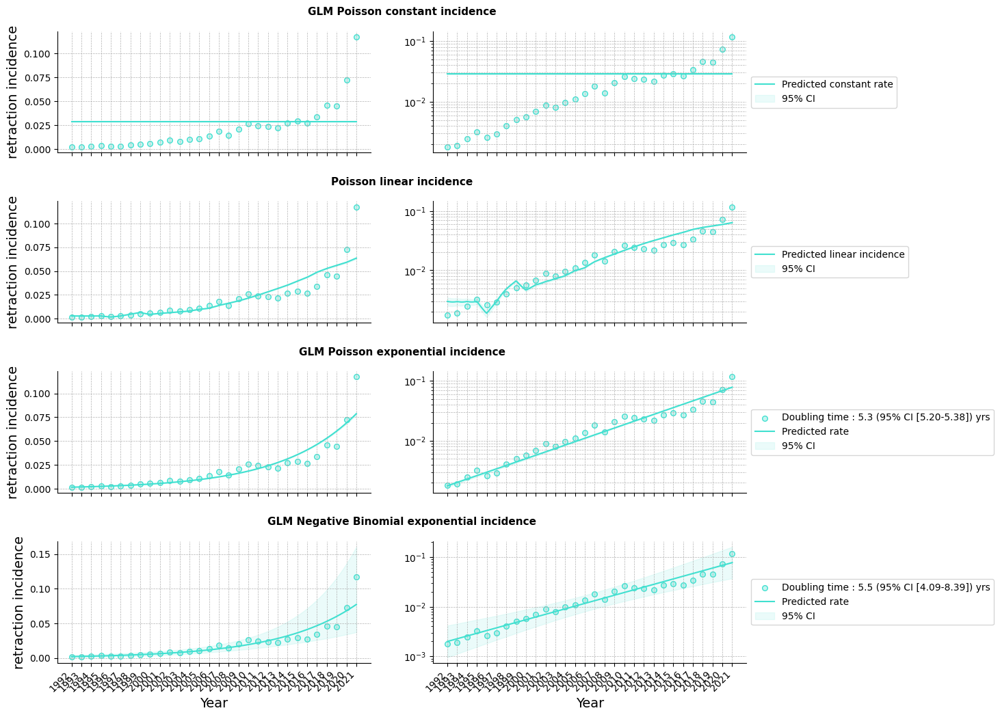

 25%|██▌       | 1/4 [00:00<00:02,  1.20it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


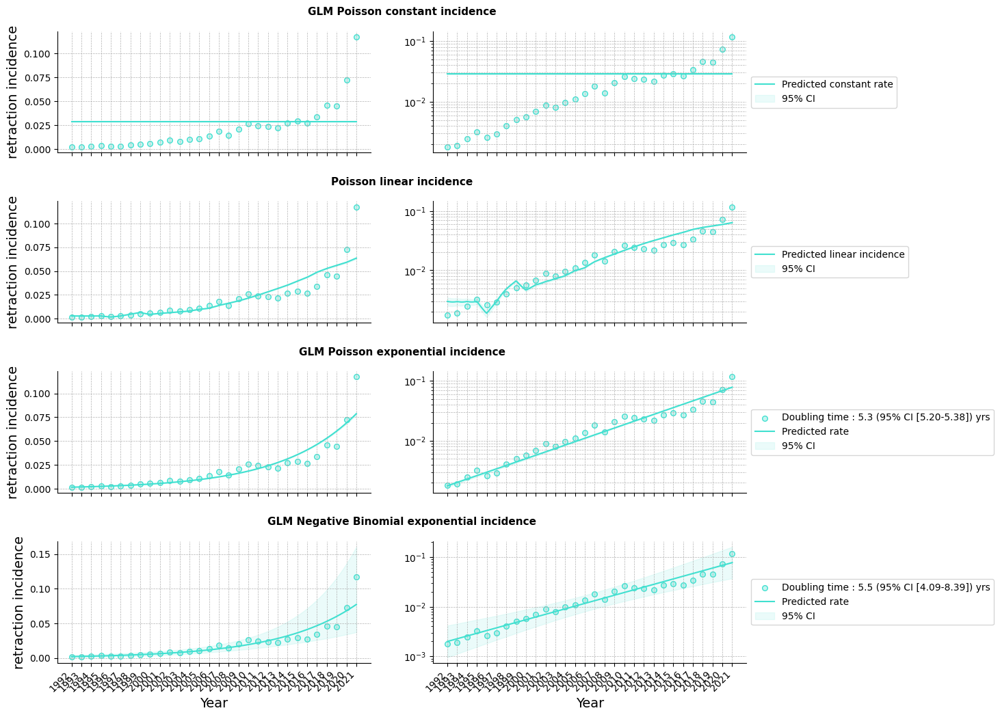

 50%|█████     | 2/4 [00:01<00:01,  1.27it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


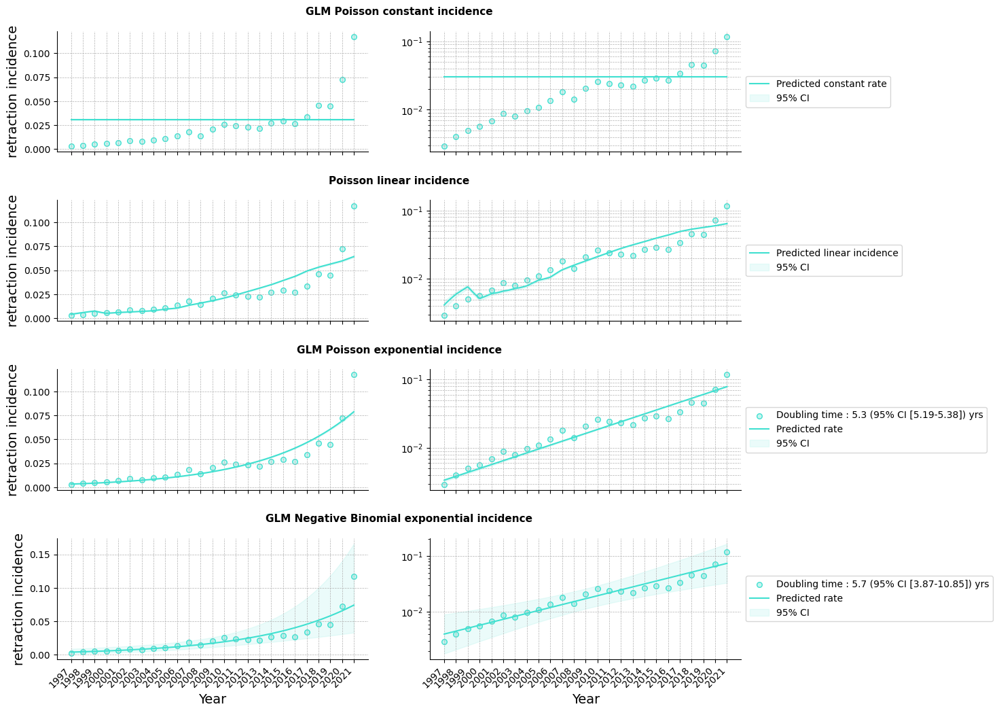

 75%|███████▌  | 3/4 [00:02<00:00,  1.28it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


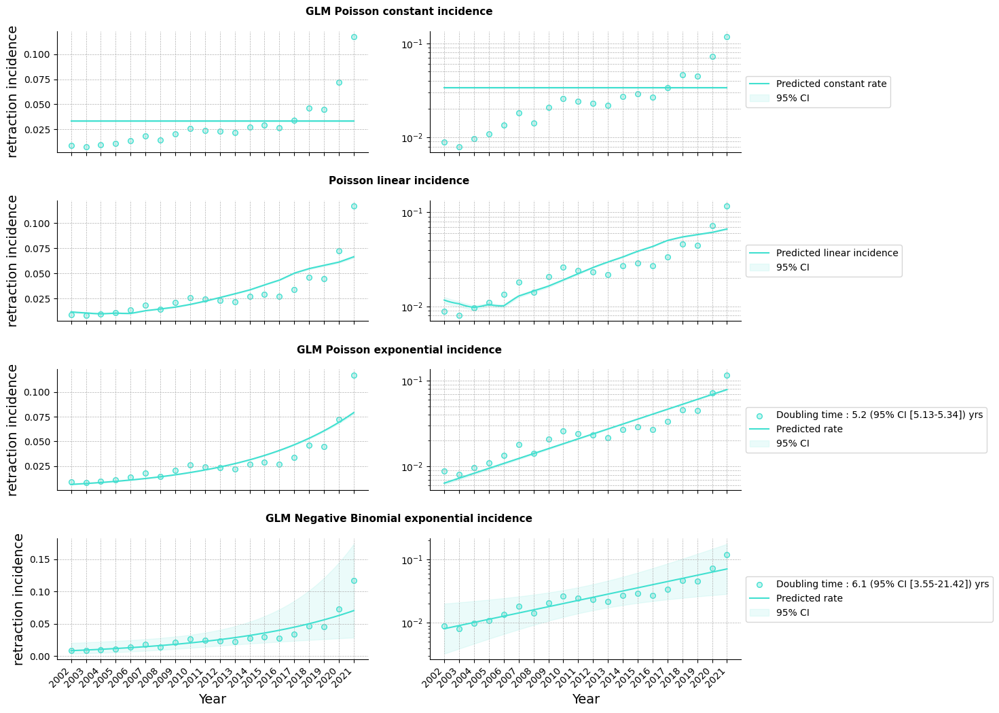

100%|██████████| 4/4 [00:03<00:00,  1.32it/s]


In [34]:
## fitting
ranges_list = [(1992,2021),(1992,2022),(1997,2021),(2002,2021)]
SCALE = 1e2
alpha=1
title = 'retraction incidence works'
results_ranges_df = pd.DataFrame()
for (start_year,end_year) in tqdm(ranges_list):
    df = works_retracted_count
    df = df[(df.year >= start_year) & (df.year <= end_year)]
    results_df_ = try_all_fit(SCALE,alpha,df,start_year,end_year,True,output_folder,title)
    results_ranges_df = pd.concat([results_ranges_df,results_df_])
results_ranges_df['range'] = results_ranges_df.apply(lambda x : (x['start year'], x['end year']), axis=1)

In [35]:
df = results_ranges_df[results_ranges_df.model!='GLM Negative Binomial exponential incidence']
df = df[['range','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df = df.sort_values(by=['range', 'model_order']).drop(columns='model_order')
df

,range,model,ΔBIC,ΔBIC_weighted
0,"(1992, 2021)",constant,19373.120536,0.000000e+00
0,"(1992, 2021)",linear,1508.027918,0.000000e+00
0,"(1992, 2021)",exponential,0.000000,1.000000e+00
0,"(1992, 2022)",constant,19373.120536,0.000000e+00
0,"(1992, 2022)",linear,1508.027918,0.000000e+00
0,"(1992, 2022)",exponential,0.000000,1.000000e+00
0,"(1997, 2021)",constant,16183.019670,0.000000e+00
0,"(1997, 2021)",linear,1471.484011,2.959947e-320
0,"(1997, 2021)",exponential,0.000000,1.000000e+00
0,"(2002, 2021)",constant,12544.311518,0.000000e+00


In [36]:
df = results_ranges_df[results_ranges_df.best_model==1][['range','b','p value b','doubling time','doubling_time_lower','doubling_time_upper']]
df = df.rename(columns={'b':'g','p value b':'p-value'})
df.head()

,range,g,p-value,doubling time,doubling_time_lower,doubling_time_upper
0,"(1992, 2021)",0.126112,2.778078e-09,5.496290,4.087659,8.386238
0,"(1992, 2022)",0.126112,2.778078e-09,5.496290,4.087659,8.386238
0,"(1997, 2021)",0.121417,1.257797e-05,5.708833,3.873895,10.846436
0,"(2002, 2021)",0.113902,3.341191e-03,6.085469,3.546421,21.423654


### Overdispersion test
alpha = 1 / r

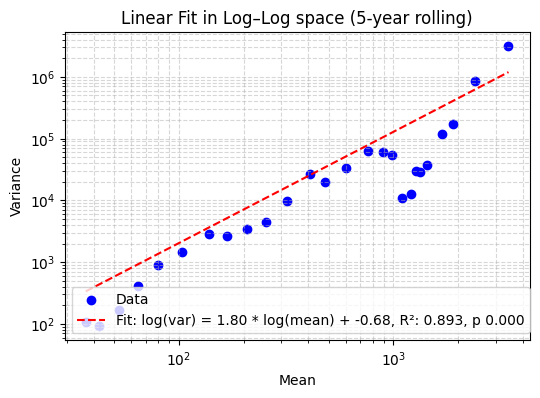

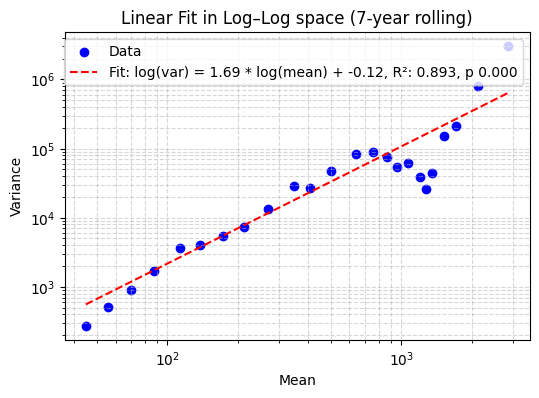

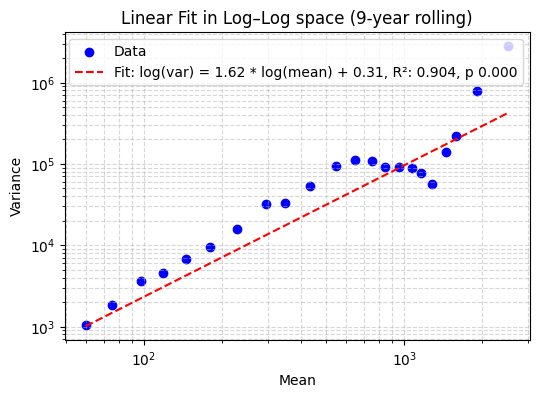

In [37]:
def objective(r):
    if r <= 0:
        return np.inf
    var_model = xdata + xdata**2 / r
    return np.sum((ydata - var_model)**2)
def power_law(x, a, b):
    return a * x**b

df = works_retracted_count.copy()
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)].reset_index(drop=True)   

for window_size in [5,7,9]:

    df_ = df.copy()
    df_['mean'] = df_.rolling(window=window_size).retracted.mean()
    df_['var'] = df_.rolling(window=window_size).retracted.var(ddof=0)
    df_clean = df_.dropna(subset=['mean', 'var'])
    xdata = df_clean['mean'].values
    ydata = df_clean['var'].values

    x = np.log10(xdata)
    y = np.log10(ydata)
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    x_fit = np.linspace(df_clean['mean'].min(), df_clean['mean'].max(), 200)
    y_fit = np.exp(intercept) * x_fit**slope

    popt, pcov = curve_fit(power_law, xdata, ydata, p0=[0.5, 1])  # initial guesses
    intercept2, slope2 = popt
    perr = np.sqrt(np.diag(pcov))
    n = len(ydata)
    tvals = popt / perr
    pvals = 2 * (1 - t.cdf(np.abs(tvals), n - len(popt)))
    p_value2 = pvals[1]
    y_fit2 = intercept2 * x_fit**slope2

    plt.figure(figsize=(6,4))
    plt.scatter(xdata, ydata, label='Data', color='blue')
    plt.plot(x_fit, y_fit, color='red', linestyle='--', label=f'Fit: log(var) = {slope:.2f} * log(mean) + {intercept:.2f}, R²: {r_value**2:.3f}, p {p_value:.3f}')
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Mean')
    plt.ylabel('Variance')
    plt.title(f'Linear Fit in Log–Log space ({window_size}-year rolling)')
    plt.legend()
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.show()

## Domains

Download OpenAlex topics hierarchy: https://docs.google.com/spreadsheets/d/1v-MAq64x4YjhO7RWcB-yrKV5D_2vOOsxl4u6GBKEXY8/edit?gid=983250122#gid=983250122

In [38]:
df_topics = pd.read_csv('OpenAlex_topic_mapping_table - final_topic_field_subfield_table.csv')
df_topics = df_topics.sort_values(by=['topic_id','subfield_id','field_id','domain_id']) #rescale topics
df_topics = df_topics.sort_values(by=['domain_id','field_id','subfield_id','topic_id']).reset_index(drop=True)
df_topics = df_topics.reset_index().rename(columns={'index':'topic_id_scaled'})
df_topics['subfield_id_scaled'] = pd.factorize(df_topics.subfield_id)[0]
df_topics['field_id_scaled'] = pd.factorize(df_topics.field_id)[0]
df_topics['domain_id_scaled'] = pd.factorize(df_topics.domain_id)[0]

topic_id_name_dict = df_topics[['topic_id','topic_name']].set_index('topic_id').to_dict()['topic_name']
domain_id_name_dict = df_topics[['domain_id','domain_name']].drop_duplicates().set_index('domain_id').to_dict()['domain_name']
field_id_name_dict = df_topics[['field_id','field_name']].drop_duplicates().set_index('field_id').to_dict()['field_name']
subfield_id_name_dict = df_topics[['subfield_id','subfield_name']].drop_duplicates().set_index('subfield_id').to_dict()['subfield_name']

set_topics = set(df_topics.topic_id)
set_subfields = set(df_topics.subfield_id)
set_fields = set(df_topics.field_id)
set_domains = set(df_topics.domain_id)

n_topics = len(set_topics)
n_subfields = len(set_subfields)
n_fields = len(set_fields)
n_domains = len(set_domains)
print(f'{n_topics} topics, {n_subfields} subfields, {n_fields} fields, {n_domains} domains')

topic_id_list = list(df_topics.topic_id_scaled)

dict_topics_id_scaled = df_topics[['topic_id','topic_id_scaled']].set_index('topic_id').to_dict()['topic_id_scaled']
dict_subfield_id_scaled = df_topics[['subfield_id','subfield_id_scaled']].set_index('subfield_id').to_dict()['subfield_id_scaled']
dict_field_id_scaled = df_topics[['field_id','field_id_scaled']].set_index('field_id').to_dict()['field_id_scaled']
dict_field_id_scaled2 = df_topics[['field_id','field_id_scaled']].set_index('field_id_scaled').to_dict()['field_id']
dict_domains_id_scaled = df_topics[['domain_id','domain_id_scaled']].set_index('domain_id').to_dict()['domain_id_scaled']
topic_id_scaled_name_dict = df_topics[['topic_id_scaled','topic_name']].set_index('topic_id_scaled').to_dict()['topic_name']
subfield_id_scaled_name_dict = df_topics[['subfield_id_scaled','subfield_name']].drop_duplicates().set_index('subfield_id_scaled').to_dict()['subfield_name']
field_id_scaled_name_dict = df_topics[['field_id_scaled','field_name']].drop_duplicates().set_index('field_id_scaled').to_dict()['field_name']
field_name_id_dict = df_topics[['field_id','field_name']].drop_duplicates().set_index('field_name').to_dict()['field_id']
domain_id_scaled_name_dict = df_topics[['domain_id_scaled','domain_name']].drop_duplicates().set_index('domain_id_scaled').to_dict()['domain_name']
field_name_domain_name_dict = df_topics[['field_name','domain_name']].drop_duplicates().set_index('field_name').to_dict()['domain_name']

field_topic_indices = df_topics[['topic_id_scaled','field_id_scaled']].groupby('field_id_scaled').topic_id_scaled.apply(set).to_dict()
subfield_topic_indices = df_topics[['topic_id_scaled','subfield_id_scaled']].groupby('subfield_id_scaled').topic_id_scaled.apply(set).to_dict()

4516 topics, 252 subfields, 26 fields, 4 domains


In [ ]:
sql = """
  CREATE TABLE `project_name.dataset_name.works_retracted_count_byfield` AS

  WITH works_topics_filtered AS (
    SELECT
      publication_year,
      is_retracted,
      work_id,
      field_id
    FROM
      `project_name.dataset_name.works_topics`
    WHERE
      publication_year BETWEEN '1992-01-01' AND '2021-01-01'
  ),

  -- Count number of fields per work (to weight each work by 1 / number_of_fields)
  fields_per_work AS (
    SELECT
      work_id,
      COUNT(DISTINCT field_id) AS num_fields
    FROM
      works_topics_filtered
    GROUP BY work_id
    HAVING COUNT(DISTINCT field_id) > 0 
  ),

  -- Join back to assign weight per work-field combination
  works_weighted AS (
    SELECT
      w.publication_year,
      w.field_id,
      w.is_retracted,
      1.0 / fpw.num_fields AS work_field_weight
    FROM
      works_topics_filtered w
    JOIN
      fields_per_work fpw
    ON
      w.work_id = fpw.work_id
  )

  -- Final aggregation by year and field
  SELECT
    publication_year,
    field_id,
    SUM(work_field_weight) AS total_weight,
    SUM(CASE WHEN is_retracted = 1 THEN work_field_weight ELSE 0 END) AS retracted_weight
  FROM
    works_weighted
  GROUP BY
    publication_year,
    field_id
  ORDER BY
    publication_year,
    field_id;
"""
##output info
new_table_name = "works_retracted_count_byfield"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)

In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
output_folder = './Plots/plots_domains'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

In [ ]:
works_retracted_count_bydomain = pd.read_csv(f'./Data/works_retracted_count_byfield.csv.gz', compression='gzip').rename(columns={'publication_year':'year'}).dropna()
works_retracted_count_bydomain['year'] = works_retracted_count_bydomain['year'].str[:4].astype(int)
works_retracted_count_bydomain = works_retracted_count_bydomain.merge(df_topics[['field_id','domain_id']].drop_duplicates(),on='field_id').drop(columns='field_id')
works_retracted_count_bydomain = works_retracted_count_bydomain.groupby(['domain_id','year']).sum().reset_index()
works_retracted_count_bydomain = works_retracted_count_bydomain.rename(columns={'total_weight':'total','retracted_weight':'retracted'})
works_retracted_count_bydomain = works_retracted_count_bydomain.merge(df_topics[['domain_id','domain_name']].drop_duplicates(),on='domain_id')
works_retracted_count_bydomain = works_retracted_count_bydomain[['domain_name','domain_id','year','total','retracted']].sort_values(by=['domain_name','year'])
works_retracted_count_bydomain = works_retracted_count_bydomain[(works_retracted_count_bydomain.year>=1980) & (works_retracted_count_bydomain.year<=2024)].reset_index(drop=True)

  0%|          | 0/4 [00:00<?, ?it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


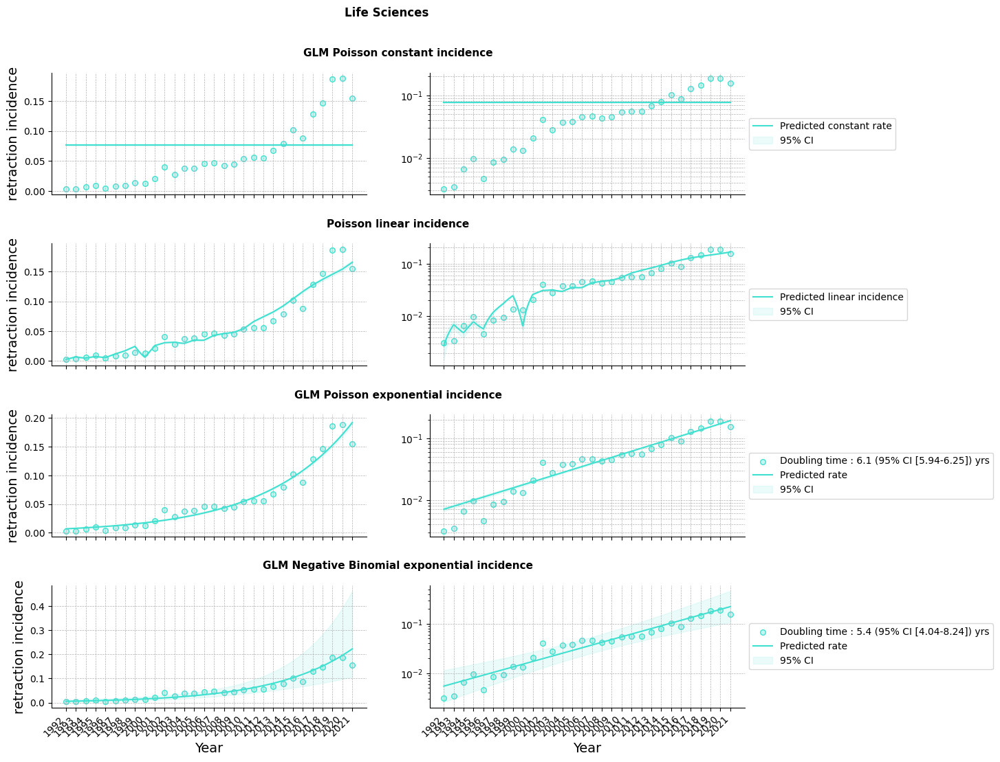

 25%|██▌       | 1/4 [00:00<00:02,  1.17it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


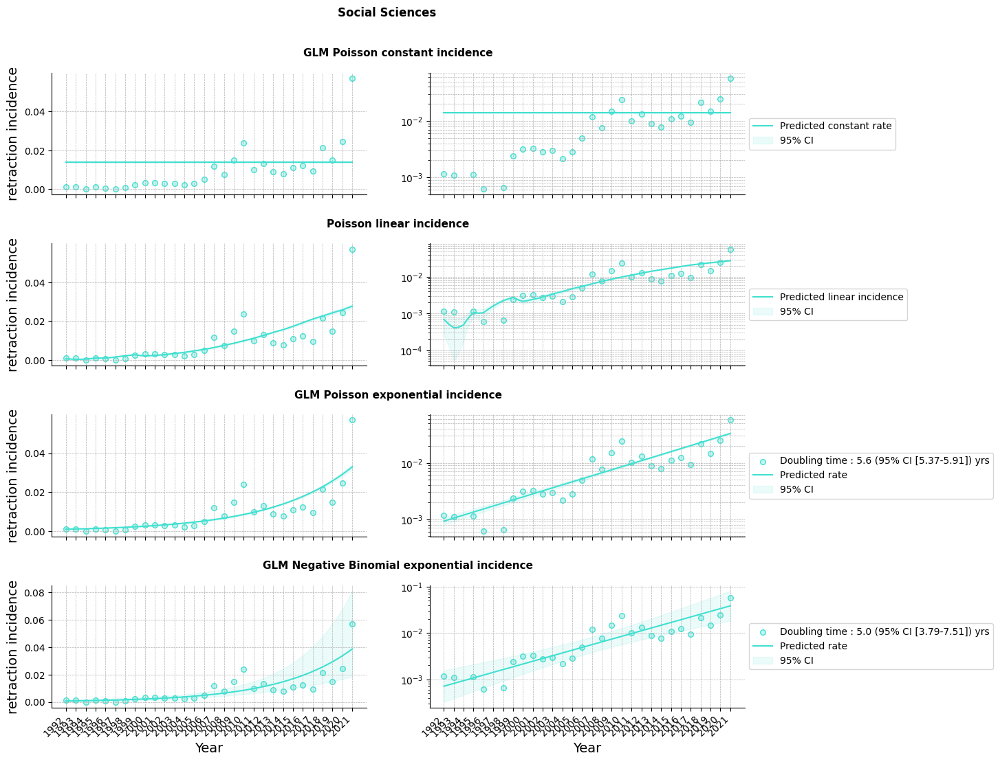

 50%|█████     | 2/4 [00:01<00:01,  1.19it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


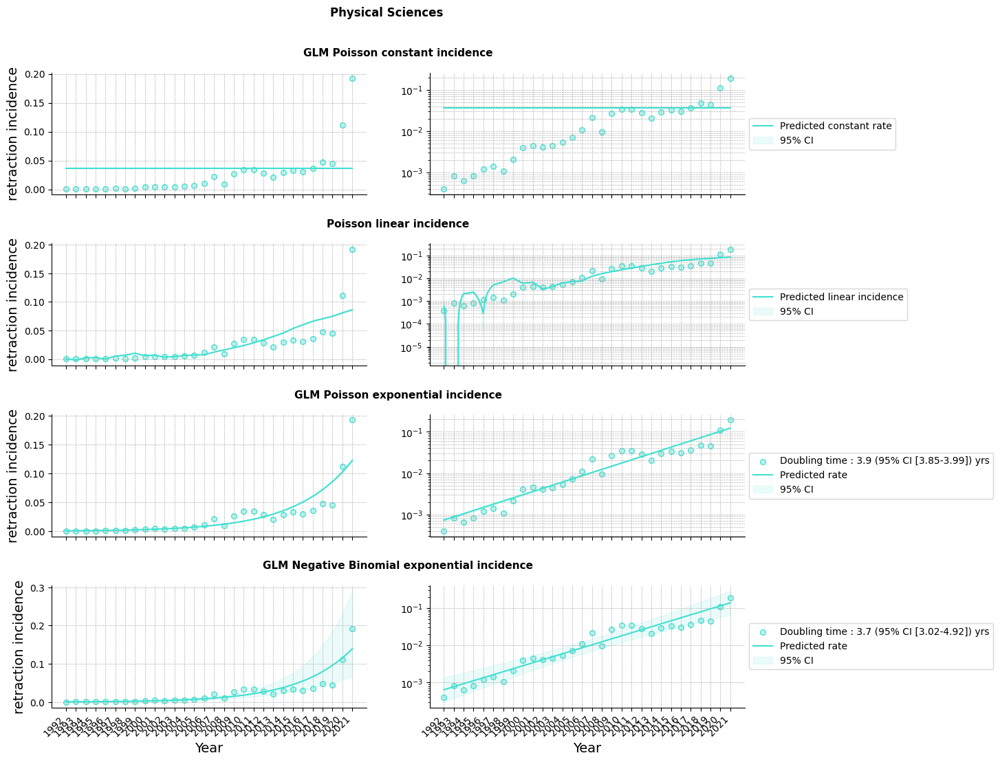

 75%|███████▌  | 3/4 [00:02<00:00,  1.16it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


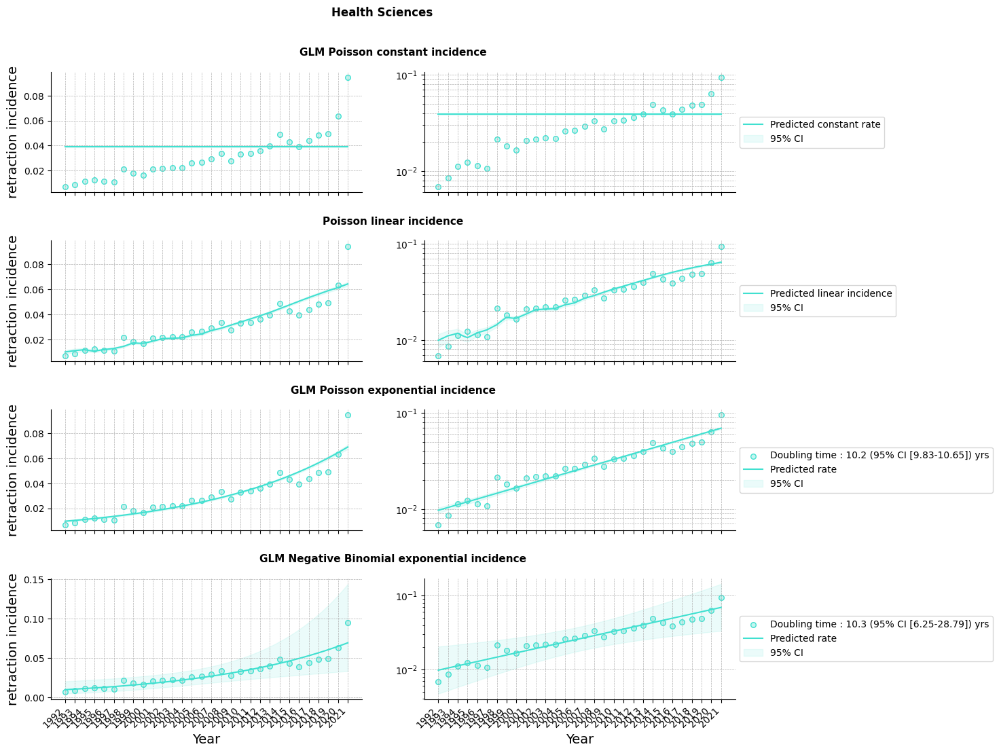

100%|██████████| 4/4 [00:03<00:00,  1.21it/s]


In [41]:
SCALE = 1e2
alpha=1
df = works_retracted_count_bydomain.copy()
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
title = 'retraction incidence works'
results_domains_df = pd.DataFrame()
for i in tqdm(range(1,n_domains+1)):
    df_i = df[df.domain_id==i]
    results_df = try_all_fit(SCALE,alpha,df_i,start_year,end_year,True,output_folder,title,domain_id_name_dict,i)
    results_domains_df = pd.concat([results_domains_df,results_df])
results_domains_df = results_domains_df.rename(columns={'field_id_scaled':'domain_id','field_name':'domain_name'})

In [42]:
df = results_domains_df[results_domains_df.model!='GLM Negative Binomial exponential incidence']
df = df[['domain_name','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df = df.sort_values(by=['domain_name', 'model_order']).drop(columns='model_order')
df

,domain_name,model,ΔBIC,ΔBIC_weighted
0,Health Sciences,constant,3110.682388,0.000000e+00
0,Health Sciences,linear,110.120592,1.223537e-24
0,Health Sciences,exponential,0.000000,1.000000e+00
0,Life Sciences,constant,8263.036879,0.000000e+00
0,Life Sciences,linear,71.638072,2.779651e-16
0,Life Sciences,exponential,0.000000,1.000000e+00
0,Physical Sciences,constant,20614.718246,0.000000e+00
0,Physical Sciences,exponential,0.000000,1.000000e+00
0,Social Sciences,constant,2621.943912,0.000000e+00
0,Social Sciences,linear,188.921549,9.466882e-42


In [43]:
df = results_domains_df[results_domains_df.best_model==1][['domain_name','b','p value b','doubling time','doubling_time_lower','doubling_time_upper']]
df = df.rename(columns={'b':'g','p value b':'p-value'}).sort_values(by='domain_name')
df

,domain_name,g,p-value,doubling time,doubling_time_lower,doubling_time_upper
0,Health Sciences,0.067479,1.449304e-03,10.272026,6.251183,28.790372
0,Life Sciences,0.127789,1.976092e-09,5.424162,4.043613,8.236084
0,Physical Sciences,0.185340,1.155585e-17,3.739869,3.017542,4.916843
0,Social Sciences,0.137611,5.157826e-10,5.036995,3.788263,7.513775


## Fields

Look at Domains for BigQuery query.

In [ ]:
output_folder = './Plots/plots_fields'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

In [ ]:
works_retracted_count_byfield = pd.read_csv(f'./Data/works_retracted_count_byfield.csv.gz', compression='gzip').rename(columns={'publication_year':'year'}).dropna()
works_retracted_count_byfield['year'] = works_retracted_count_byfield['year'].str[:4].astype(int)
works_retracted_count_byfield['field_id'] = works_retracted_count_byfield['field_id'].astype(int)
works_retracted_count_byfield['field_id_scaled'] = works_retracted_count_byfield['field_id'].map(dict_field_id_scaled)
works_retracted_count_byfield = works_retracted_count_byfield.rename(columns={'total_weight':'total','retracted_weight':'retracted'})

  0%|          | 0/26 [00:00<?, ?it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


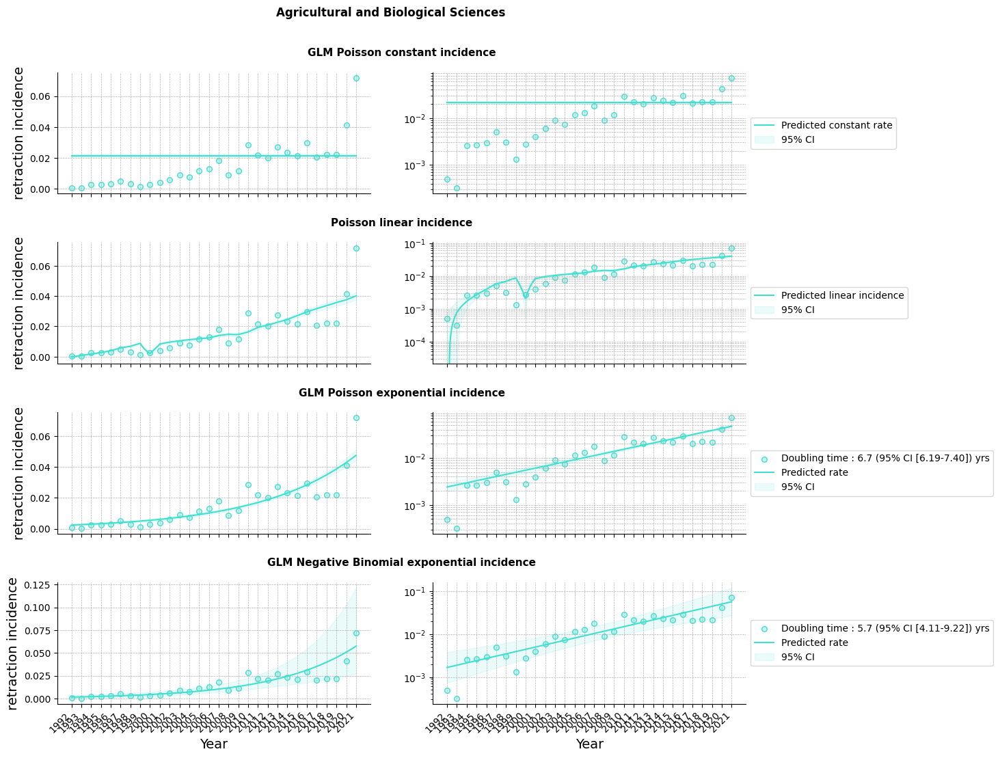

  4%|▍         | 1/26 [00:00<00:22,  1.13it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


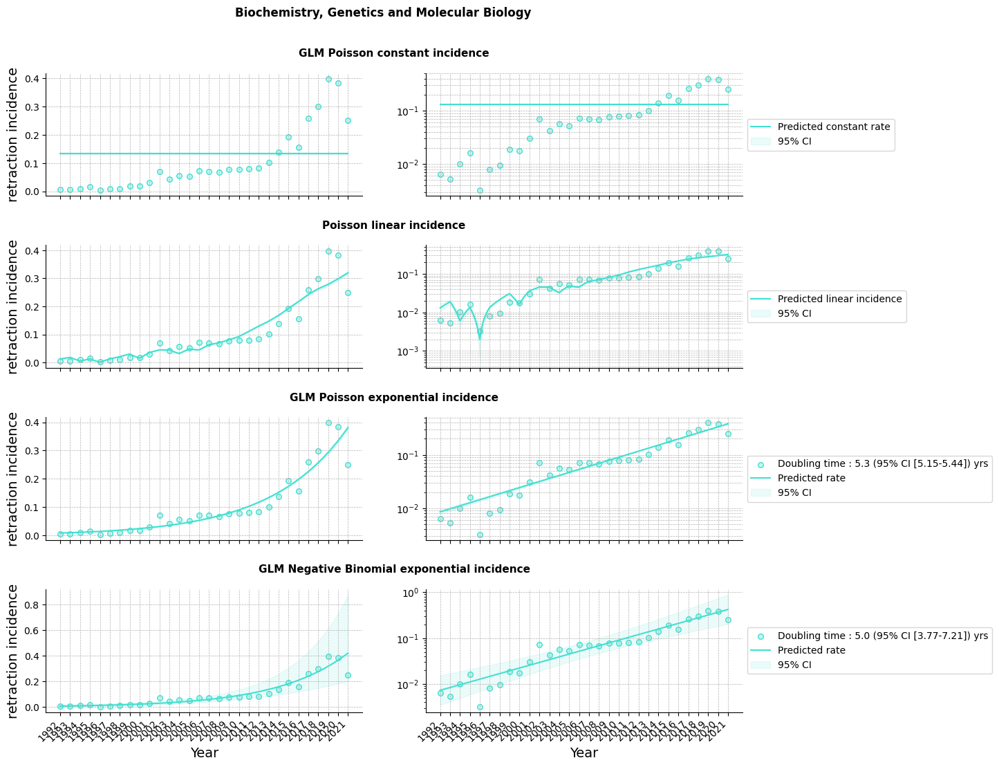

  8%|▊         | 2/26 [00:01<00:20,  1.15it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


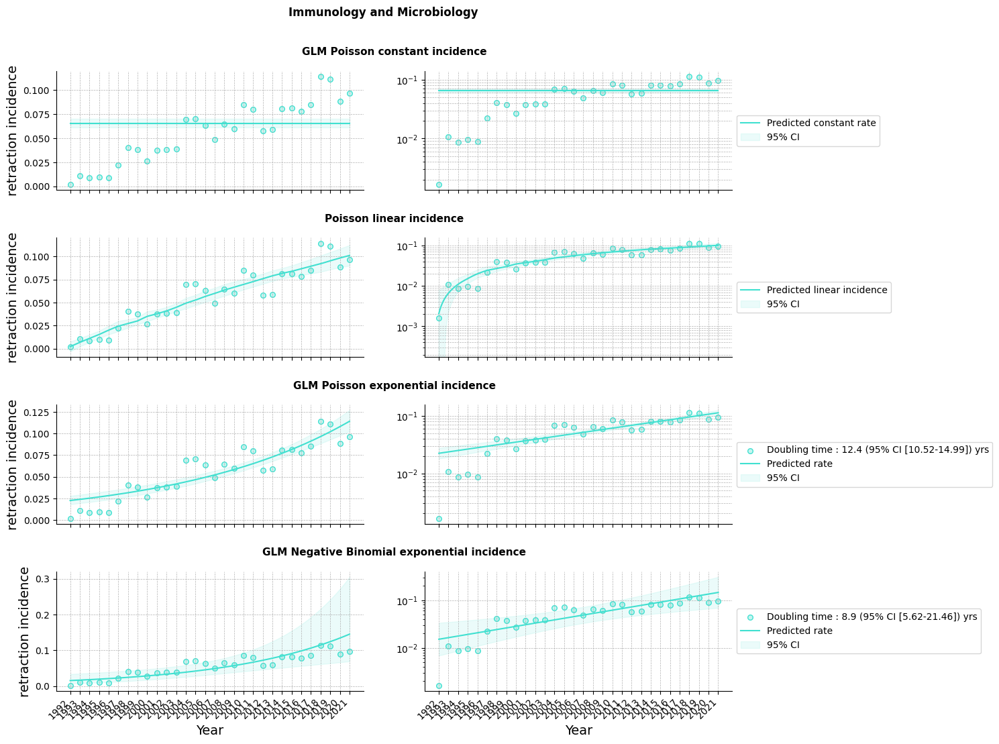

 12%|█▏        | 3/26 [00:02<00:19,  1.17it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


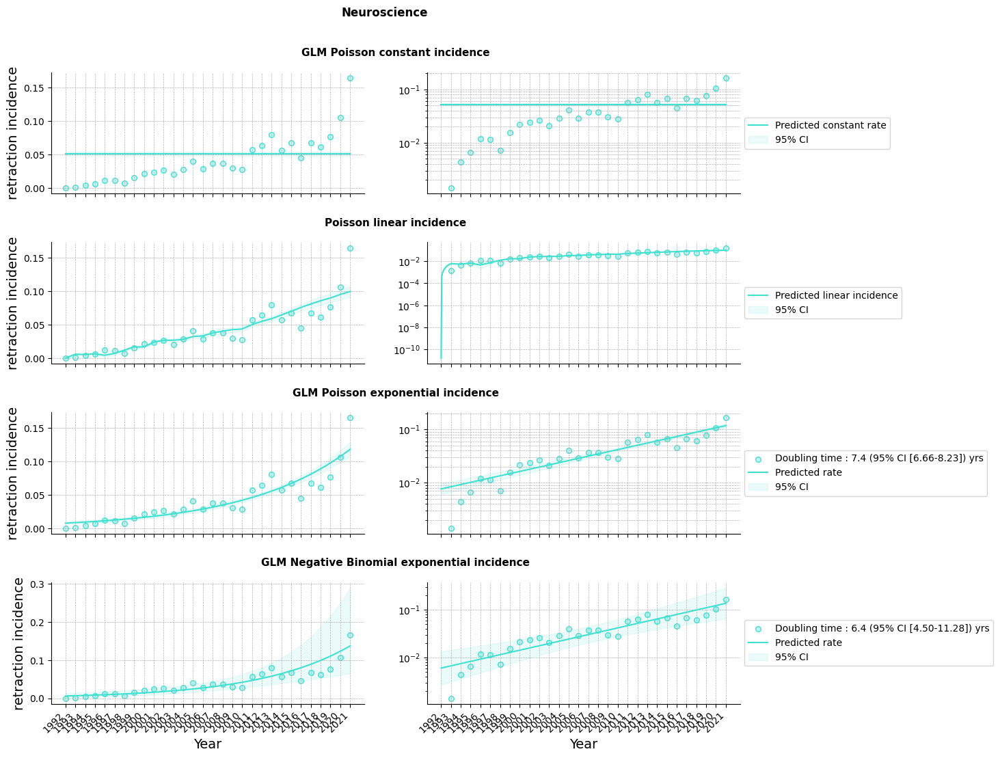

 15%|█▌        | 4/26 [00:03<00:17,  1.22it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


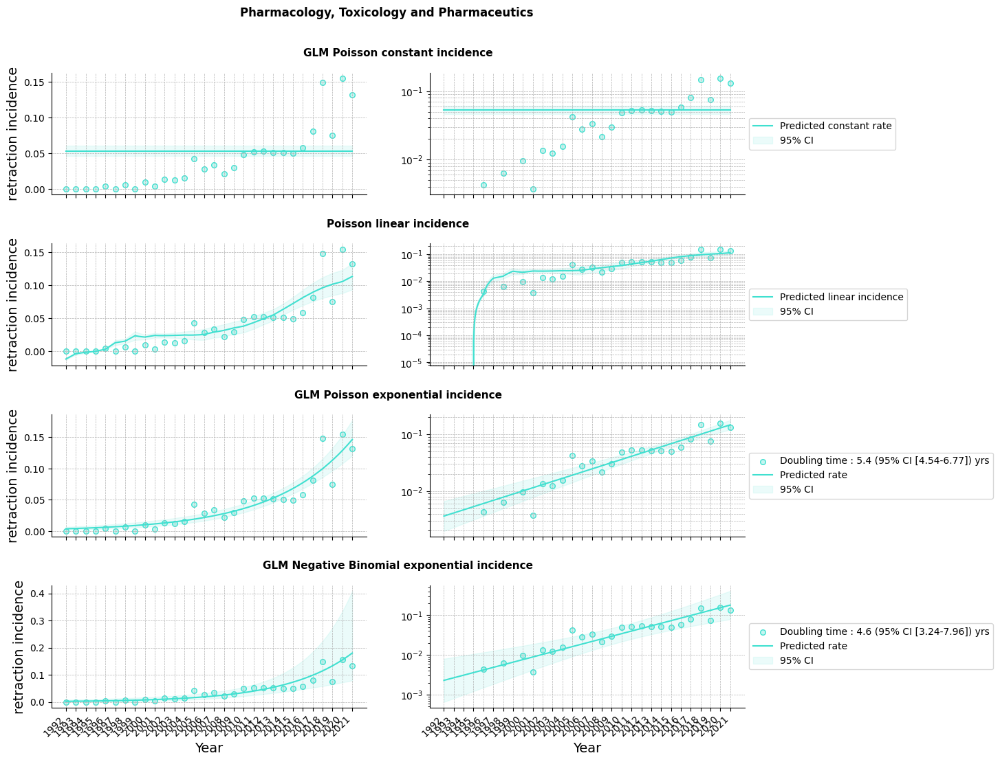

 19%|█▉        | 5/26 [00:04<00:17,  1.20it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


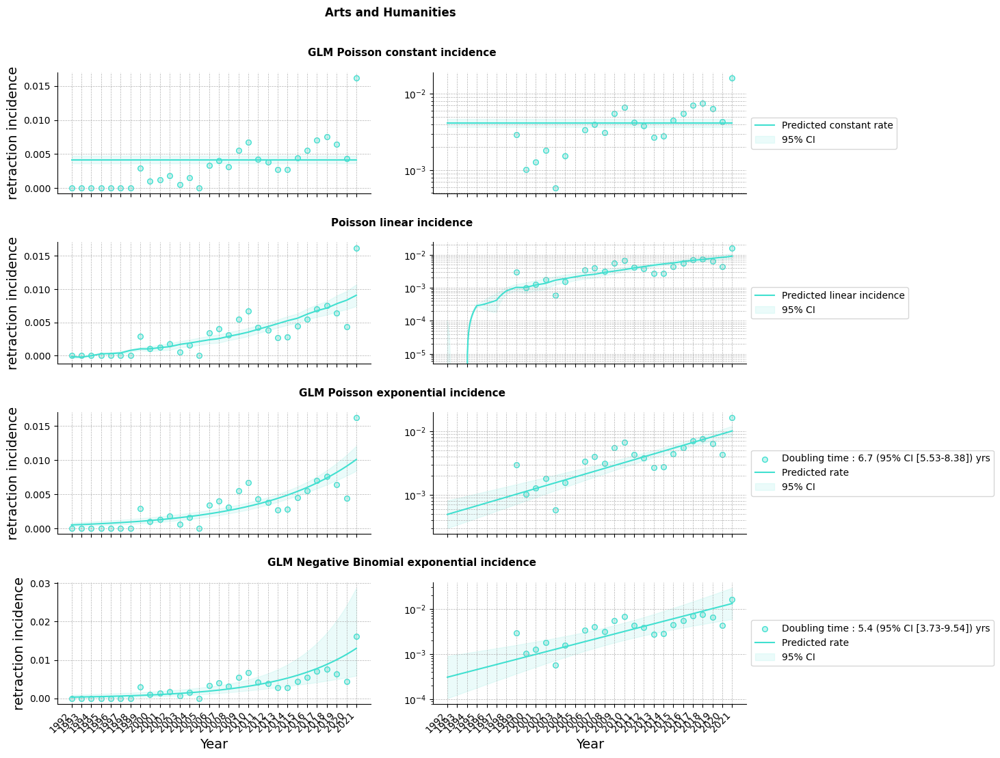

 23%|██▎       | 6/26 [00:05<00:16,  1.19it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


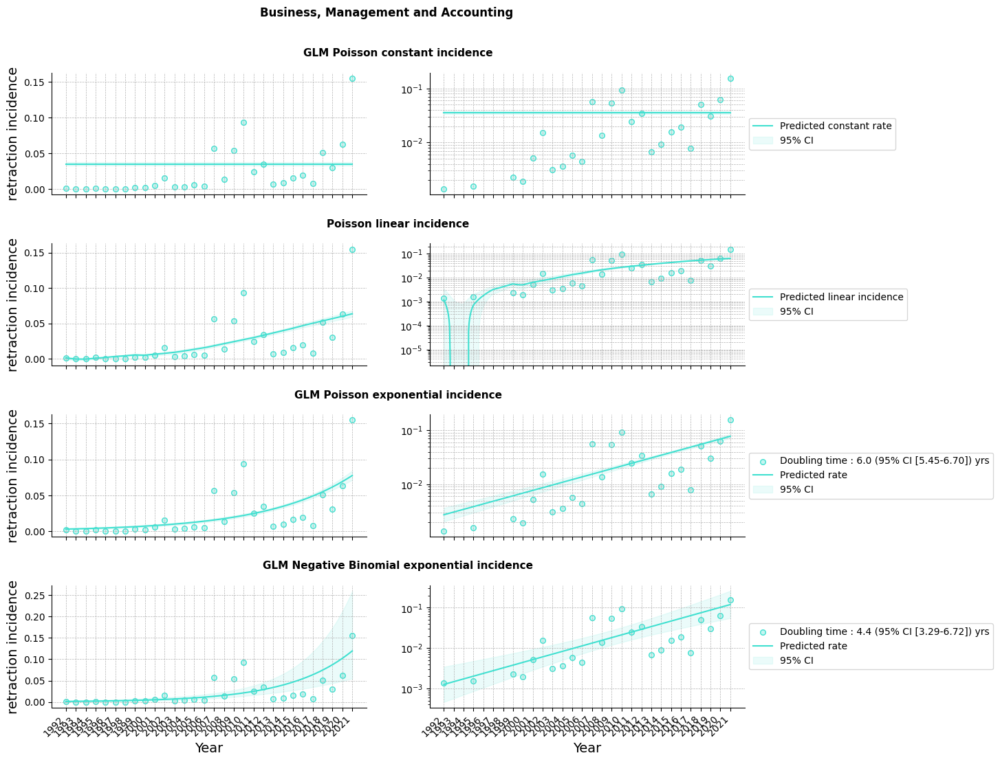

 27%|██▋       | 7/26 [00:05<00:16,  1.18it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


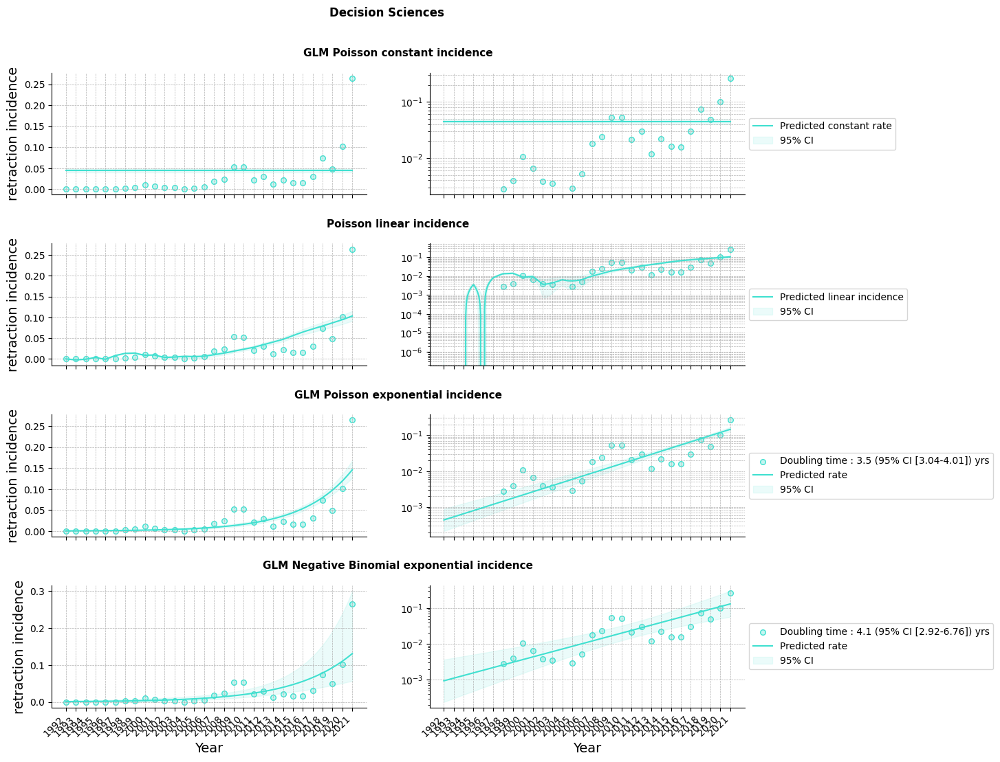

 31%|███       | 8/26 [00:06<00:15,  1.16it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


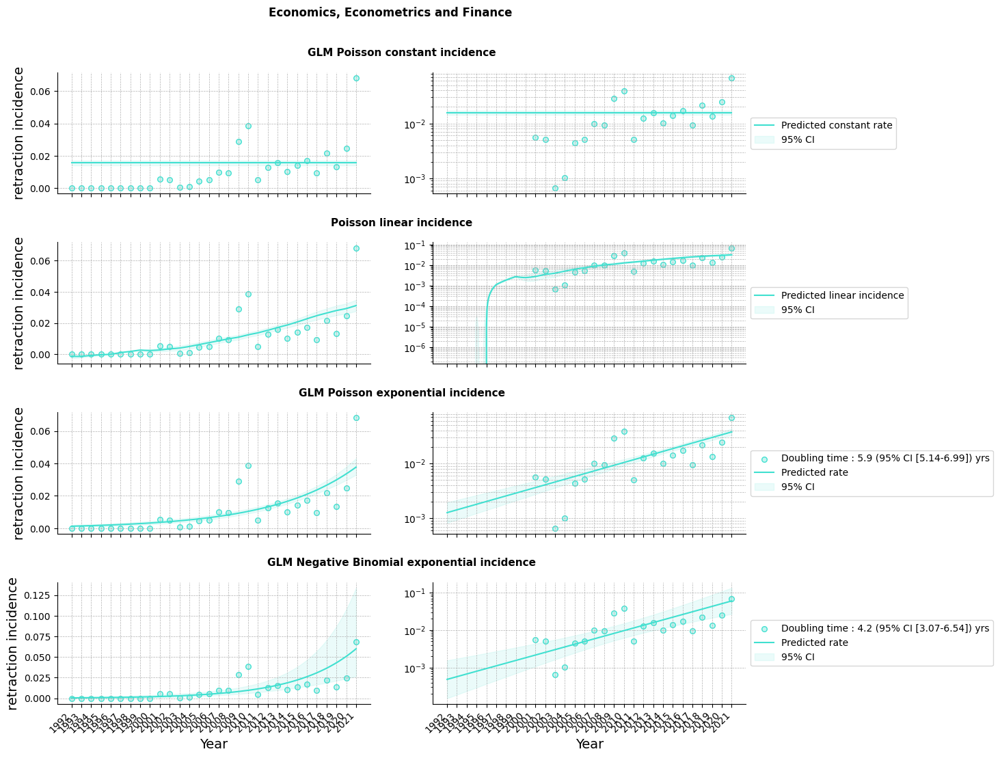

 35%|███▍      | 9/26 [00:07<00:14,  1.15it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


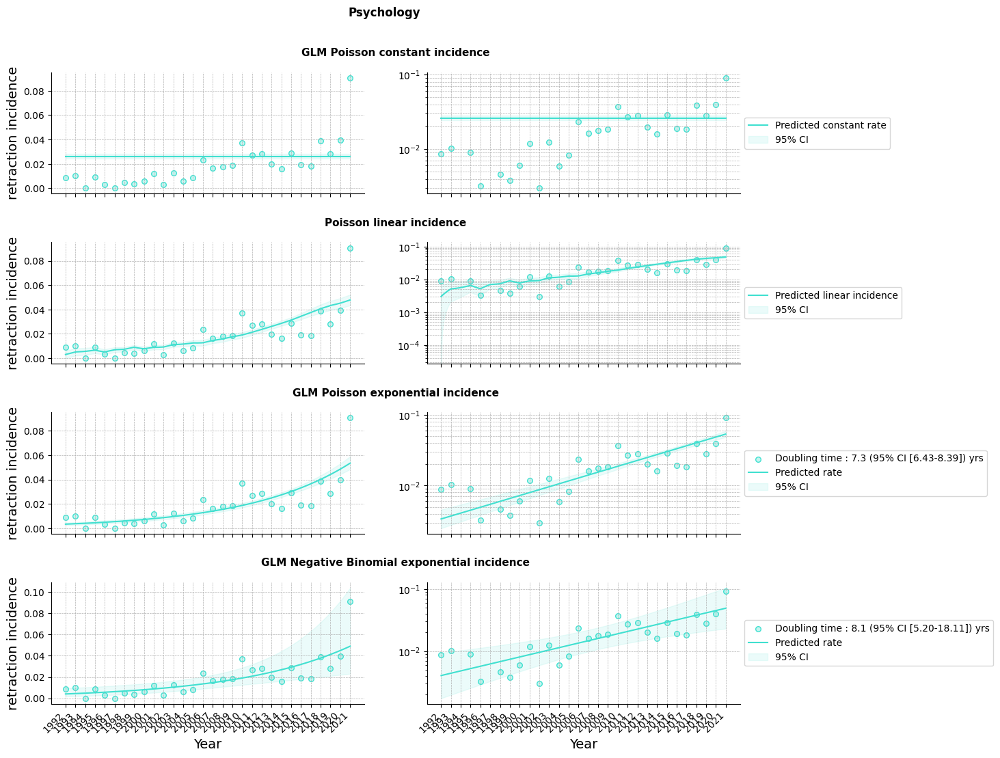

 38%|███▊      | 10/26 [00:08<00:13,  1.18it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


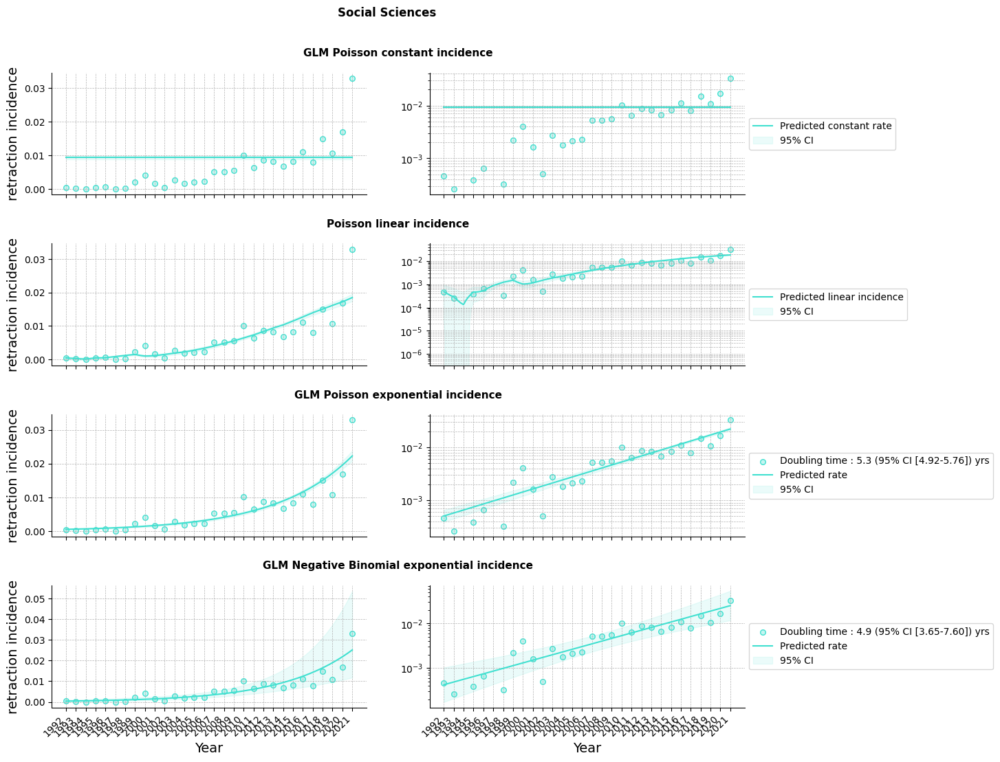

 42%|████▏     | 11/26 [00:09<00:12,  1.16it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


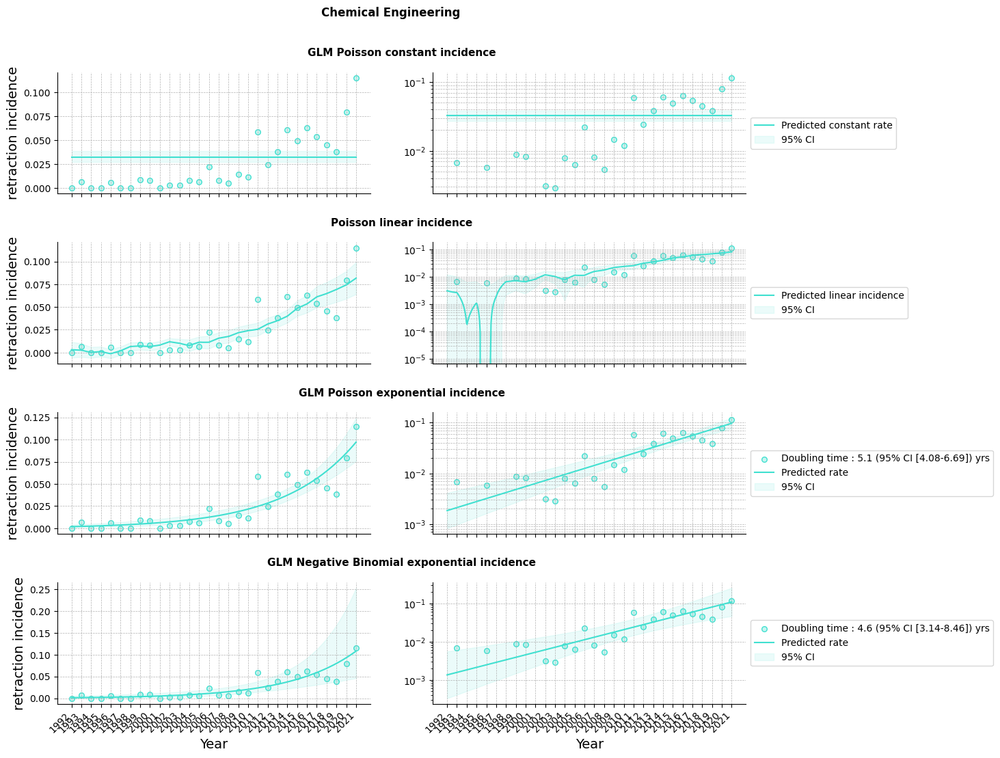

 46%|████▌     | 12/26 [00:10<00:12,  1.14it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


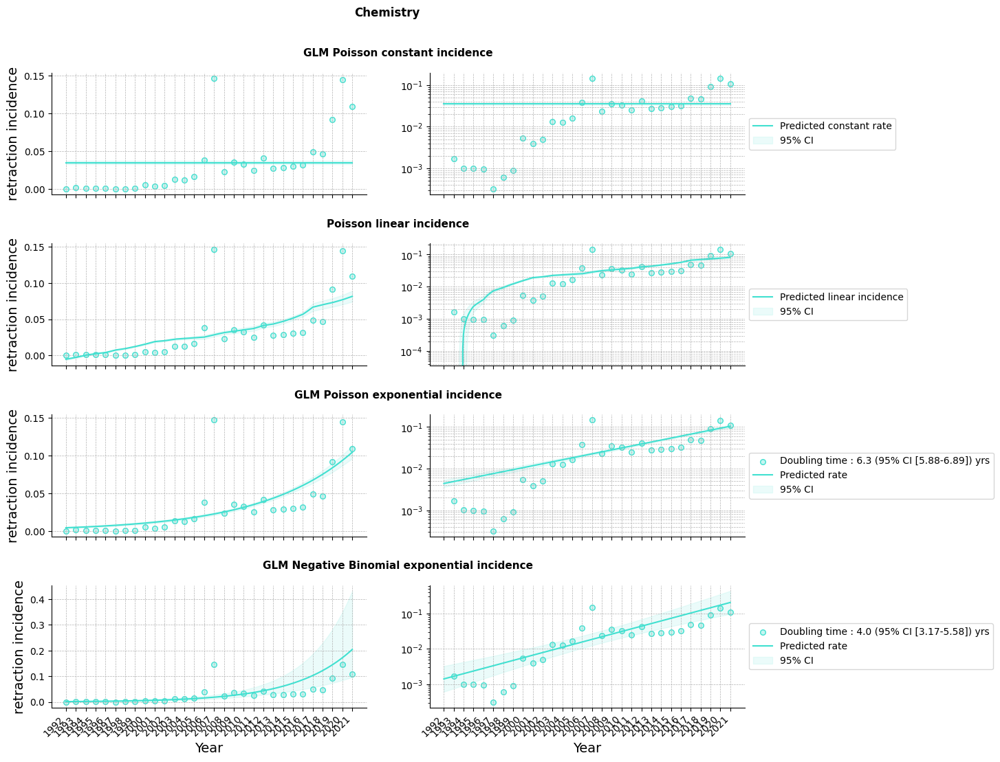

 50%|█████     | 13/26 [00:11<00:11,  1.14it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


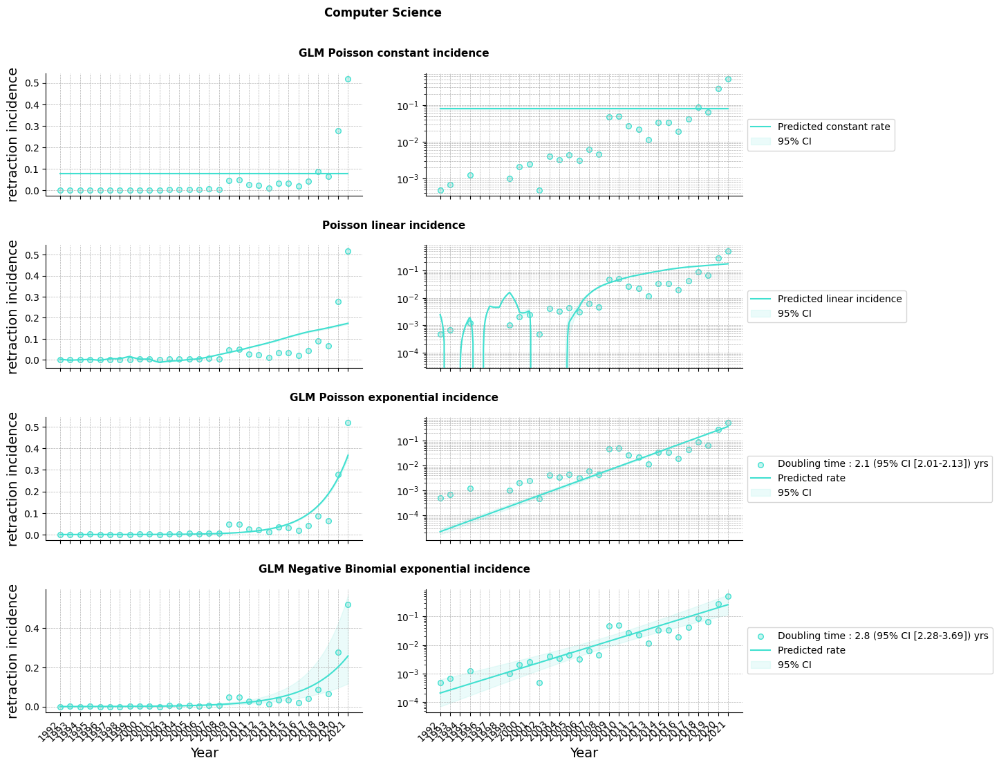

 54%|█████▍    | 14/26 [00:12<00:10,  1.13it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


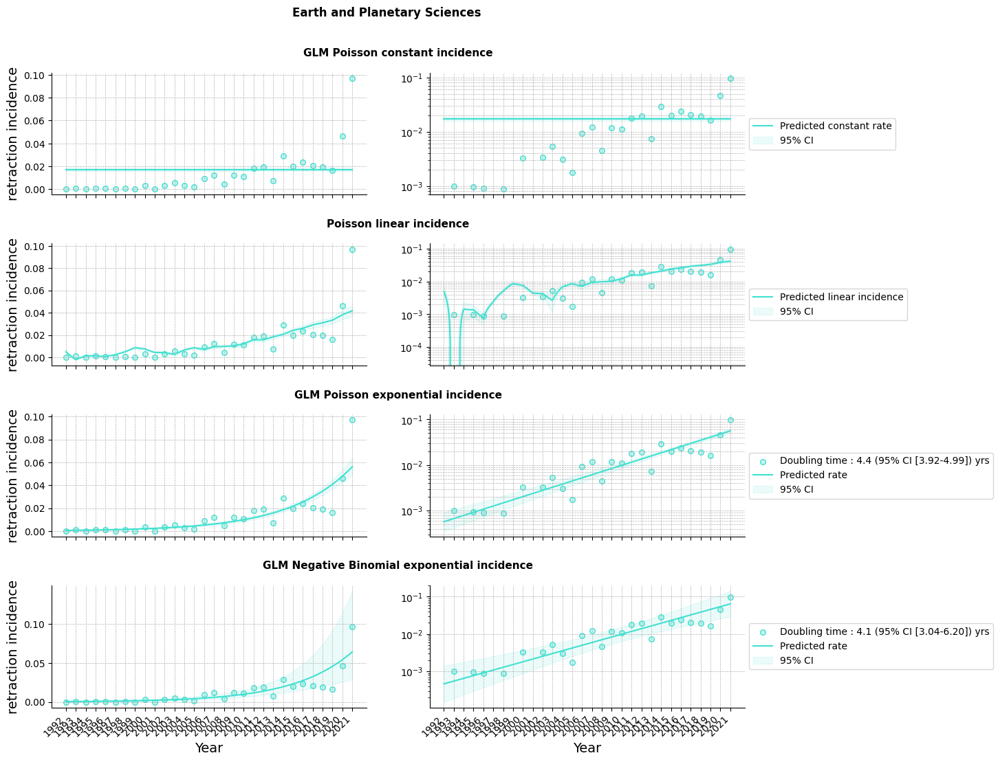

 58%|█████▊    | 15/26 [00:12<00:09,  1.13it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


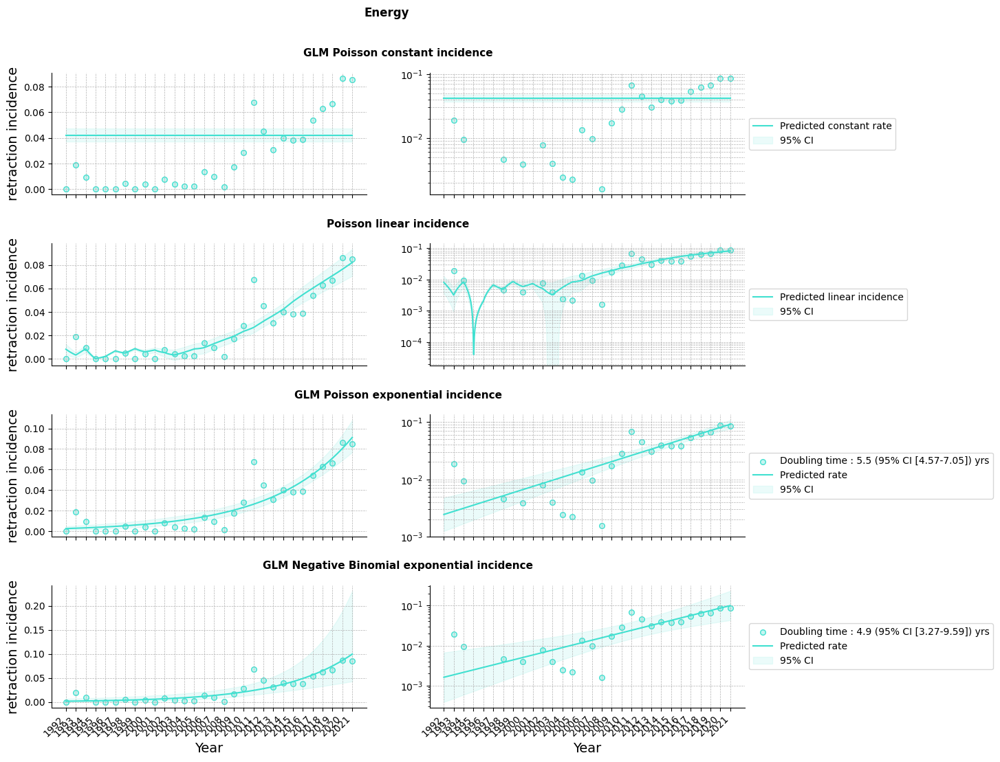

 62%|██████▏   | 16/26 [00:13<00:08,  1.14it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


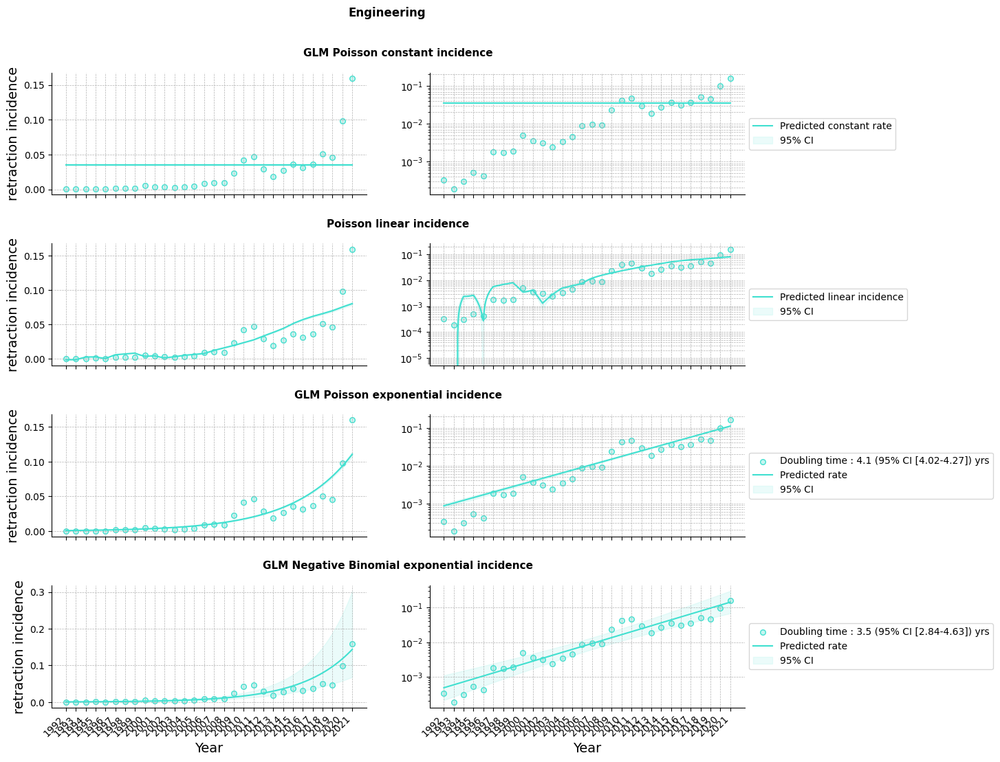

 65%|██████▌   | 17/26 [00:14<00:07,  1.15it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


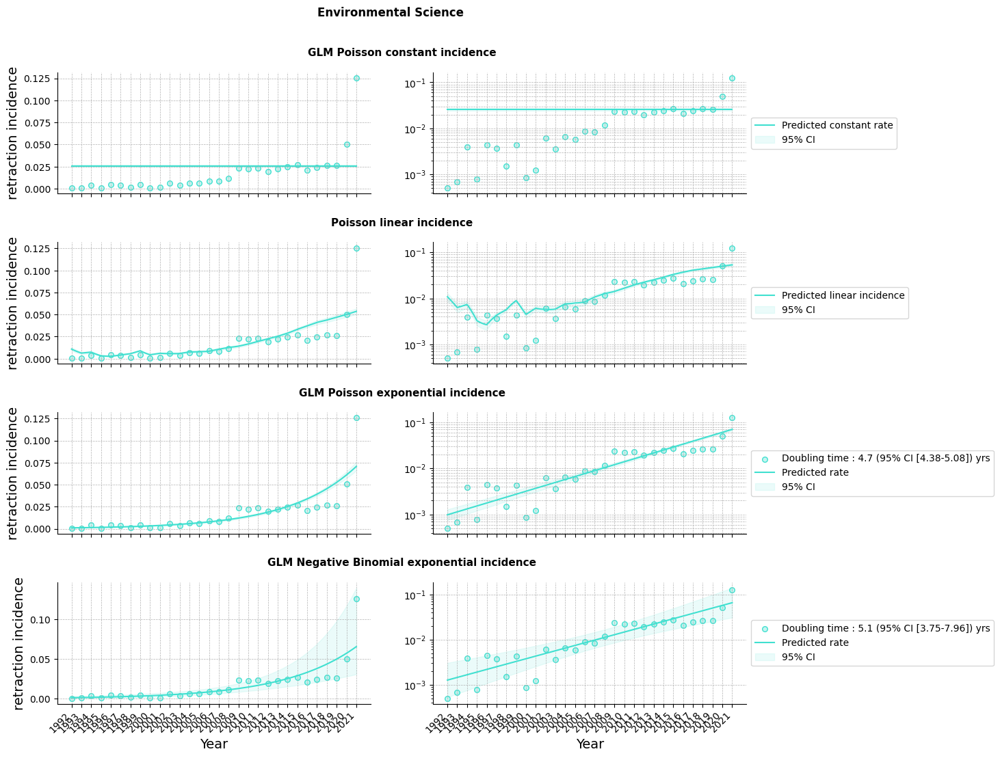

 69%|██████▉   | 18/26 [00:15<00:06,  1.15it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


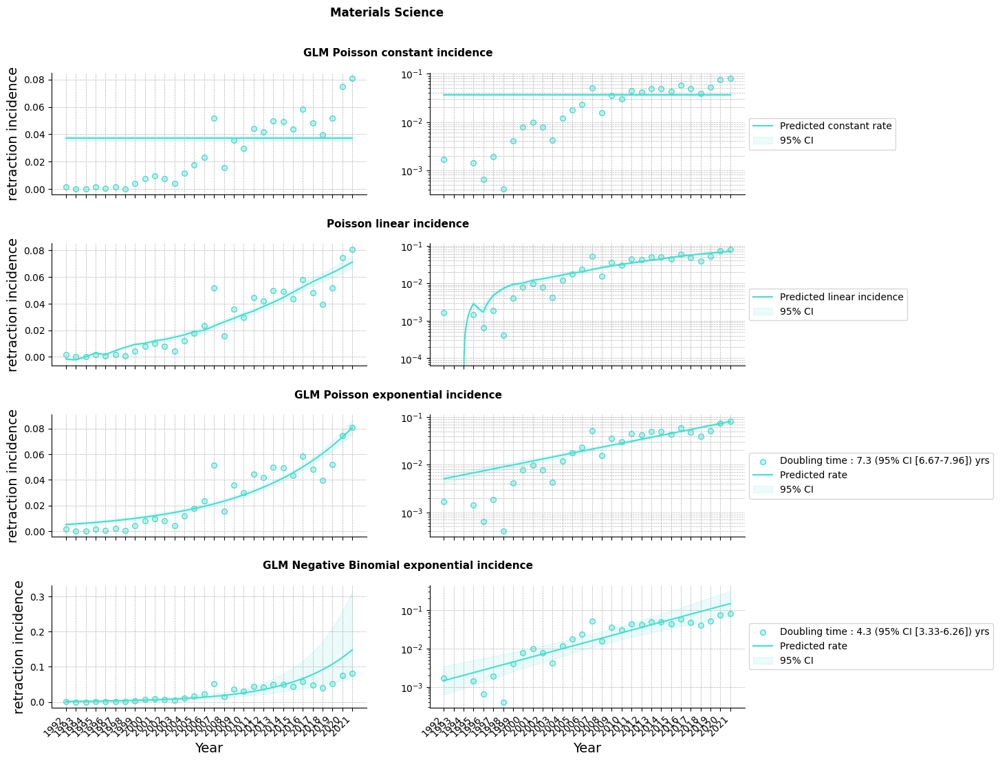

 73%|███████▎  | 19/26 [00:16<00:06,  1.13it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


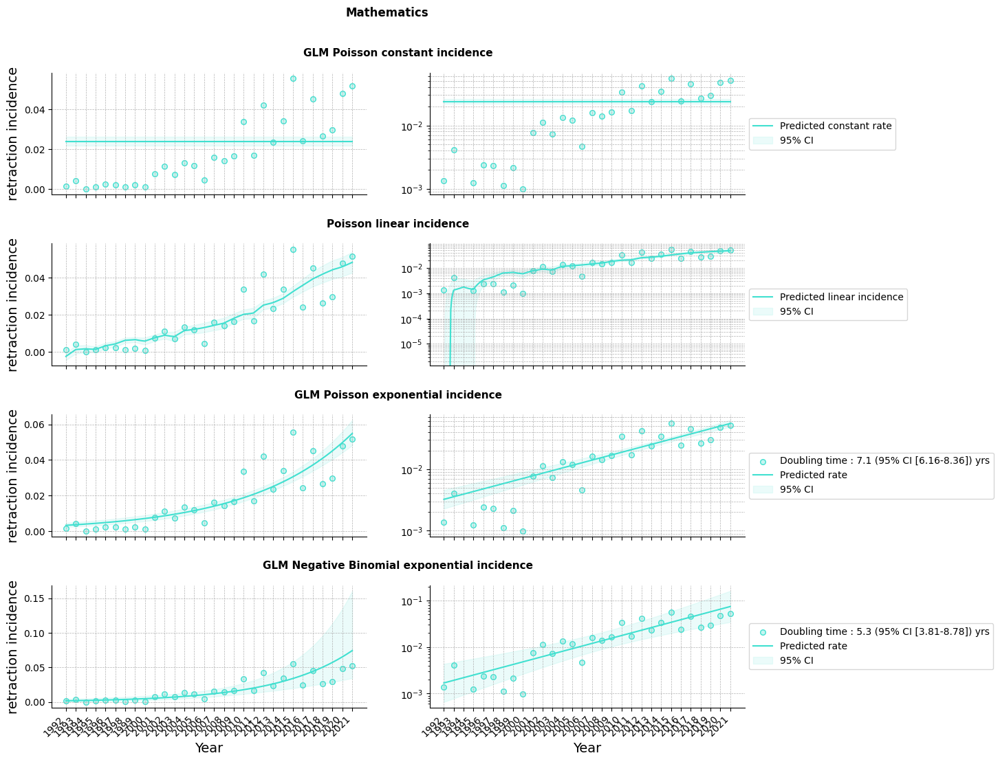

 77%|███████▋  | 20/26 [00:17<00:05,  1.15it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


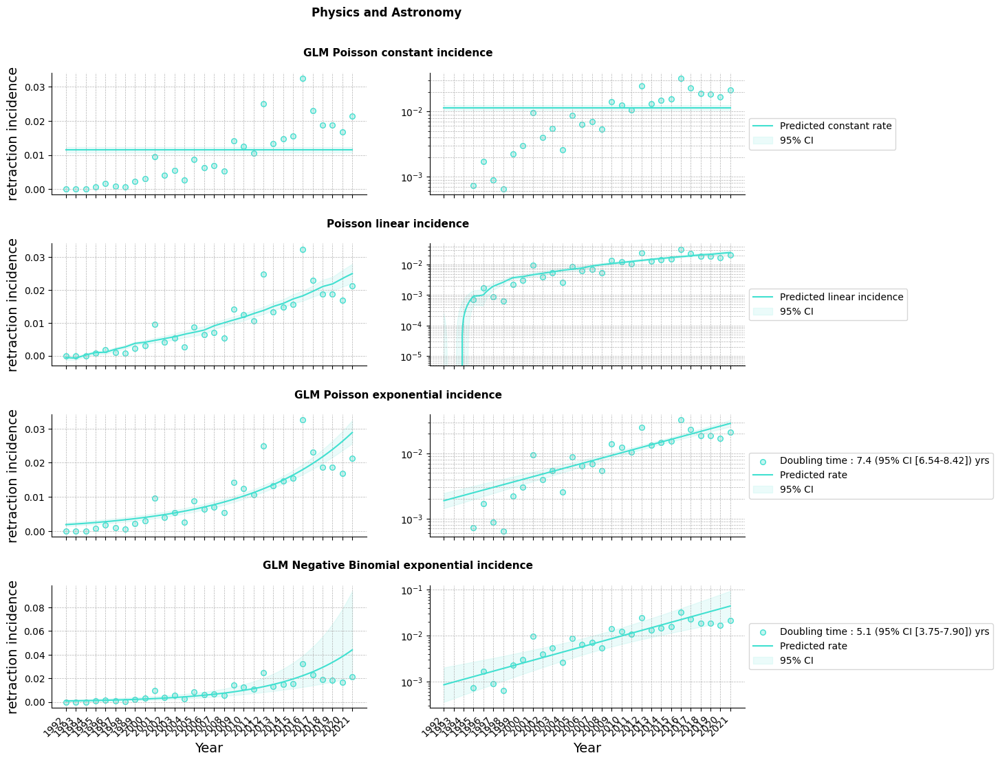

 81%|████████  | 21/26 [00:18<00:04,  1.15it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


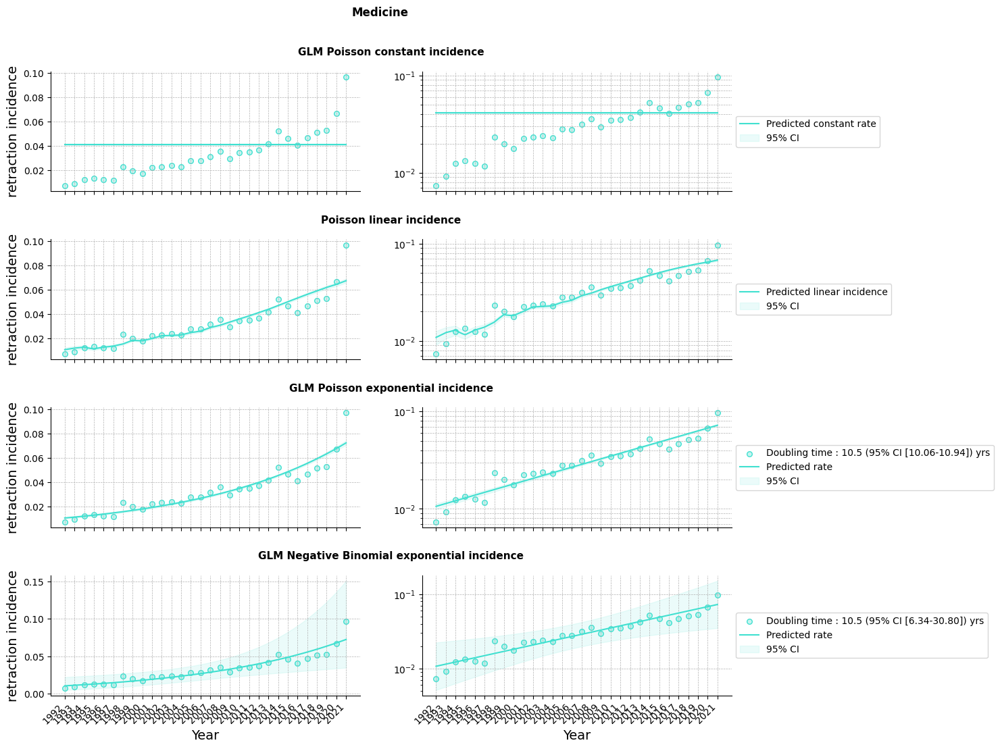

 85%|████████▍ | 22/26 [00:19<00:03,  1.17it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


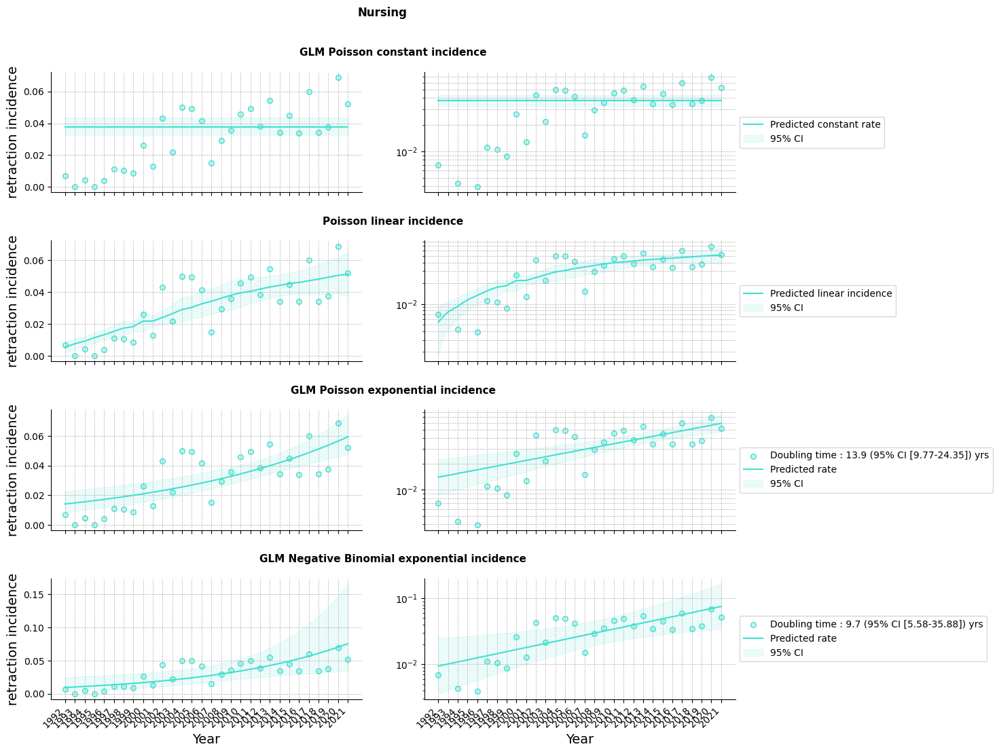

 88%|████████▊ | 23/26 [00:19<00:02,  1.21it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


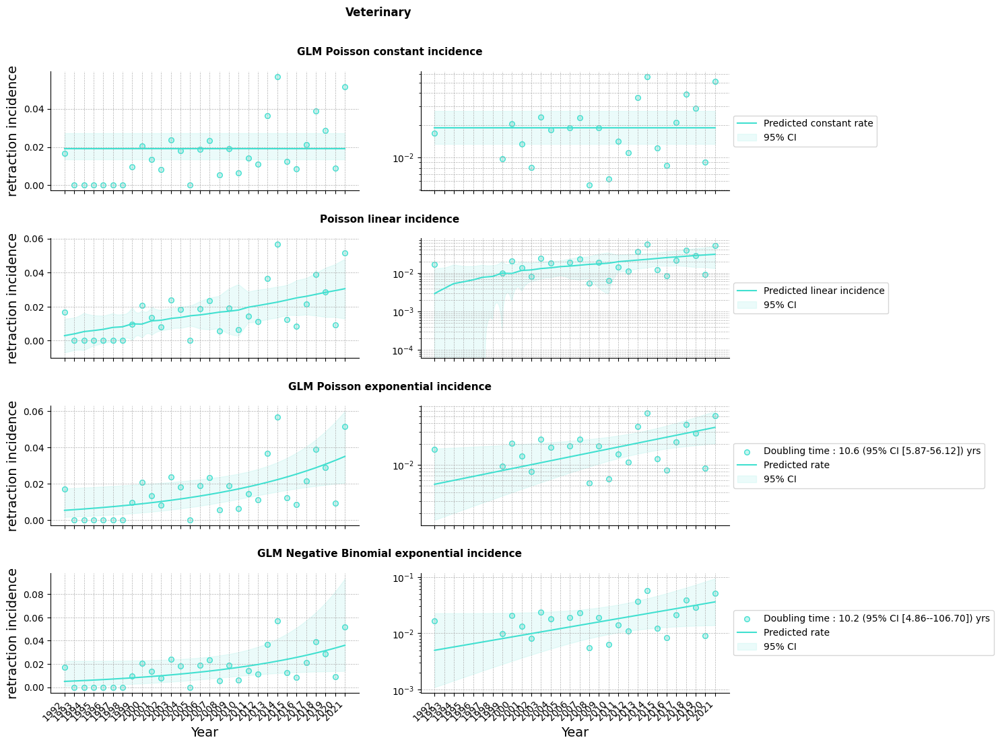

 92%|█████████▏| 24/26 [00:20<00:01,  1.20it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


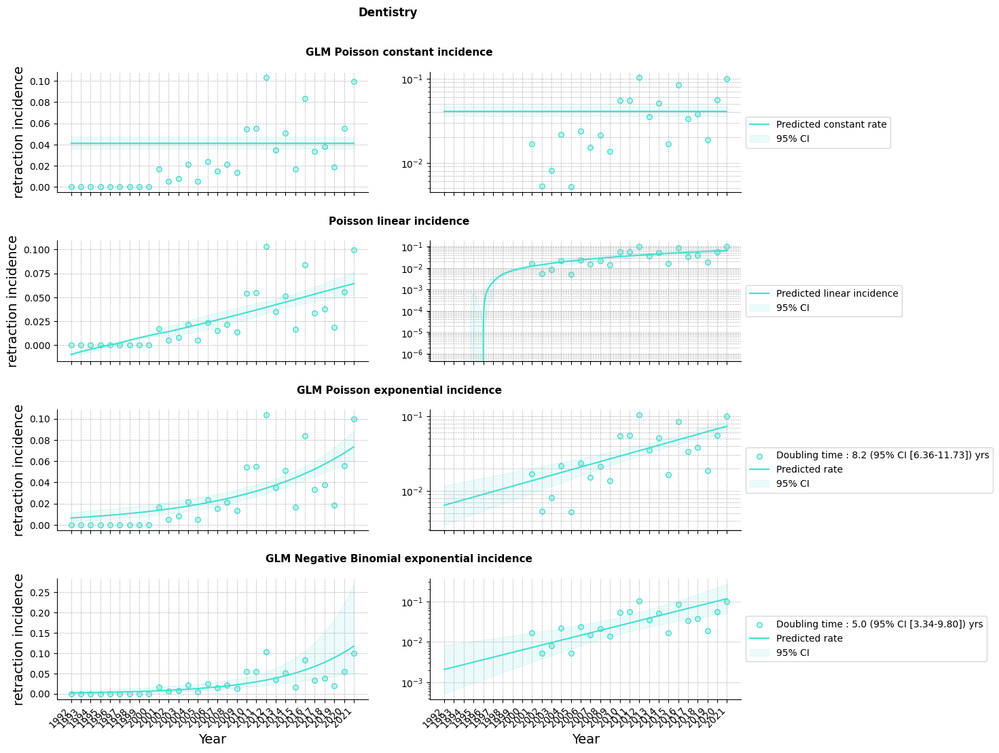

 96%|█████████▌| 25/26 [00:21<00:00,  1.17it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


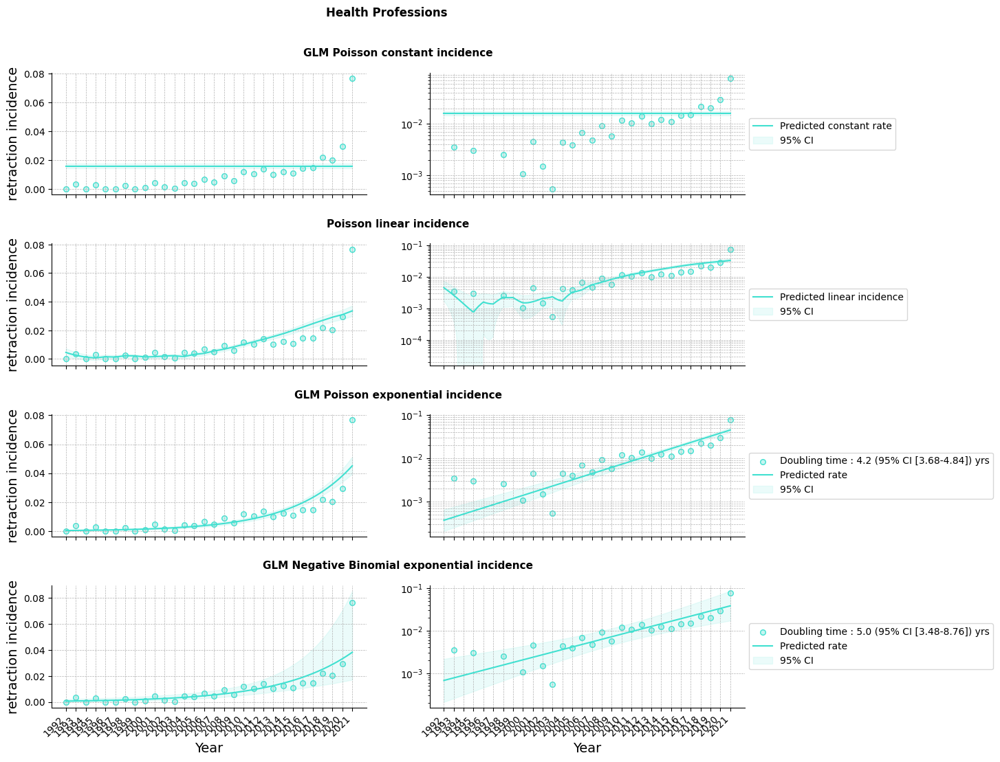

100%|██████████| 26/26 [00:22<00:00,  1.16it/s]


In [46]:
SCALE = 1e2
alpha=1
df = works_retracted_count_byfield.copy()
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
title = 'retraction incidence works'
results_fields_df = pd.DataFrame()
for i in tqdm(range(n_fields)):
    df_i = df[df.field_id_scaled==i]
    results_df = try_all_fit(SCALE,alpha,df_i,start_year,end_year,True,output_folder,title,field_id_scaled_name_dict,i)
    results_fields_df = pd.concat([results_fields_df,results_df])

In [47]:
df = results_fields_df[results_fields_df.model!='GLM Negative Binomial exponential incidence']
df = df[['field_name','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df = df.sort_values(by=['field_name', 'model_order']).drop(columns='model_order')
df.head()

,field_name,model,ΔBIC,ΔBIC_weighted
0,Agricultural and Biological Sciences,constant,691.484120,7.016673e-151
0,Agricultural and Biological Sciences,exponential,0.000000,1.000000e+00
0,Arts and Humanities,constant,126.453668,3.474840e-28
0,Arts and Humanities,exponential,0.000000,1.000000e+00
0,"Biochemistry, Genetics and Molecular Biology",constant,7872.472723,0.000000e+00


In [48]:
df = results_fields_df[results_fields_df.best_model==1][['field_name','b','p value b','doubling time','doubling_time_lower','doubling_time_upper']]
df = df.rename(columns={'b':'g','p value b':'p-value'})
df

,field_name,g,p-value,doubling time,doubling_time_lower,doubling_time_upper
0,Agricultural and Biological Sciences,0.121968,9.519204e-08,5.683034,4.106511,9.224328
0,"Biochemistry, Genetics and Molecular Biology",0.139963,6.403847e-11,4.952349,3.770346,7.213910
0,Immunology and Microbiology,0.077848,4.643475e-04,8.903882,5.616982,21.464026
0,Neuroscience,0.107748,1.849899e-06,6.433033,4.500165,11.276340
0,"Pharmacology, Toxicology and Pharmaceutics",0.150558,1.167645e-06,4.603856,3.238977,7.956778
0,Arts and Humanities,0.129134,2.846161e-06,5.367642,3.733902,9.543194
0,"Business, Management and Accounting",0.157054,2.432771e-09,4.413444,3.285396,6.721173
0,Decision Sciences,0.170162,2.491829e-07,4.073447,2.915628,6.756510
0,"Economics, Econometrics and Finance",0.165983,1.491173e-08,4.176002,3.066656,6.542840
0,Psychology,0.085800,2.166001e-04,8.078623,5.199270,18.105364


## Countries

In [ ]:
sql = """
  CREATE TABLE `project_name.dataset_name.works_retracted_count_bycountry`
  AS 
  WITH
  -- Step 1: Deduplicate and prepare core authorship data
  deduped_authorships AS (
    SELECT DISTINCT
      work_id,
      is_retracted,
      publication_year,
      author_id,
      country_code
    FROM project_name.dataset_name.works_authorships
    WHERE country_code IS NOT NULL
      AND publication_year BETWEEN '1992-01-01' AND '2021-01-01'
  ),

  -- Step 2: Count unique authors per work
  unique_authors_per_work AS (
    SELECT
      work_id,
      COUNT(DISTINCT author_id) AS num_authors
    FROM deduped_authorships
    GROUP BY work_id
  ),

  -- Step 3: Count unique countries per author per work
  unique_countries_per_author_work AS (
    SELECT 
      work_id,
      author_id,
      COUNT(DISTINCT country_code) AS num_countries_per_author
    FROM deduped_authorships
    GROUP BY work_id, author_id
  ),

  -- Step 4: Compute weights
  author_country_weights AS (
    SELECT
      d.work_id,
      d.is_retracted,
      d.publication_year,
      d.author_id,
      d.country_code,
      1.0 / (uapw.num_authors * uipaw.num_countries_per_author) AS author_country_weight
    FROM deduped_authorships d
    JOIN unique_authors_per_work uapw
      ON d.work_id = uapw.work_id
    JOIN unique_countries_per_author_work uipaw
      ON d.work_id = uipaw.work_id AND d.author_id = uipaw.author_id
  ),

  -- Step 5: Aggregate total and retracted weights
  final_country_year_weights AS (
    SELECT
      publication_year,
      country_code,
      SUM(author_country_weight) AS total_weight,
      SUM(CASE WHEN is_retracted = 1 THEN author_country_weight ELSE 0 END) AS retracted_weight
    FROM author_country_weights
    GROUP BY publication_year, country_code
  )

  -- Final output
  SELECT *
  FROM final_country_year_weights
  ORDER BY publication_year, country_code;
"""
##output info
new_table_name = "works_retracted_count_bycountry"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)

In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
output_folder = './Plots/plots_countries'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

In [ ]:
works_retracted_count_bycountry = pd.read_csv(f'./Data/works_retracted_count_bycountry.csv.gz', compression='gzip', keep_default_na=False).rename(columns={'publication_year':'year'})
works_retracted_count_bycountry['year'] = works_retracted_count_bycountry['year'].str[:4].astype(int)
works_retracted_count_bycountry = works_retracted_count_bycountry.rename(columns={'total_weight':'total','retracted_weight':'retracted'})
works_retracted_count_bycountry = works_retracted_count_bycountry.dropna()
def country_code_to_name(code):
    try:
        country = pycountry.countries.get(alpha_2=code.upper())
        return country.name if country else None
    except:
        return None
works_retracted_count_bycountry['country_name'] = works_retracted_count_bycountry['country_code'].apply(country_code_to_name)
country_code_name_dict = works_retracted_count_bycountry[['country_code','country_name']].drop_duplicates().set_index('country_code').to_dict()['country_name']
country_code_name_dict['XK'] = 'Kosovo'
works_retracted_count_bycountry['country_name'] = works_retracted_count_bycountry['country_code'].map(country_code_name_dict)
works_retracted_count_bycountry['country_name'] = (works_retracted_count_bycountry['country_name'].replace({'Iran, Islamic Republic of': 'Islamic Republic of Iran','Korea, Republic of': 'Republic of Korea'}))
print(f'{len(set(works_retracted_count_bycountry.country_code))} countries')

227 countries


In [51]:
## retracted map 2021
works_retracted_count_bycountry_2021 = works_retracted_count_bycountry[works_retracted_count_bycountry.year==2021]
works_retracted_count_bycountry_2021.head()

,Unnamed: 0,year,country_code,total,retracted,country_name
6330,8725,2021,AD,13.703019,0.000000,Andorra
6331,8726,2021,AE,5601.582824,10.785714,United Arab Emirates
6332,8727,2021,AF,478.816578,0.783333,Afghanistan
6333,8728,2021,AG,103.433618,0.000000,Antigua and Barbuda
6334,8729,2021,AL,832.775387,1.500000,Albania


In [52]:
## total publications map 1992, 2000, 2010, 2021
works_retracted_count_bycountry[works_retracted_count_bycountry.year.isin({1992,2000,2010,2021})].head()

,Unnamed: 0,year,country_code,total,retracted,country_name
0,2395,1992,AE,86.556519,0.0,United Arab Emirates
1,2396,1992,AF,2.166667,0.0,Afghanistan
2,2397,1992,AG,3.000000,0.0,Antigua and Barbuda
3,2398,1992,AL,26.671429,0.0,Albania
4,2399,1992,AM,131.097438,0.0,Armenia


In [53]:
## countries coverage

# --- Define years of interest ---
years_of_interest = [1992, 1997, 2002, 2007, 2012, 2017, 2021]


def countries_coverage(col):
    df_year_country = (
        works_retracted_count_bycountry[works_retracted_count_bycountry['year'].isin(years_of_interest)]
        .groupby(['year', 'country_code'], as_index=False)[col]
        .sum()
    )
    # Function: count number of countries to reach 80%
    def count_countries_covering_X(group, l=0.8):
        group = group.sort_values(col, ascending=False)
        group['cum_share'] = group[col].cumsum() / group[col].sum()
        n_countries = (group['cum_share'] <= l).sum()
        return pd.Series({'n_countries': n_countries})
    # Compute per-year metric
    df_50 = (
        df_year_country.groupby('year')
        .apply(lambda x: count_countries_covering_X(x, 0.5))
        .reset_index()
        .sort_values('year')
    )
    df_50.insert(0,'coverage',50)
    df_80 = (
        df_year_country.groupby('year')
        .apply(lambda x: count_countries_covering_X(x, 0.8))
        .reset_index()
        .sort_values('year')
    )
    df_80.insert(0,'coverage',80)
    df_90 = (
        df_year_country.groupby('year')
        .apply(lambda x: count_countries_covering_X(x, 0.9))
        .reset_index()
        .sort_values('year')
    )   
    df_90.insert(0,'coverage',90)

    return pd.concat([df_50,df_80,df_90]).sort_values(by=['year','coverage'])

In [54]:
df_coverage_retracted = countries_coverage('retracted')
df_coverage_total = countries_coverage('total')
display(df_coverage_retracted)
display(df_coverage_total)

,coverage,year,n_countries
0,50,1992,2
0,80,1992,4
0,90,1992,6
1,50,1997,1
1,80,1997,6
1,90,1997,11
2,50,2002,2
2,80,2002,7
2,90,2002,12
3,50,2007,1


,coverage,year,n_countries
0,50,1992,2
0,80,1992,10
0,90,1992,19
1,50,1997,2
1,80,1997,12
1,90,1997,22
2,50,2002,3
2,80,2002,14
2,90,2002,24
3,50,2007,3


In [55]:
#Correlation
from scipy.stats import pearsonr
df_corr = works_retracted_count_bycountry_2021[['country_code', 'total', 'retracted']].copy()
df_corr = df_corr[(df_corr['total'] > 0.0012) & (df_corr['retracted'] > 0.0012)]
correlation, p_value = pearsonr(np.log10(df_corr['total']), np.log10(df_corr['retracted']))

x = np.log10(df_corr['total'])
y = np.log10(df_corr['retracted'])
n = len(x)

m, b = np.polyfit(x, y, 1)
y_pred = m * x + b

resid = y - y_pred
s_err = np.sqrt(np.sum(resid**2) / (n - 2))

alpha = 0.10
t_val = t.ppf(1 - alpha/2, df=n - 2)

x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = m * x_fit + b

s_xx = np.sum((x - np.mean(x))**2)
se_fit = s_err * np.sqrt(1/n + (x_fit - np.mean(x))**2 / s_xx)

ci_upper = y_fit + t_val * se_fit
ci_lower = y_fit - t_val * se_fit

#R squared
ss_total = np.sum((y - np.mean(y))**2)
ss_residual = np.sum(resid**2)
r_squared = 1 - (ss_residual / ss_total)

print(f"P-value: {p_value:.3e}")
print(f"R^2: {r_squared:.2f}")

P-value: 1.249e-24
R^2: 0.59


In [56]:
## country selection: 
col = 'total'
df_year_country = (
    works_retracted_count_bycountry[works_retracted_count_bycountry['year']==2021]
    .groupby(['year', 'country_code'], as_index=False)[col]
    .sum()
)
def countries_covering_X(group, l=0.8):
    group = group.sort_values(col, ascending=False)
    group['cum_share'] = group[col].cumsum() / group[col].sum()
    selected = group[group['cum_share'] <= l]['country_code'].tolist()
    return pd.Series({
        'n_countries': len(selected),
        'countries': selected
    })
df_80 = (
    df_year_country.groupby('year')
    .apply(lambda x: countries_covering_X(x, 0.8))
    .reset_index()
    .sort_values('year')
)
country_selected_set = df_80.loc[0].countries

In [57]:
works_retracted_count_bycountry = works_retracted_count_bycountry[works_retracted_count_bycountry.country_code.isin(country_selected_set)].reset_index(drop=True)
print(f'{len(set(works_retracted_count_bycountry.country_code))} countries')

21 countries


  0%|          | 0/21 [00:00<?, ?it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


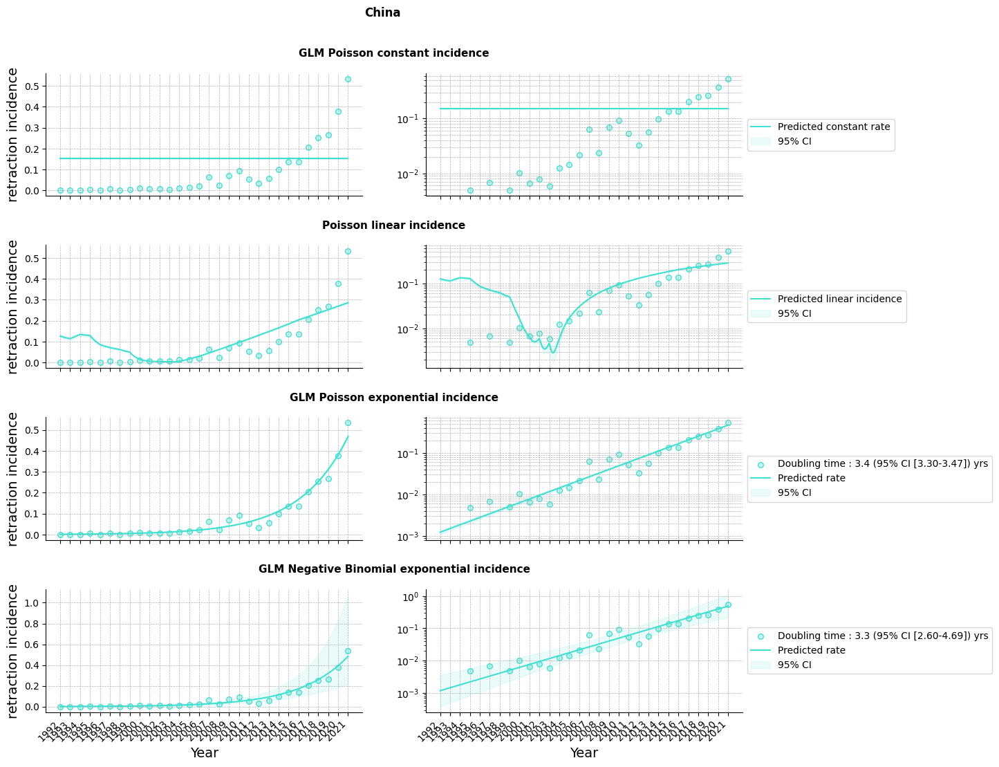

  5%|▍         | 1/21 [00:00<00:17,  1.14it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


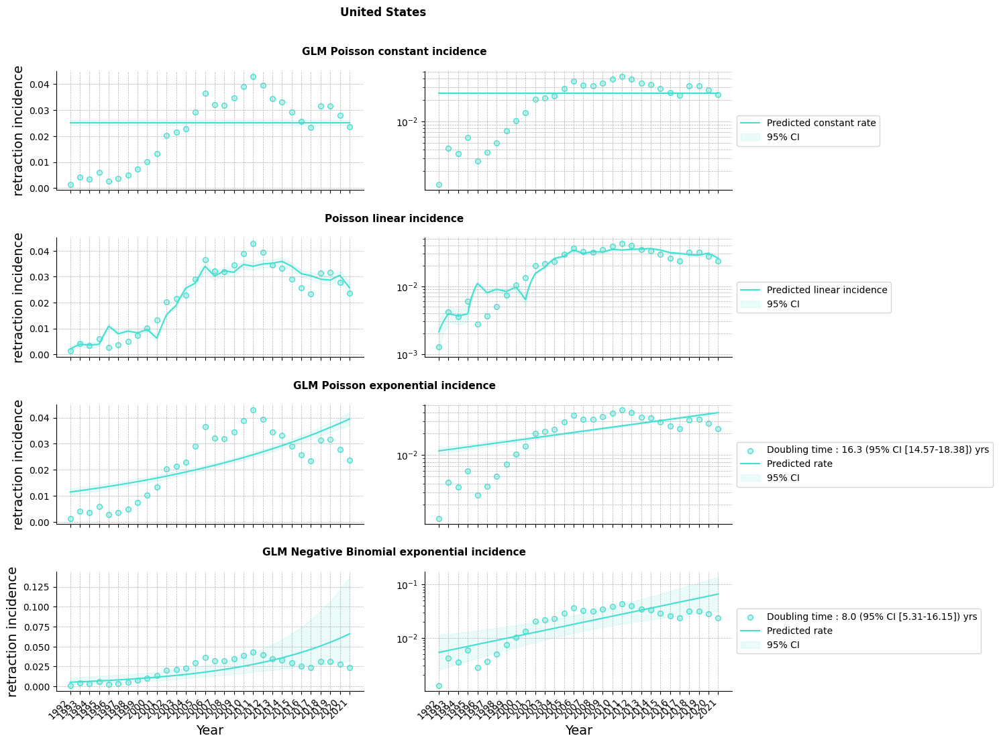

 10%|▉         | 2/21 [00:01<00:15,  1.24it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


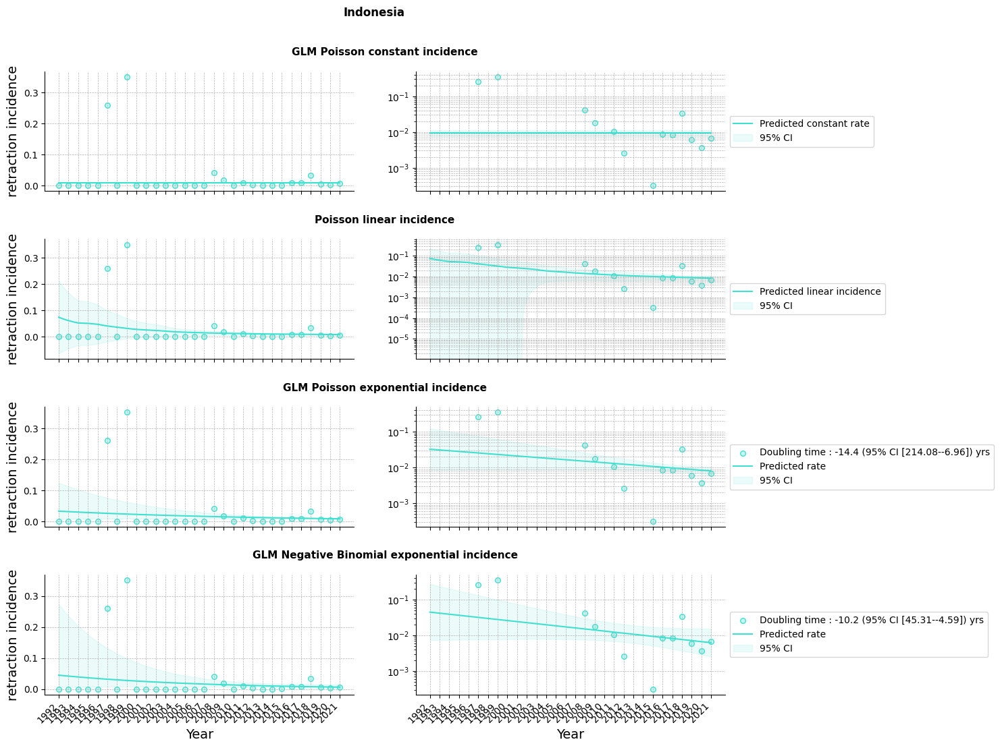

 14%|█▍        | 3/21 [00:02<00:15,  1.19it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


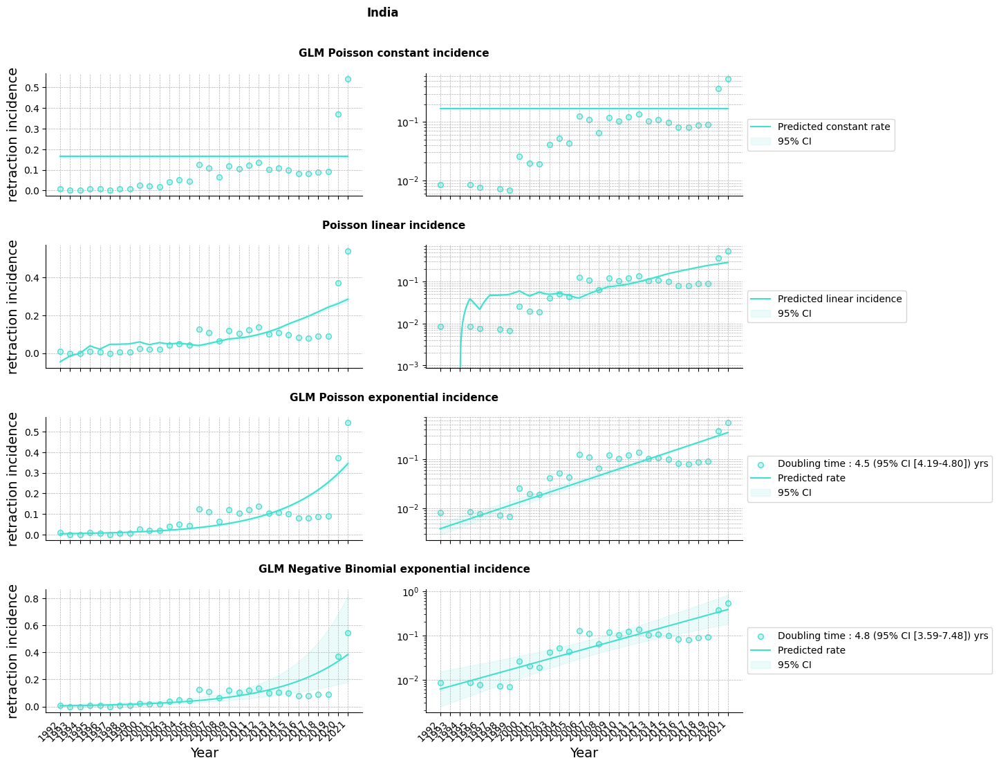

 19%|█▉        | 4/21 [00:03<00:14,  1.18it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


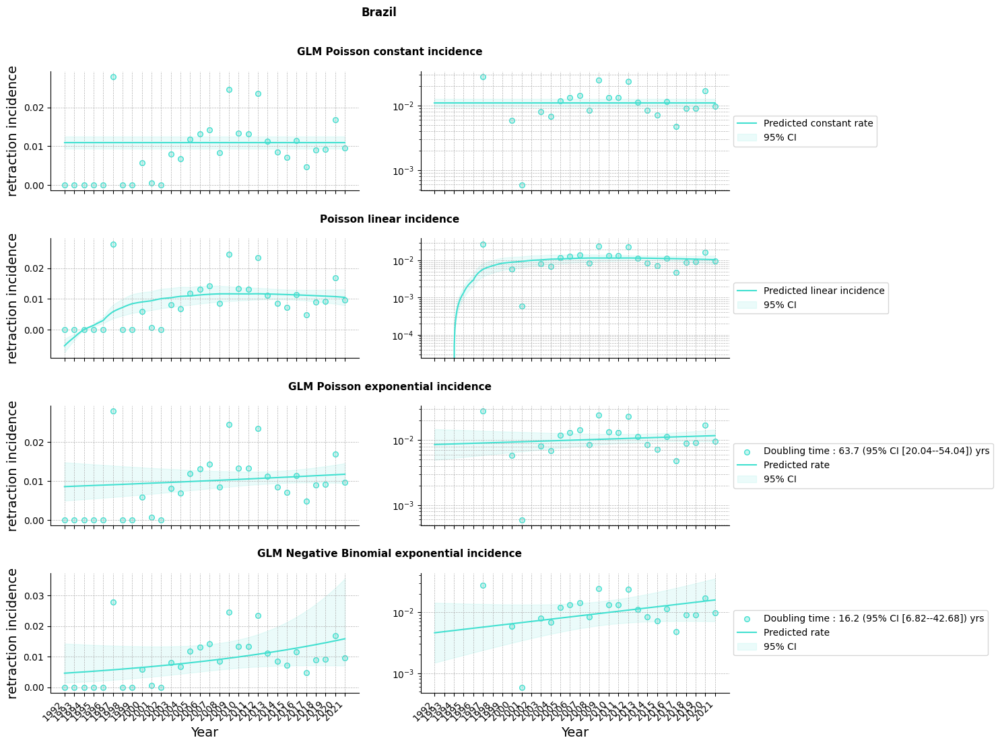

 24%|██▍       | 5/21 [00:04<00:13,  1.19it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


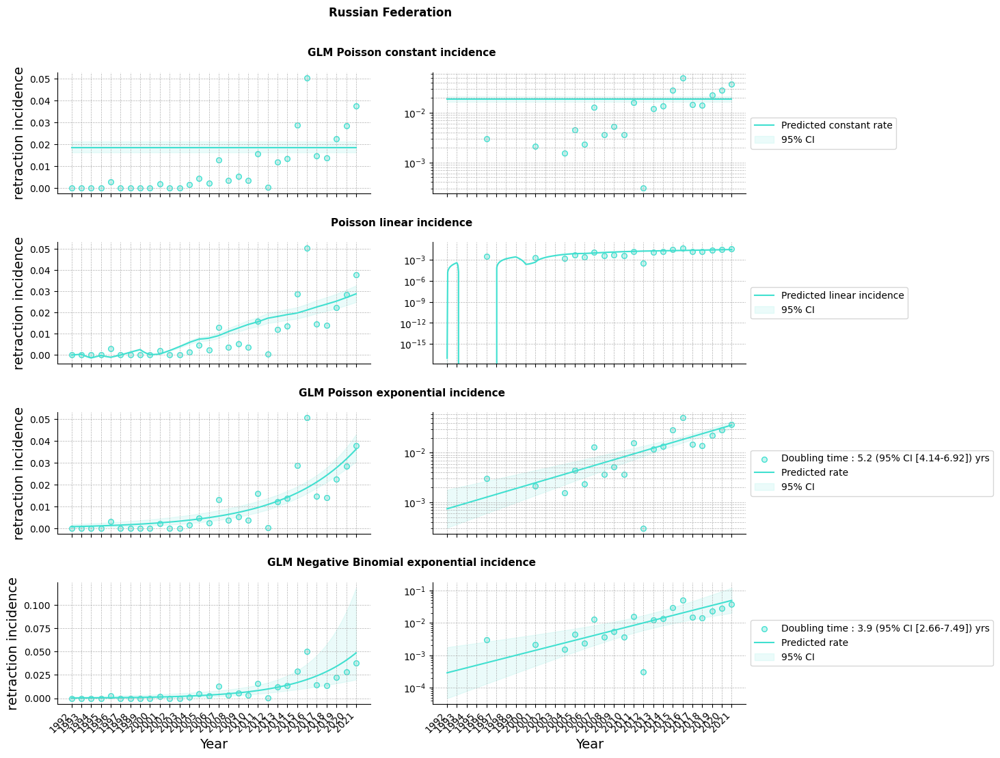

 29%|██▊       | 6/21 [00:05<00:12,  1.18it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


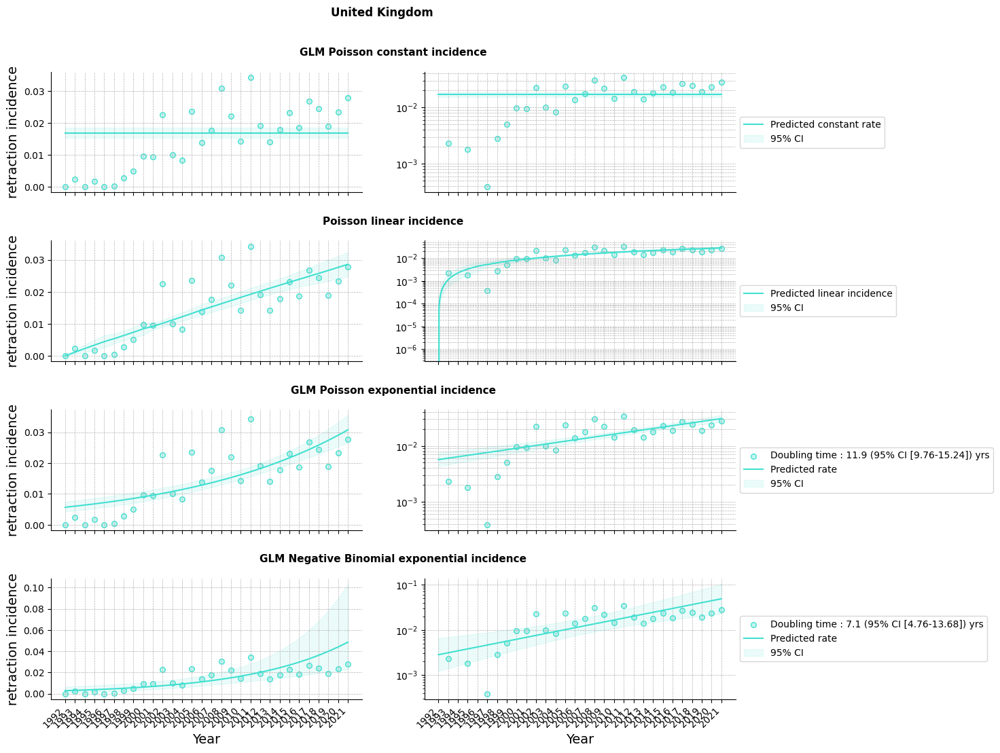

 33%|███▎      | 7/21 [00:05<00:12,  1.17it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


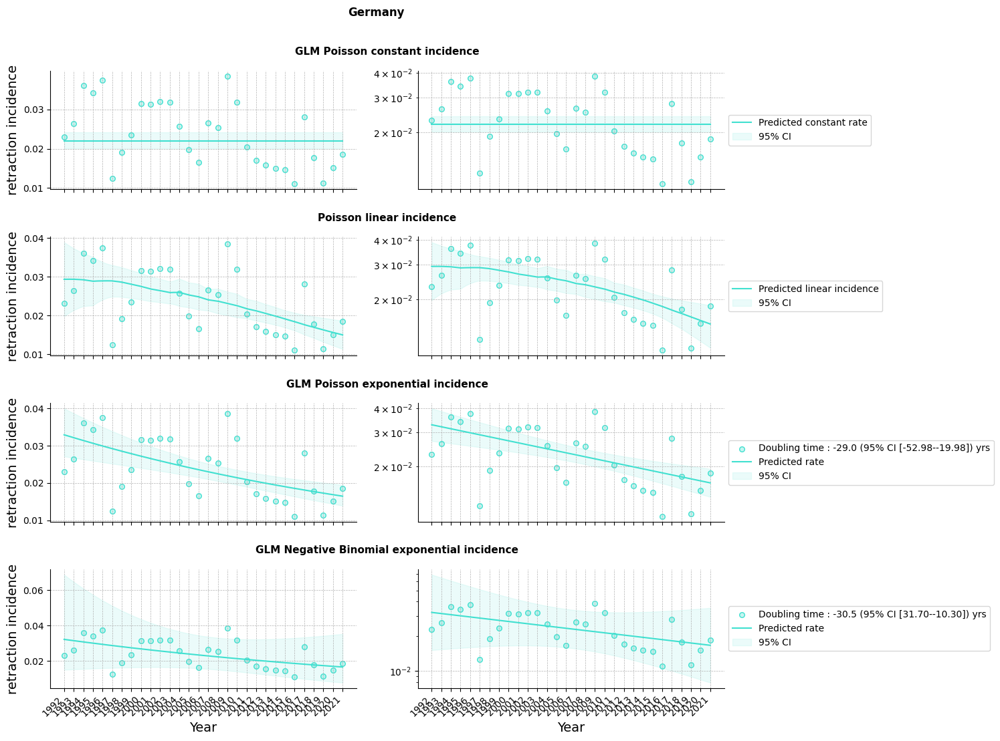

 38%|███▊      | 8/21 [00:06<00:10,  1.23it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


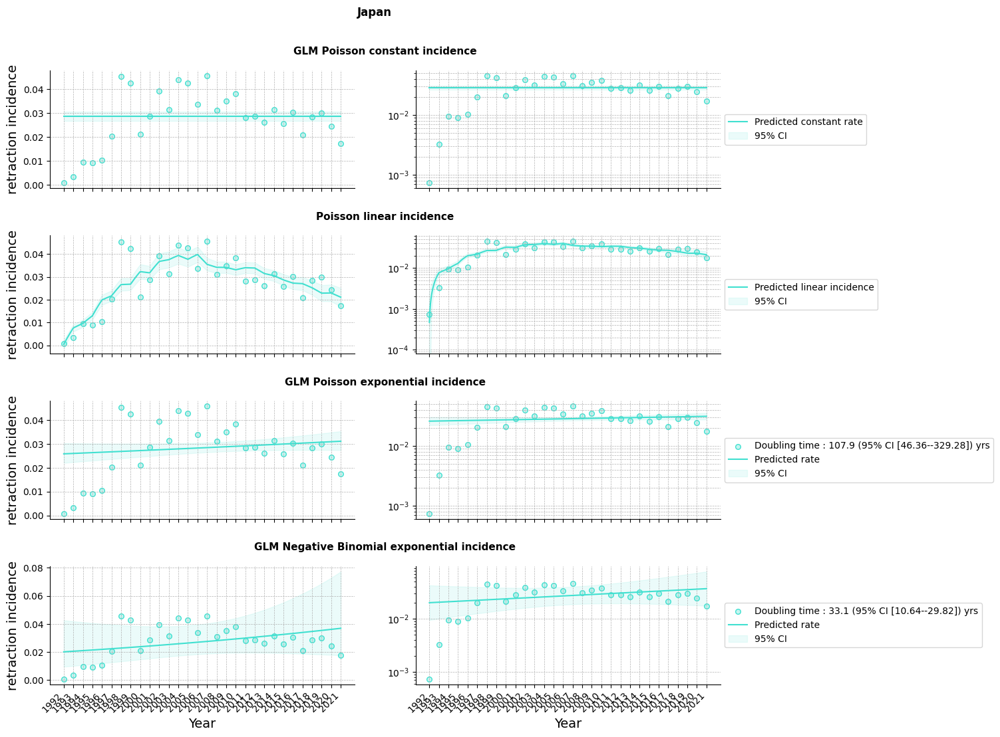

 43%|████▎     | 9/21 [00:07<00:09,  1.21it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


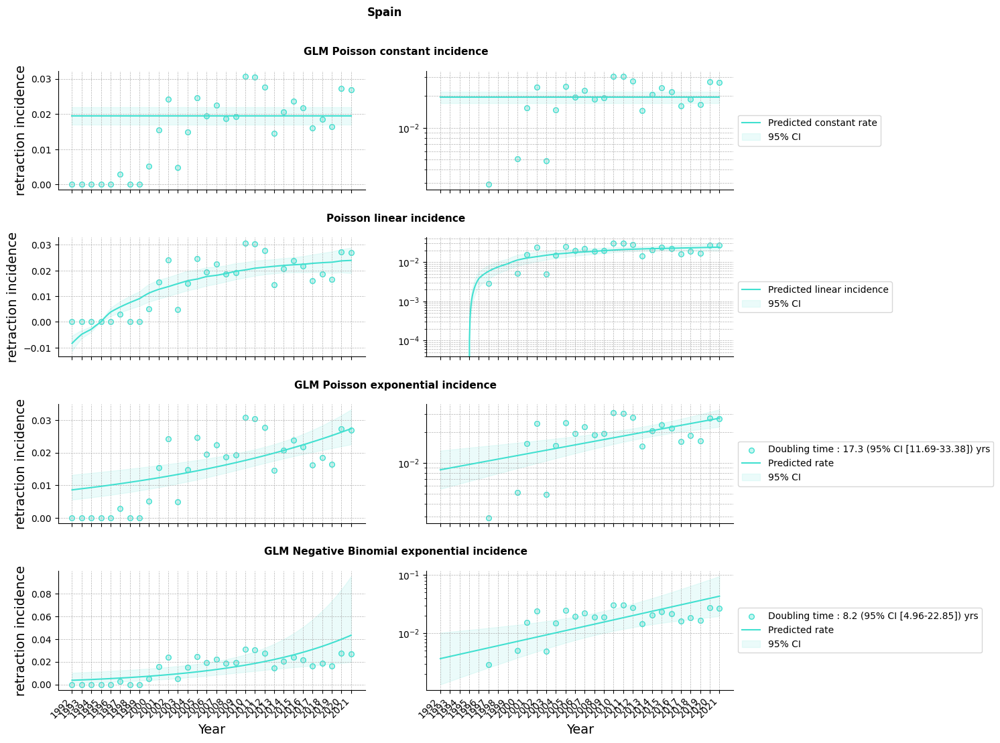

 48%|████▊     | 10/21 [00:08<00:09,  1.20it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


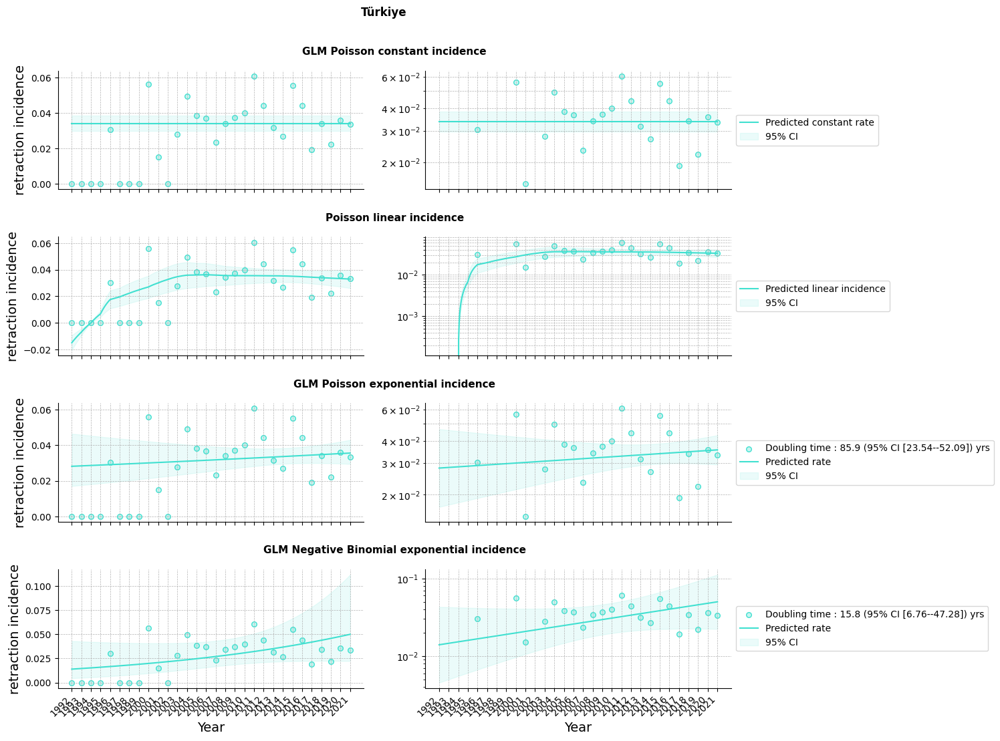

 52%|█████▏    | 11/21 [00:09<00:08,  1.20it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


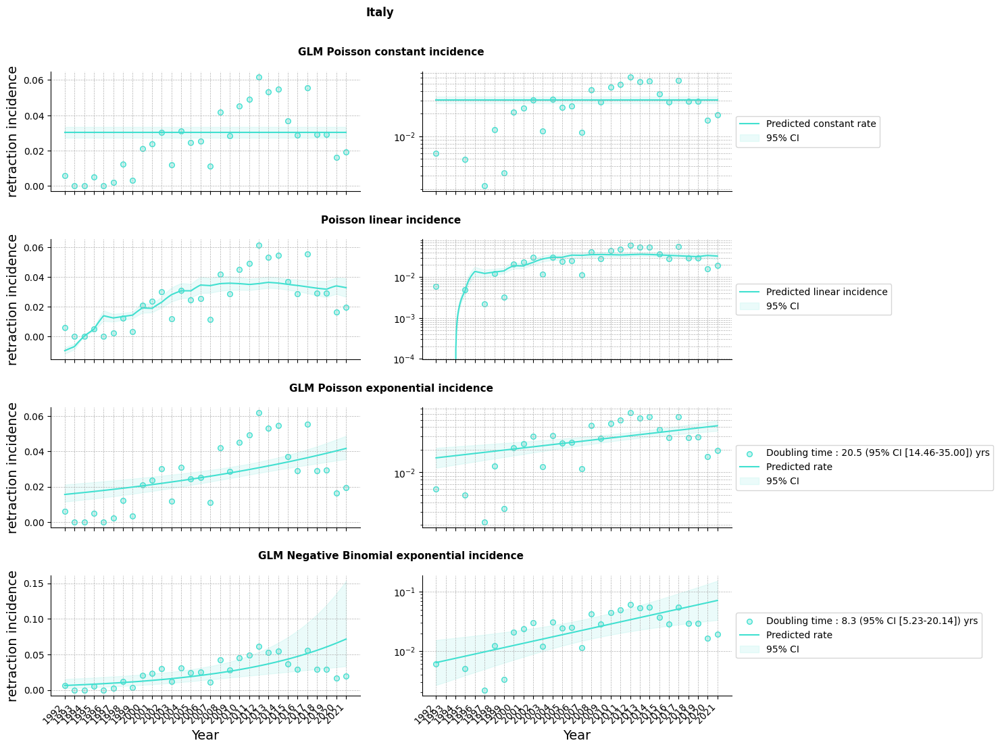

 57%|█████▋    | 12/21 [00:09<00:07,  1.23it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


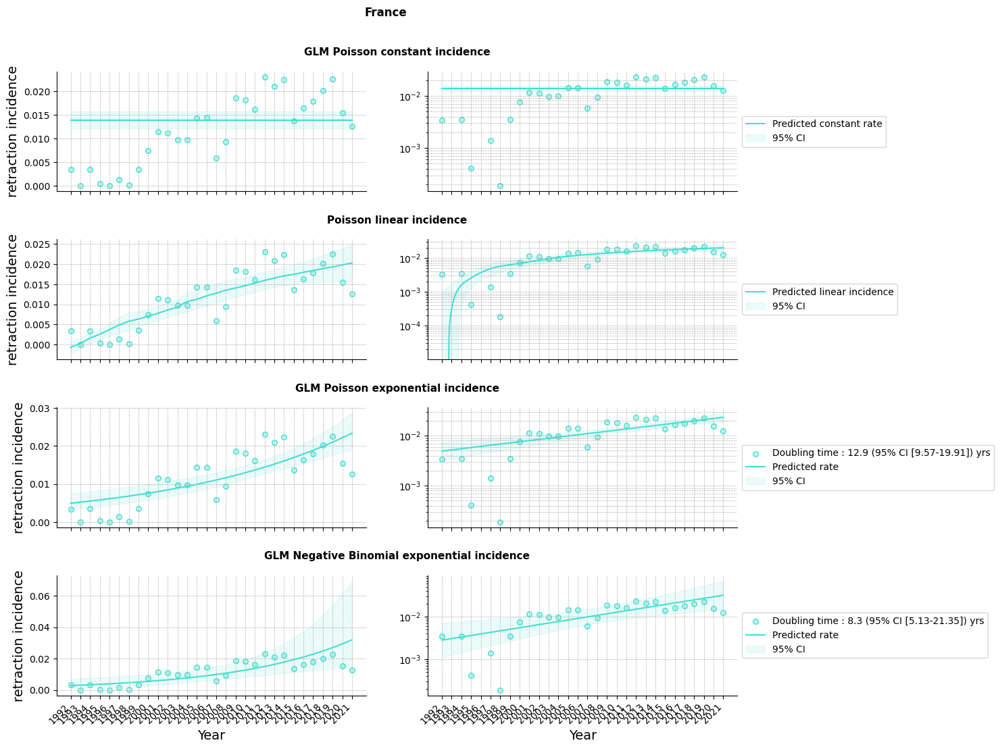

 62%|██████▏   | 13/21 [00:10<00:06,  1.21it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


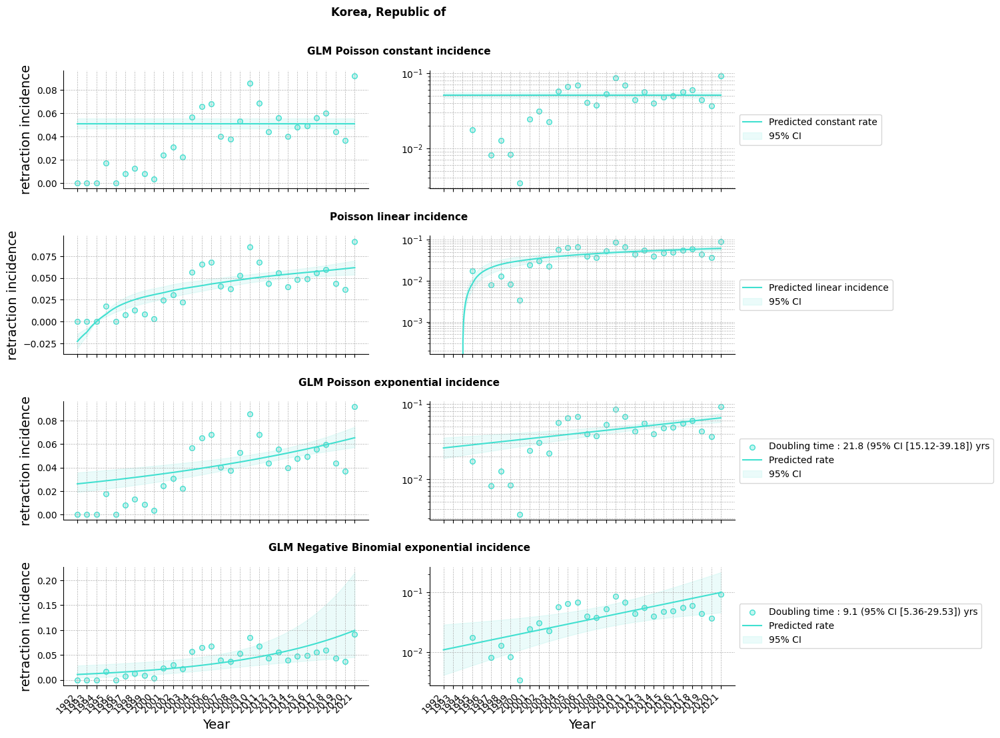

 67%|██████▋   | 14/21 [00:11<00:05,  1.19it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


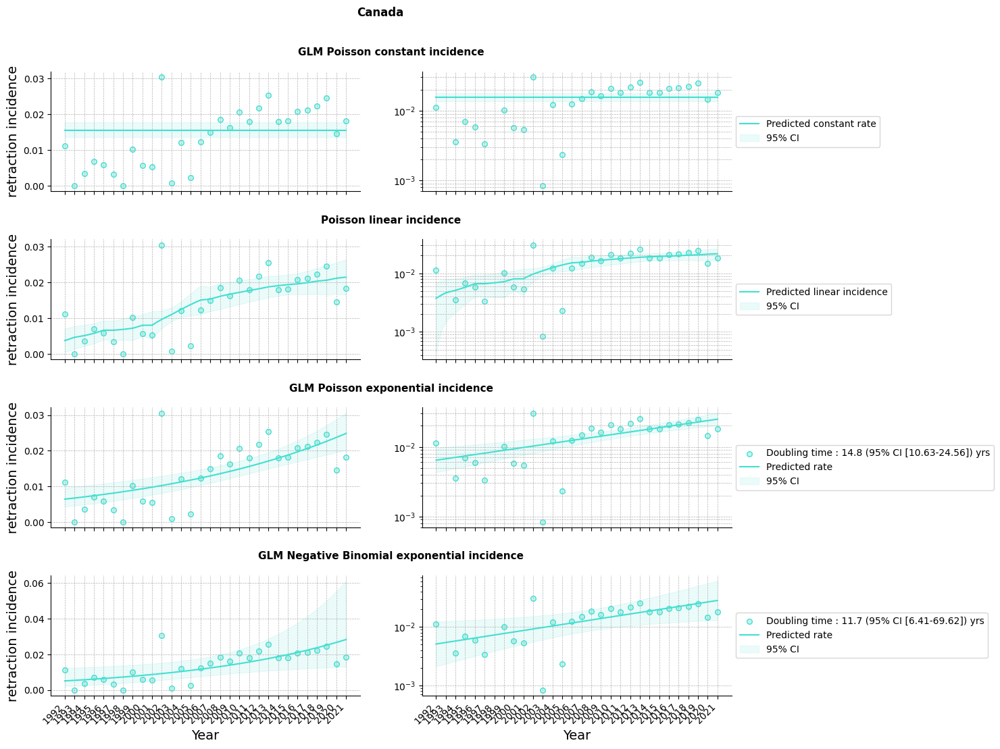

 71%|███████▏  | 15/21 [00:12<00:04,  1.20it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


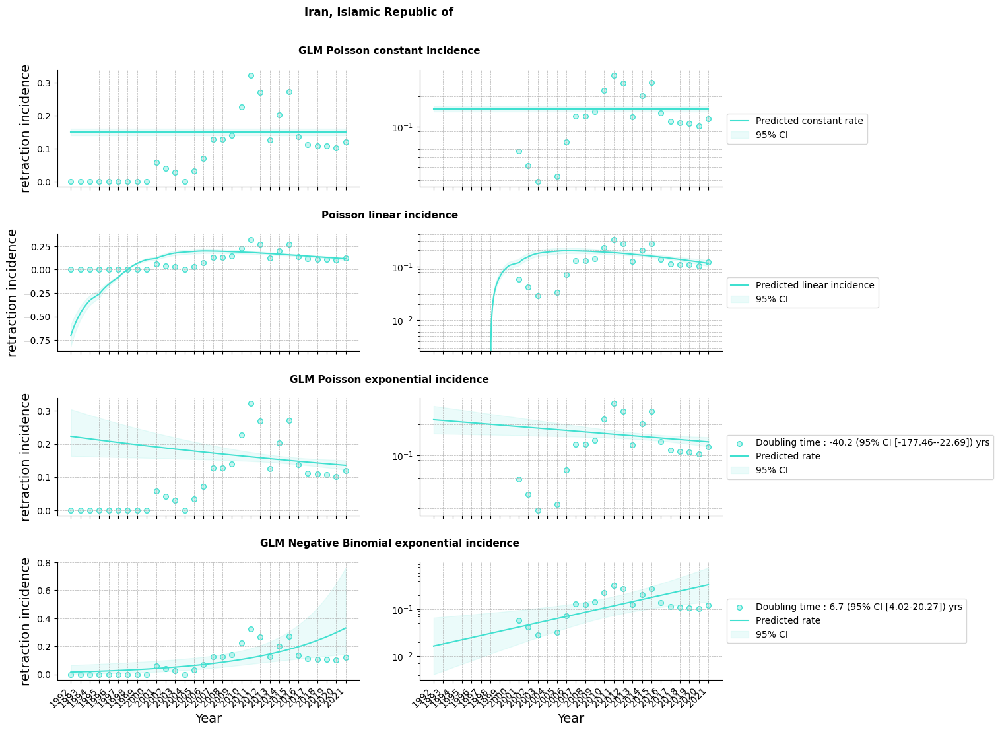

 76%|███████▌  | 16/21 [00:13<00:04,  1.20it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


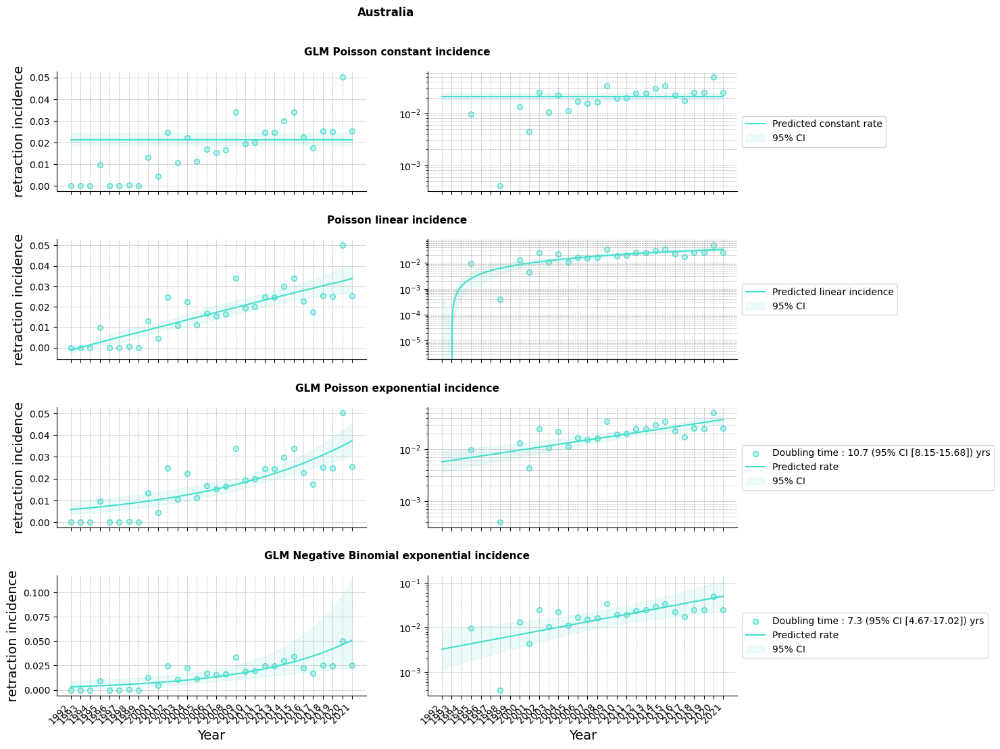

 81%|████████  | 17/21 [00:14<00:03,  1.18it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


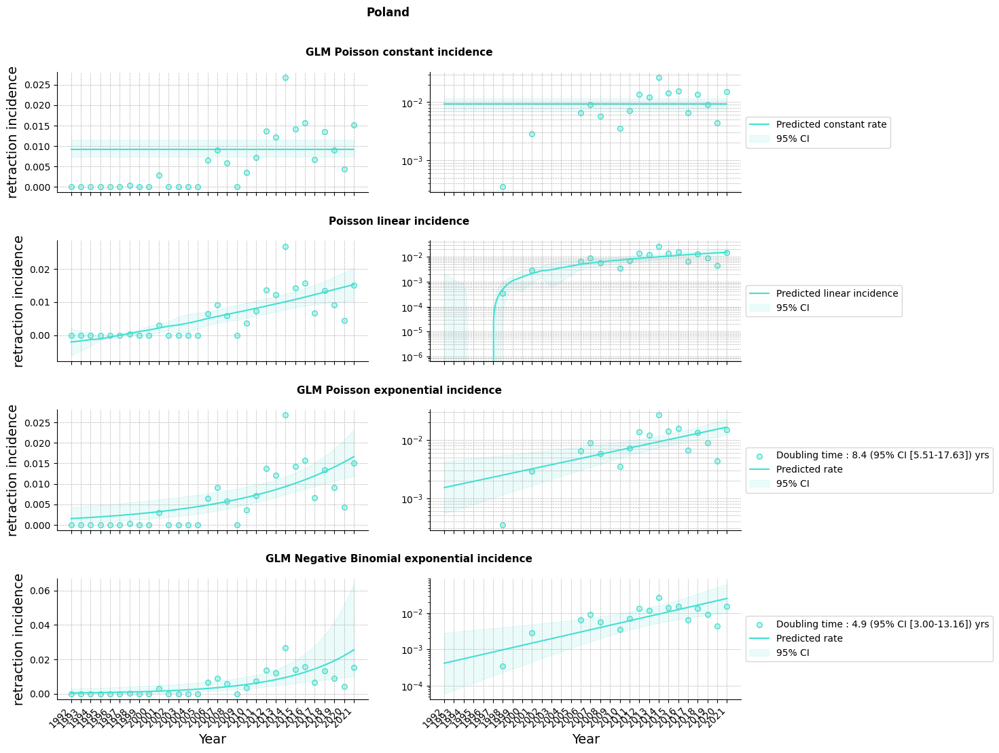

 86%|████████▌ | 18/21 [00:15<00:02,  1.16it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


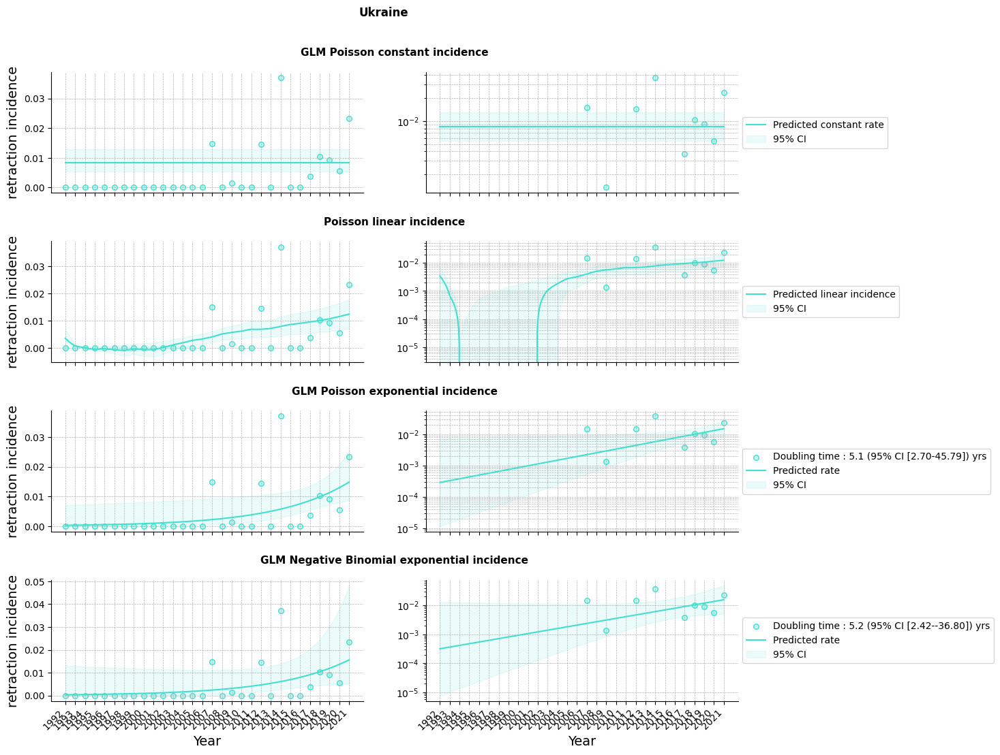

 90%|█████████ | 19/21 [00:16<00:01,  1.15it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


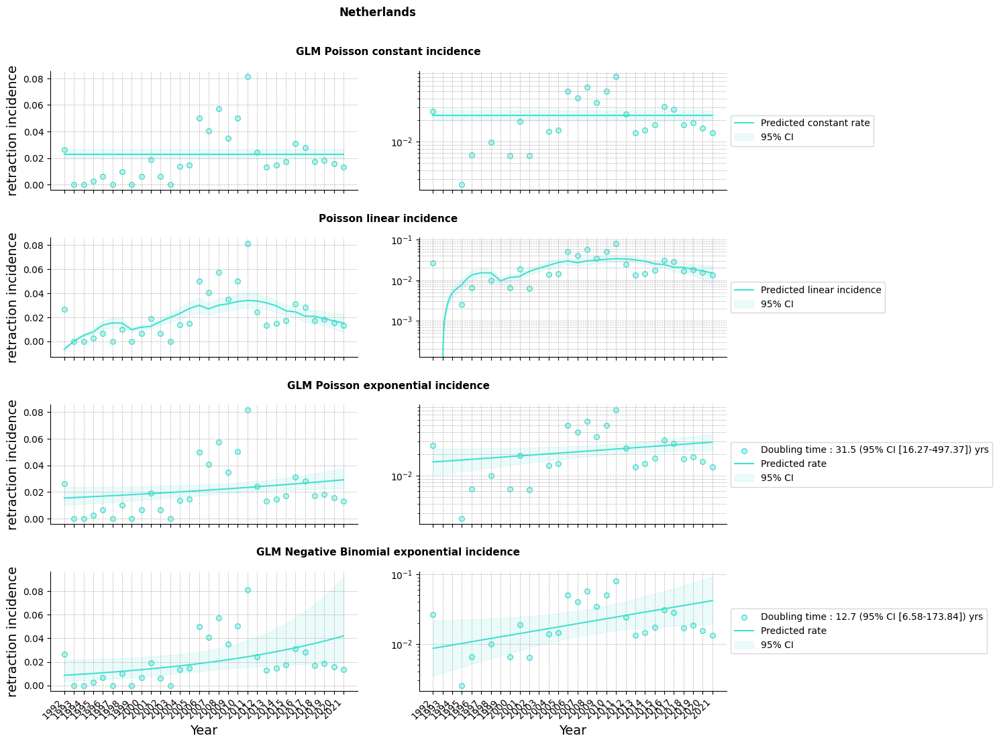

 95%|█████████▌| 20/21 [00:16<00:00,  1.19it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


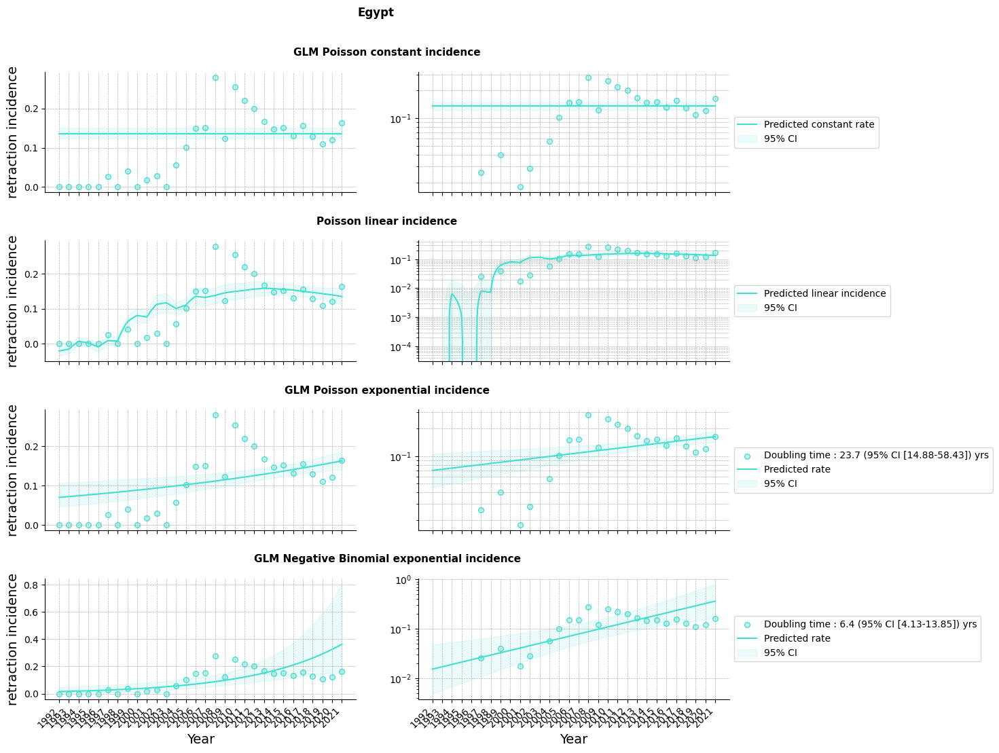

100%|██████████| 21/21 [00:17<00:00,  1.19it/s]


In [58]:
SCALE = 1e2
alpha=1
df = works_retracted_count_bycountry
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
title = 'retraction incidence works'
results_country_df = pd.DataFrame()
for i in tqdm(country_selected_set):
    df_i = df[df.country_code==i]
    results_df = try_all_fit(SCALE,alpha,df_i,start_year,end_year,True,output_folder,title,country_code_name_dict,i)
    results_country_df = pd.concat([results_country_df,results_df])
results_country_df = results_country_df.rename(columns={'field_id_scaled':'country_code','field_name':'country_name'})

  0%|          | 0/21 [00:00<?, ?it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


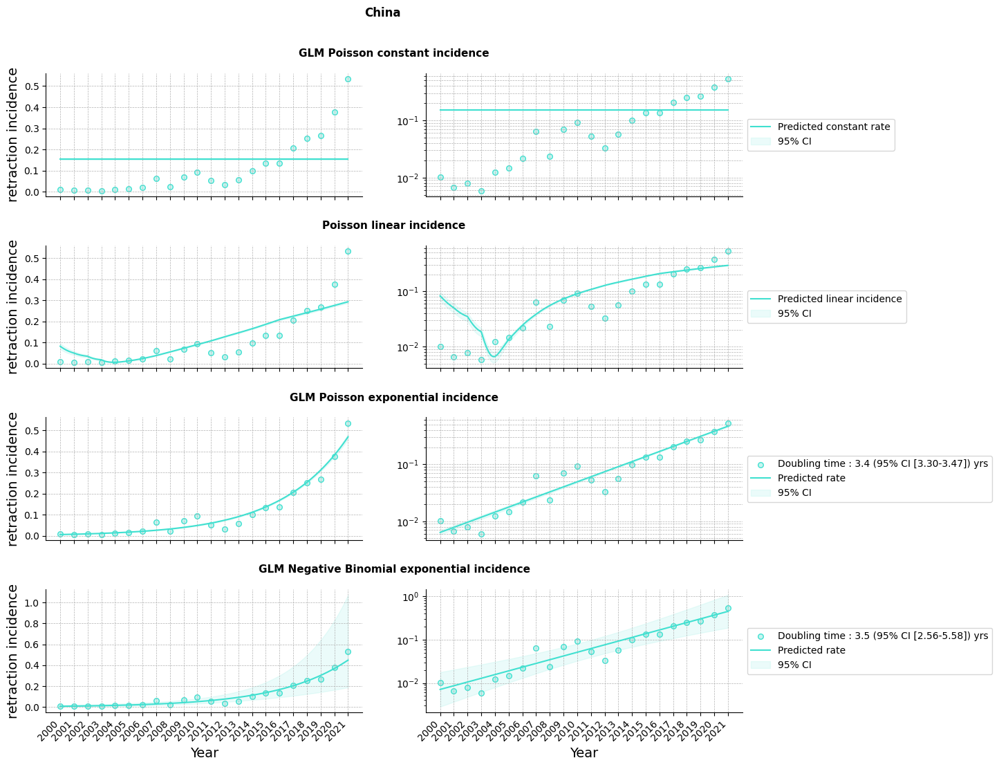

  5%|▍         | 1/21 [00:00<00:16,  1.24it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


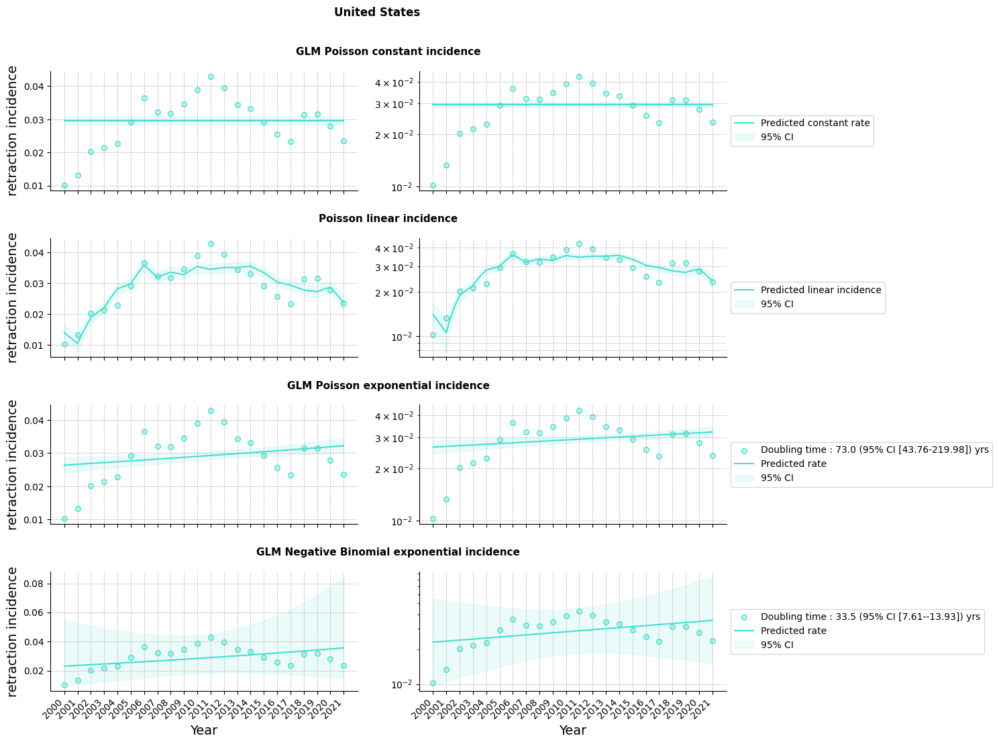

 10%|▉         | 2/21 [00:01<00:14,  1.30it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


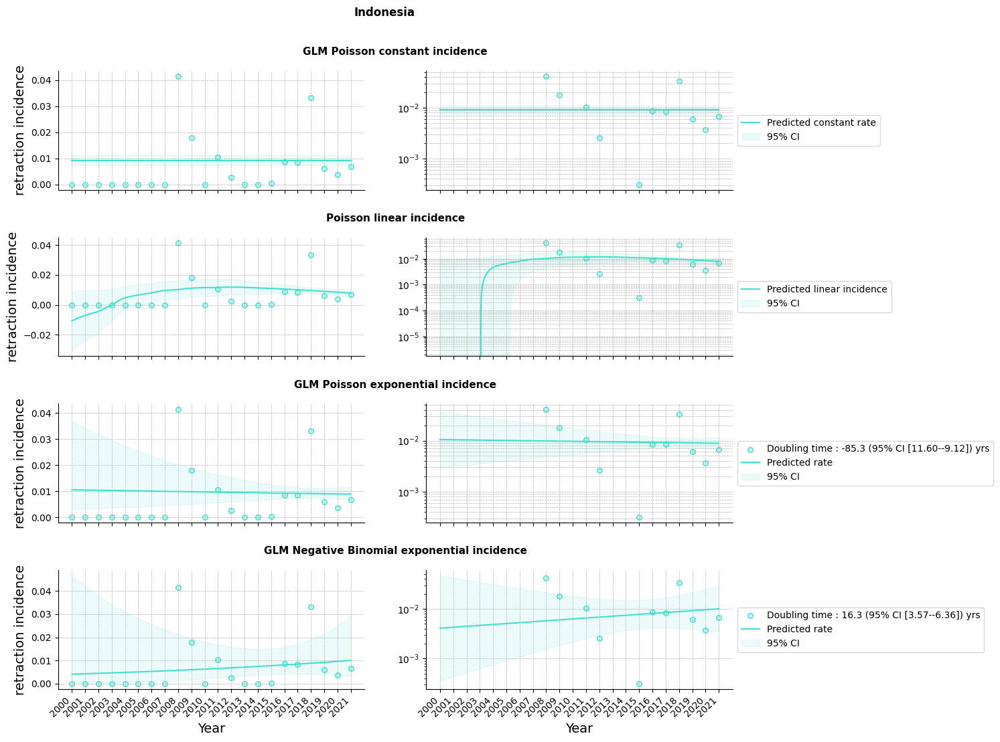

 14%|█▍        | 3/21 [00:02<00:13,  1.30it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


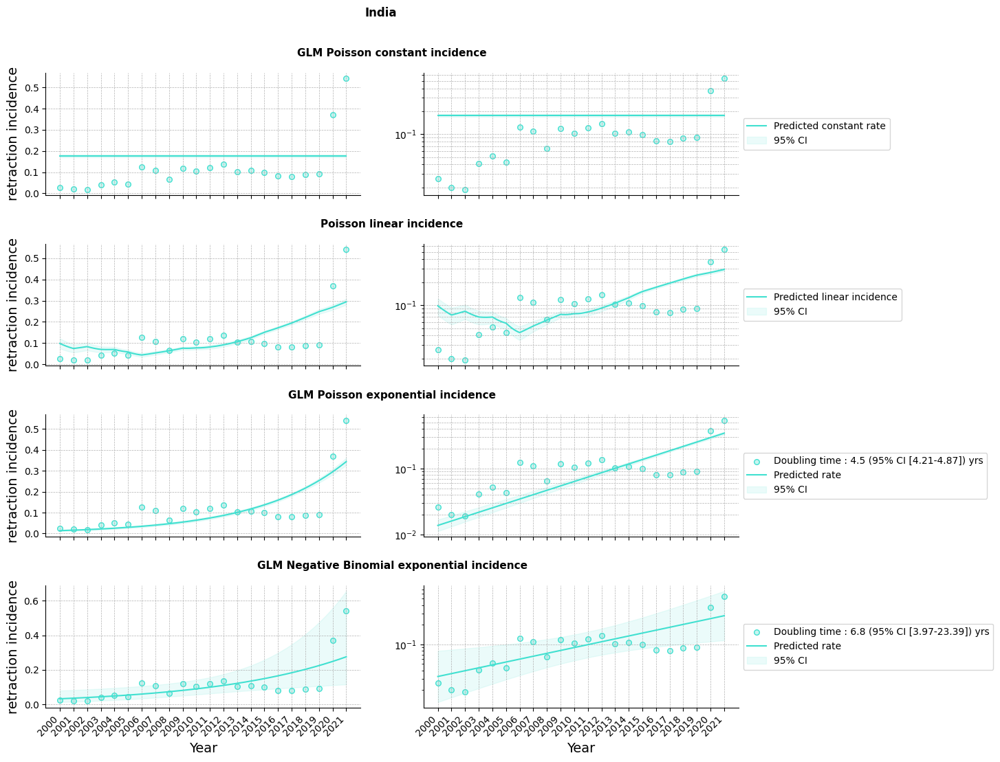

 19%|█▉        | 4/21 [00:03<00:12,  1.32it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


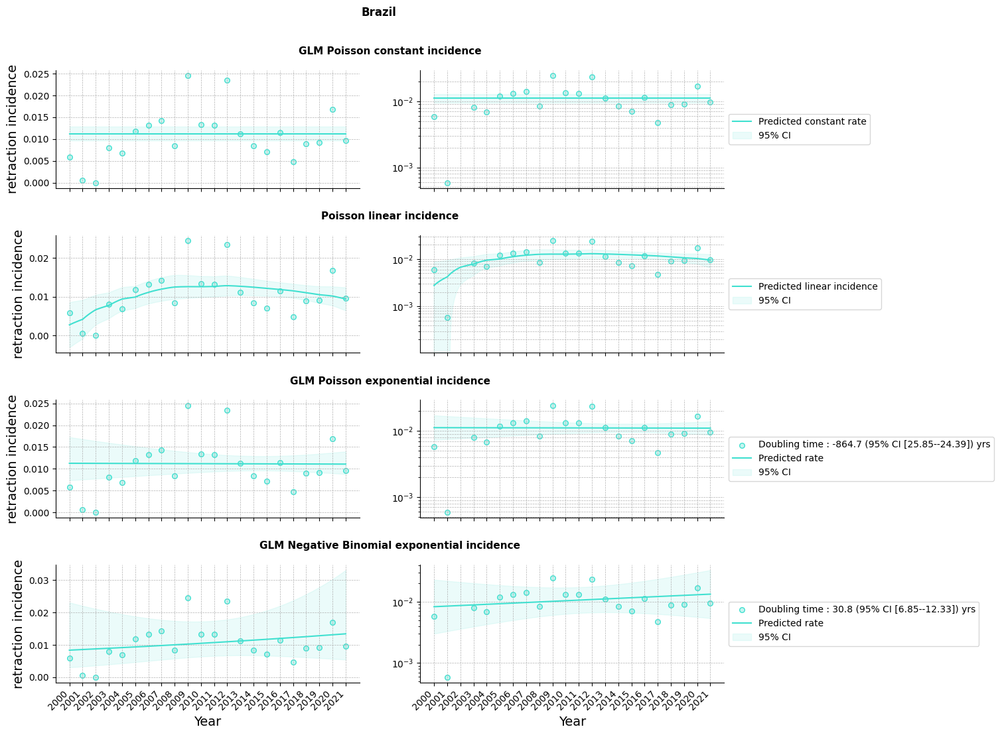

 24%|██▍       | 5/21 [00:03<00:12,  1.30it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


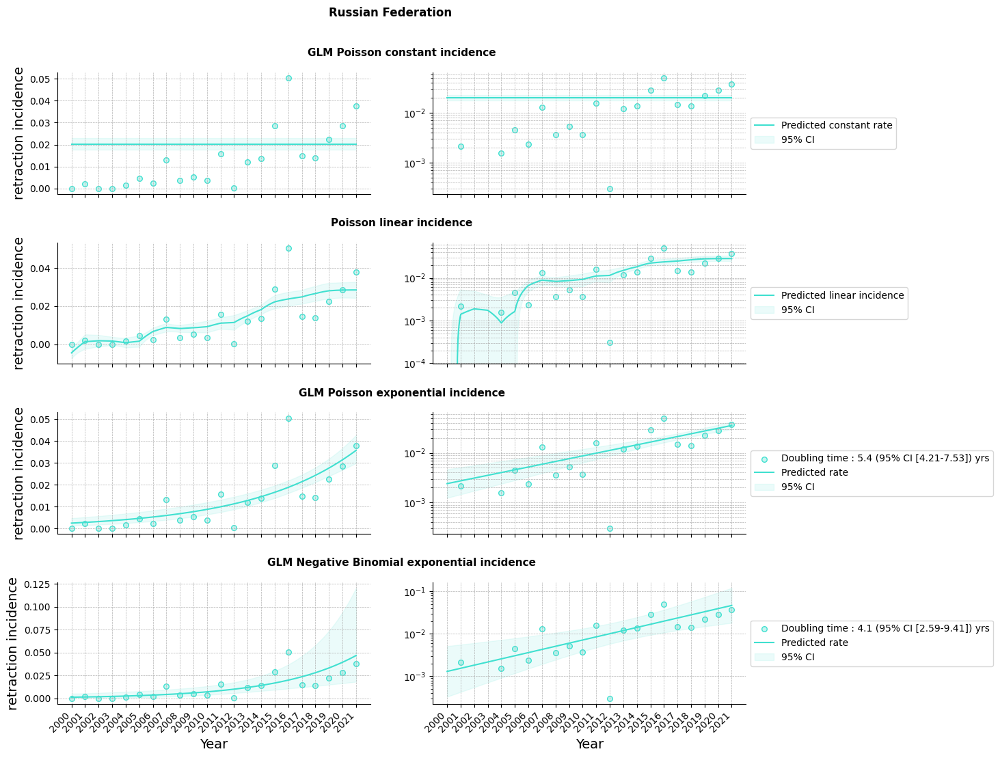

 29%|██▊       | 6/21 [00:04<00:11,  1.32it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


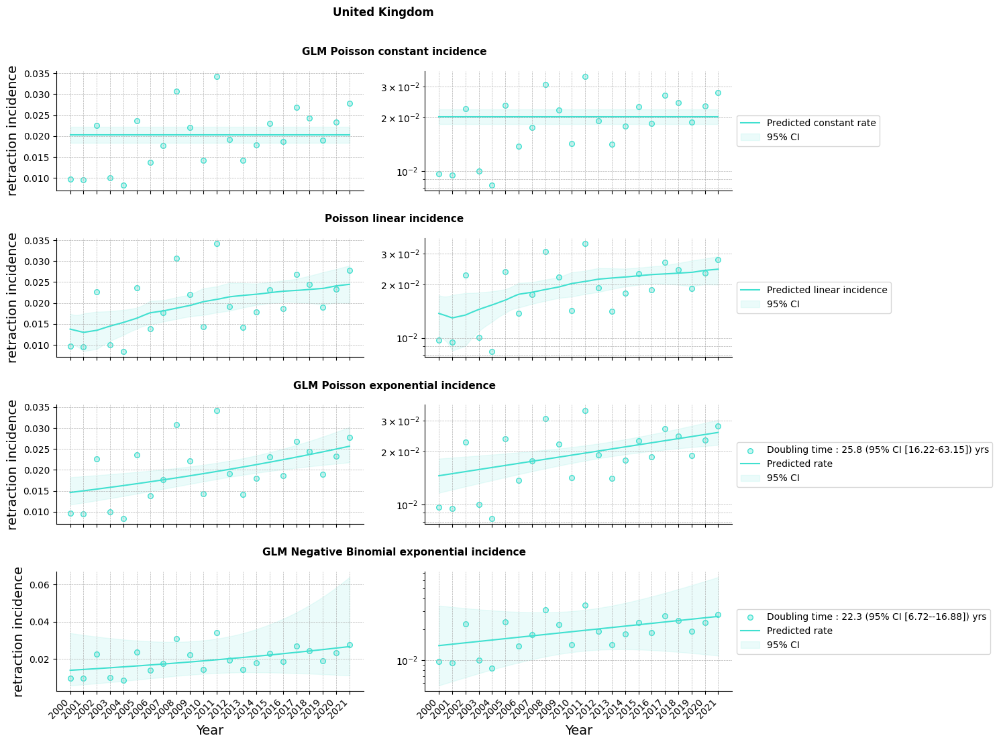

 33%|███▎      | 7/21 [00:05<00:10,  1.31it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


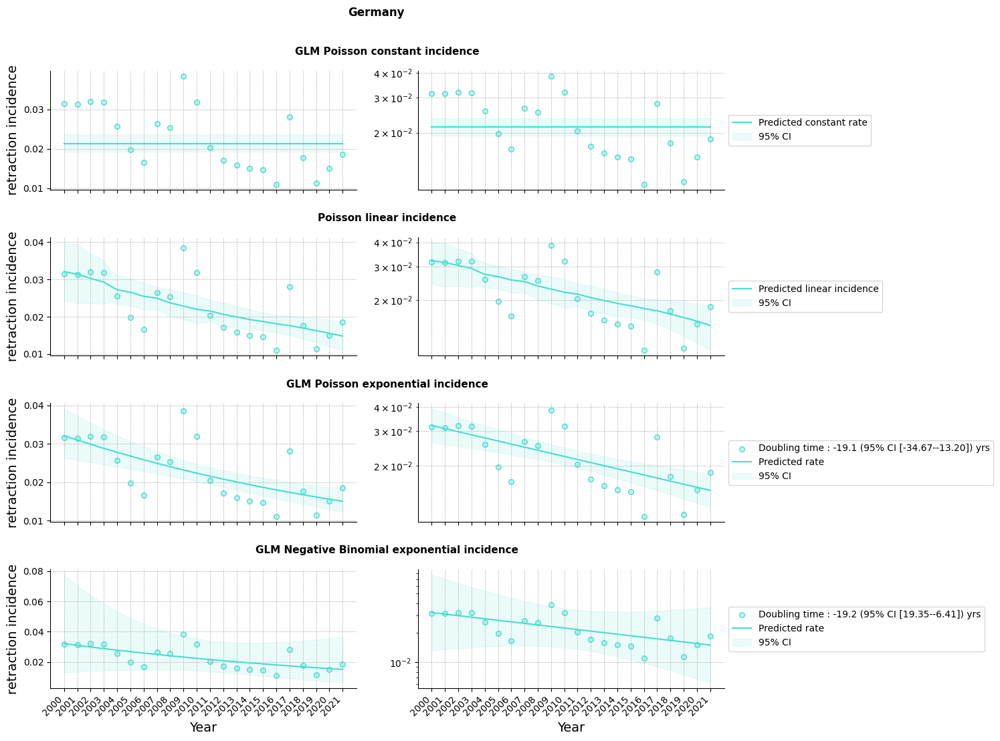

 38%|███▊      | 8/21 [00:06<00:09,  1.37it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


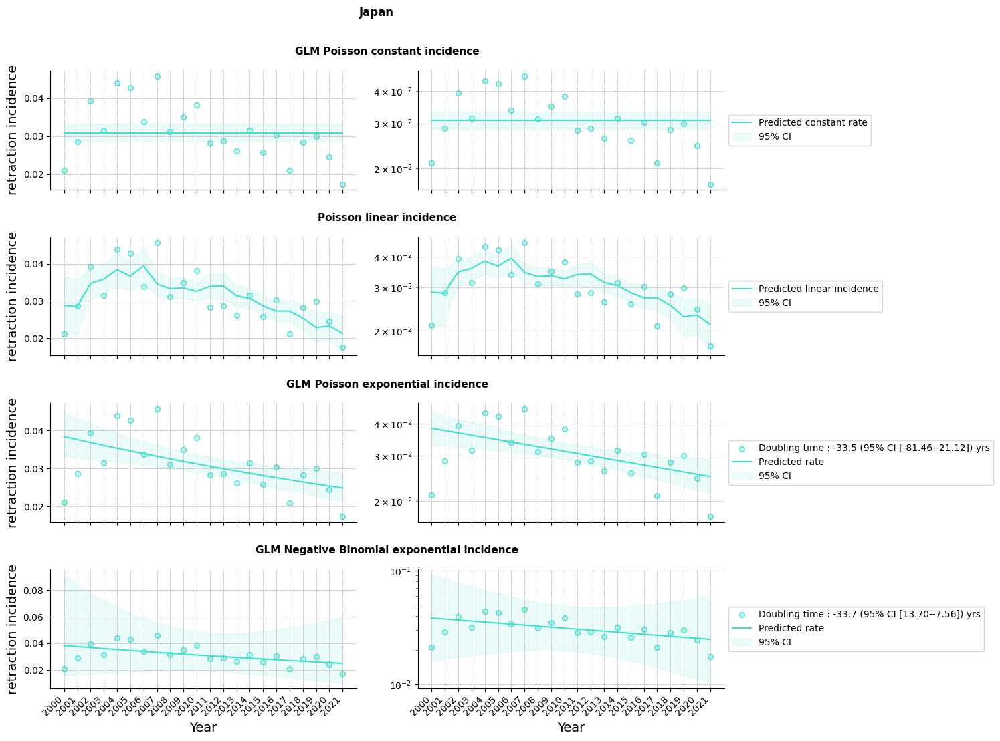

 43%|████▎     | 9/21 [00:06<00:08,  1.36it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


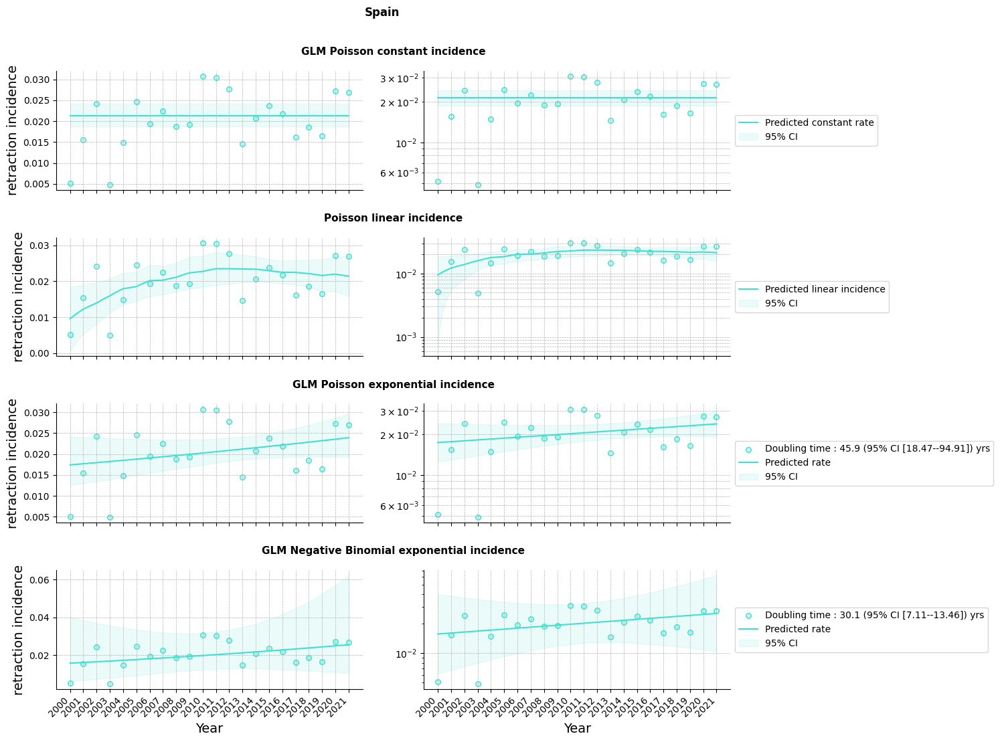

 48%|████▊     | 10/21 [00:07<00:08,  1.33it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


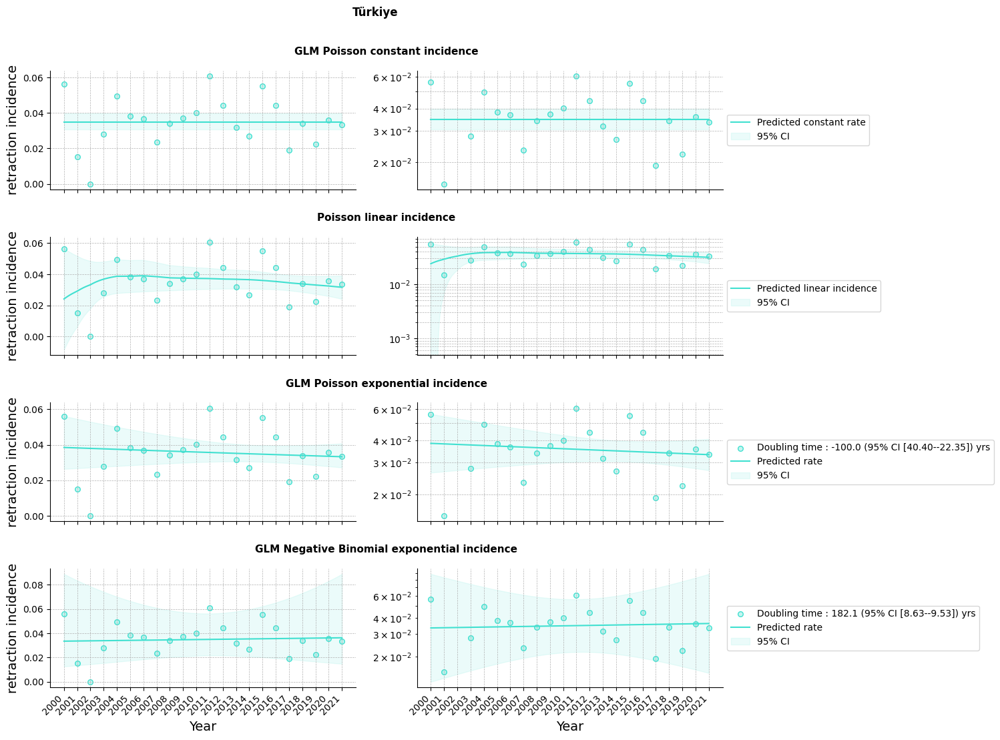

 52%|█████▏    | 11/21 [00:08<00:07,  1.36it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


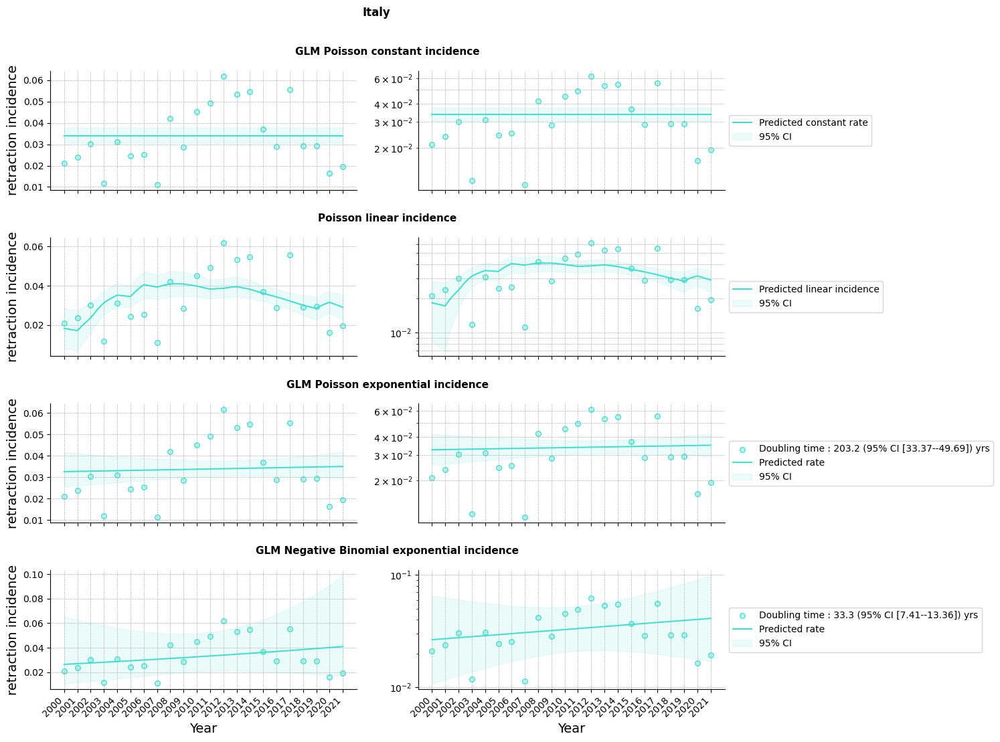

 57%|█████▋    | 12/21 [00:09<00:06,  1.35it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


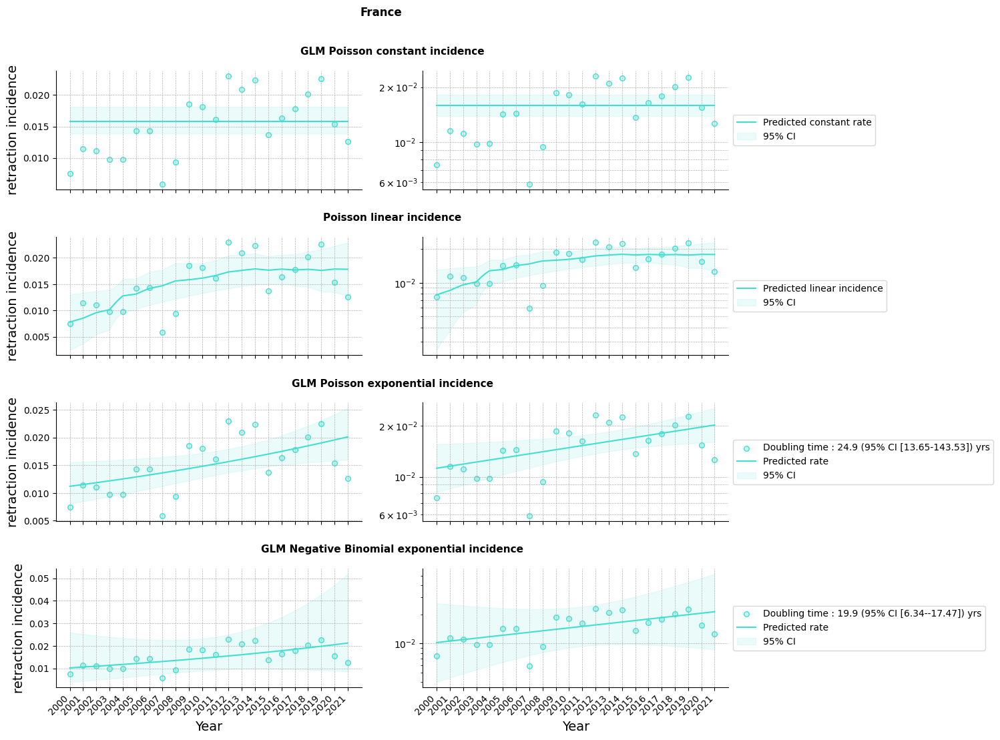

 62%|██████▏   | 13/21 [00:09<00:05,  1.35it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


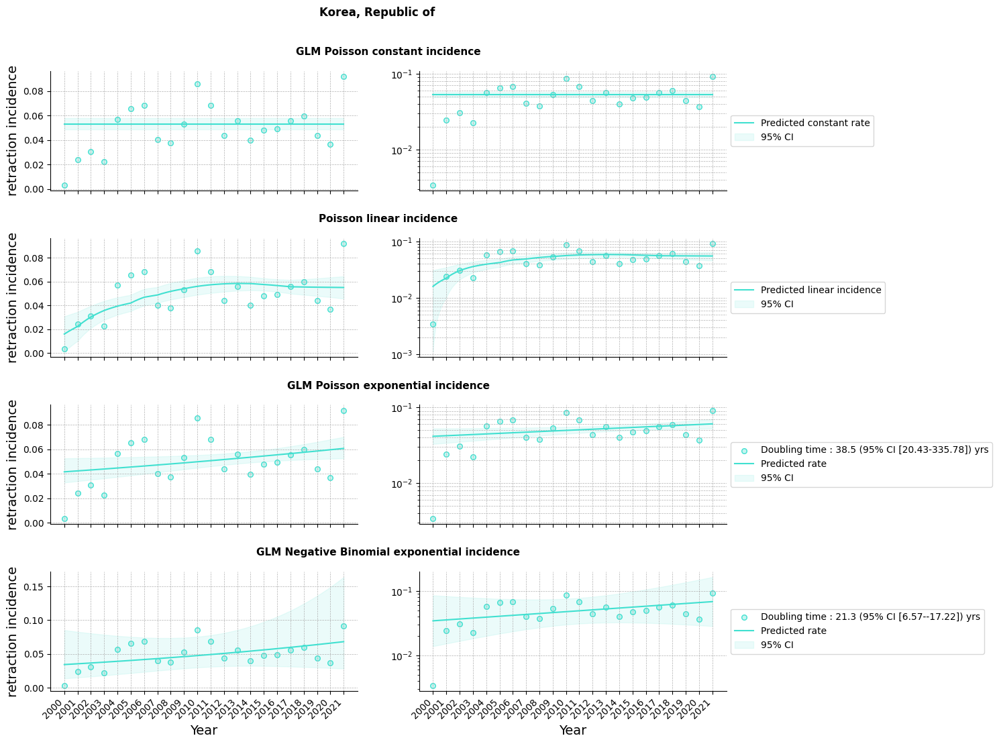

 67%|██████▋   | 14/21 [00:10<00:05,  1.37it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


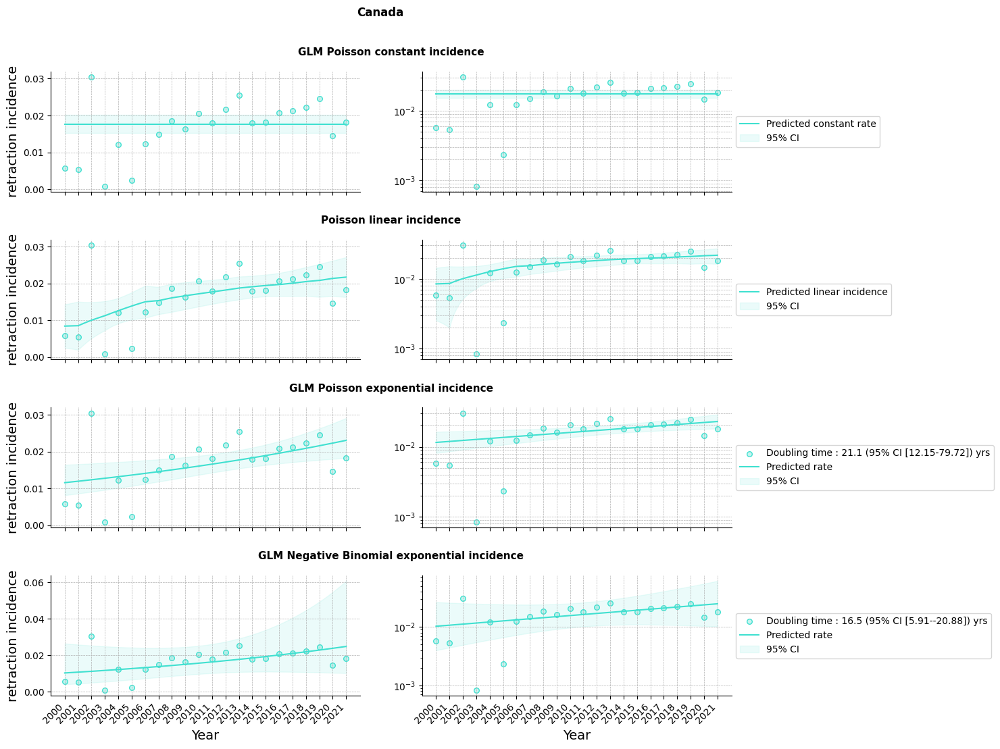

 71%|███████▏  | 15/21 [00:11<00:04,  1.36it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


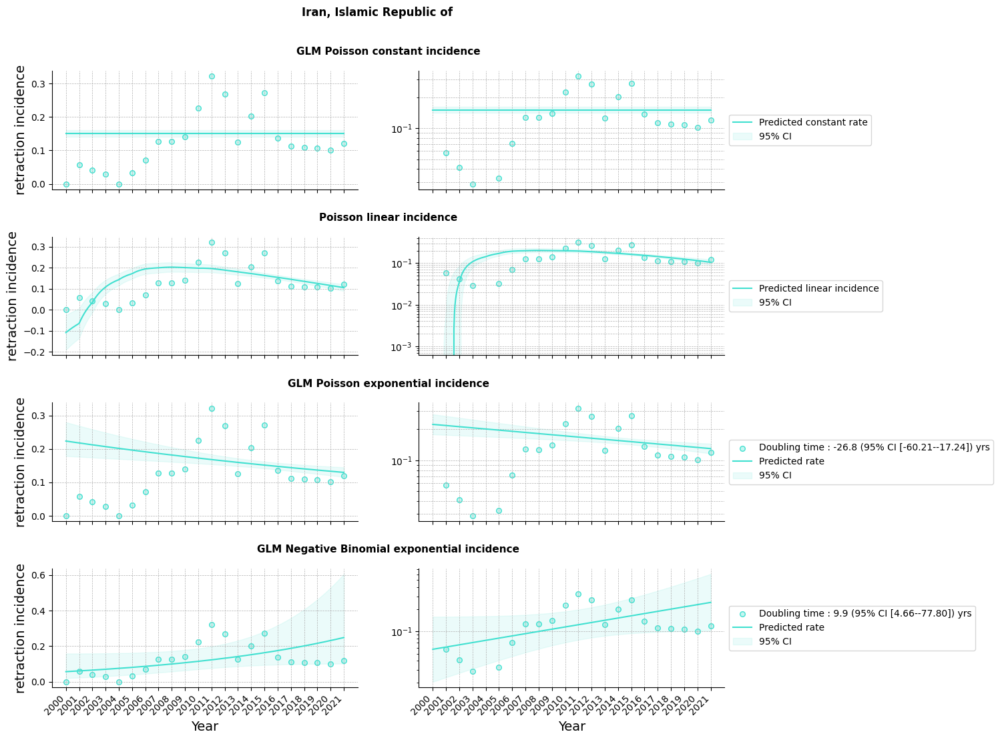

 76%|███████▌  | 16/21 [00:11<00:03,  1.34it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


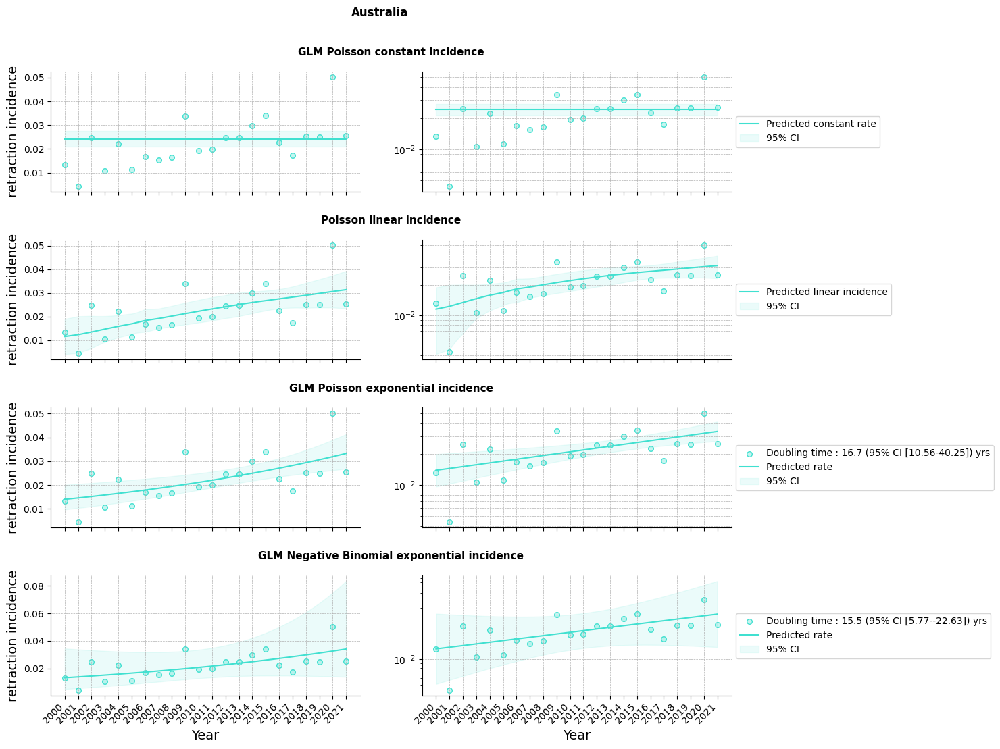

 81%|████████  | 17/21 [00:12<00:02,  1.39it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


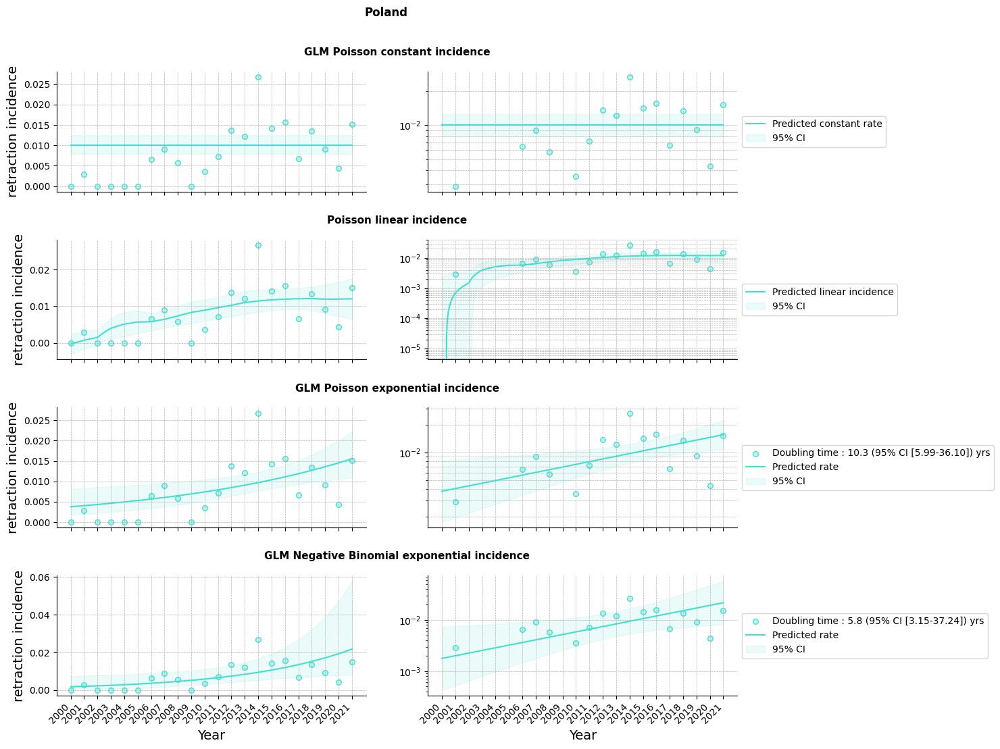

 86%|████████▌ | 18/21 [00:13<00:02,  1.36it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


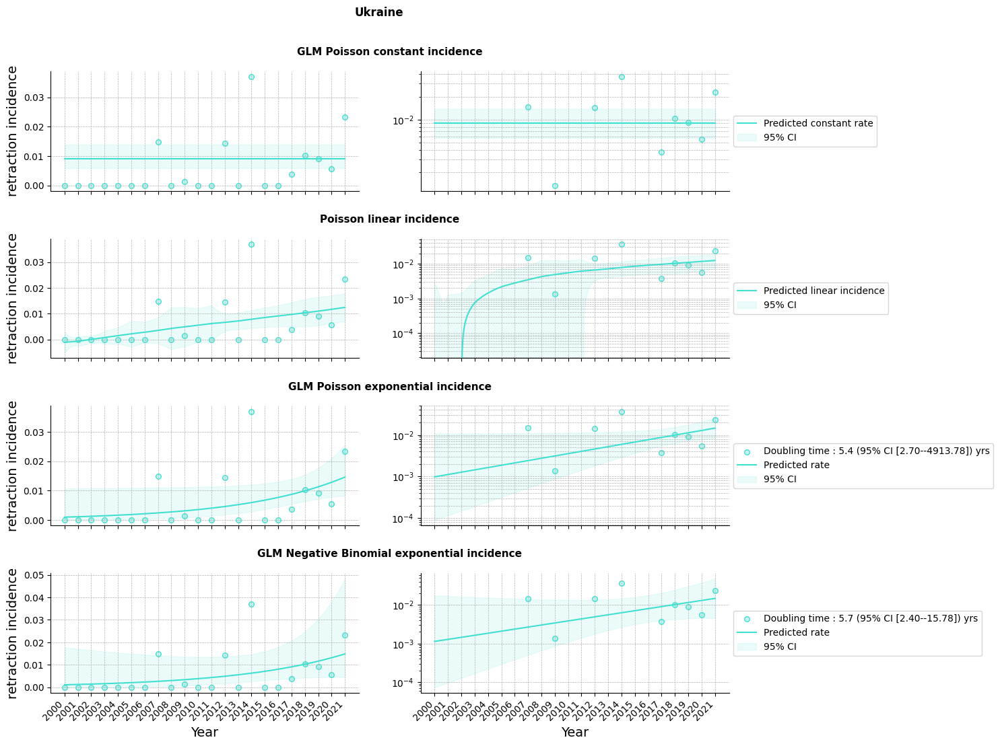

 90%|█████████ | 19/21 [00:14<00:01,  1.33it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


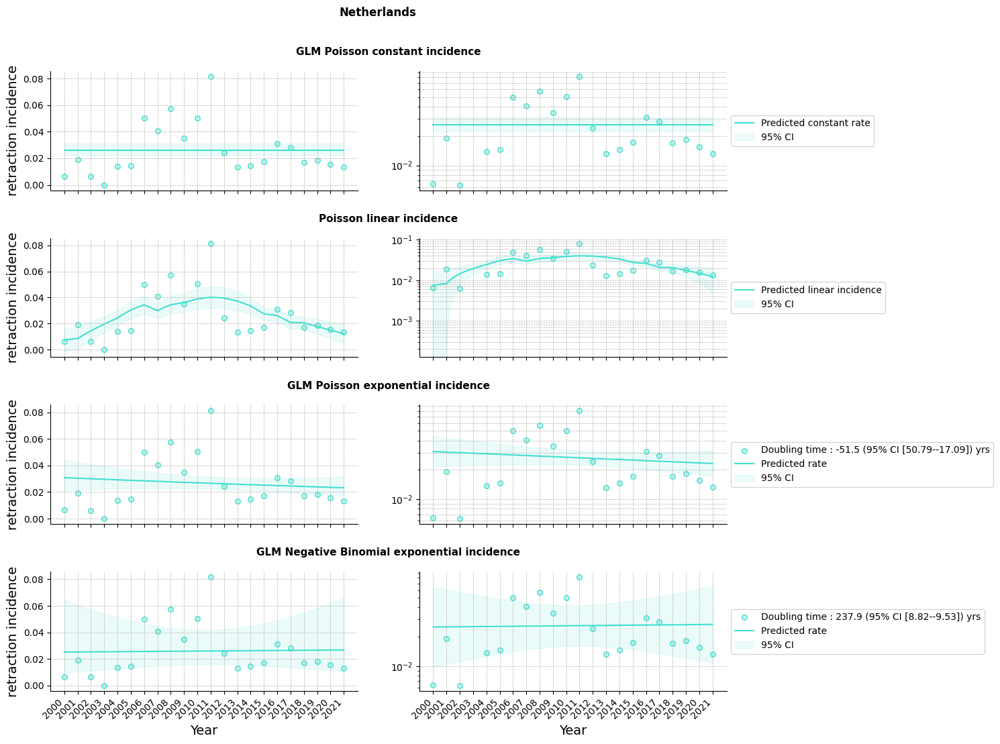

 95%|█████████▌| 20/21 [00:14<00:00,  1.33it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


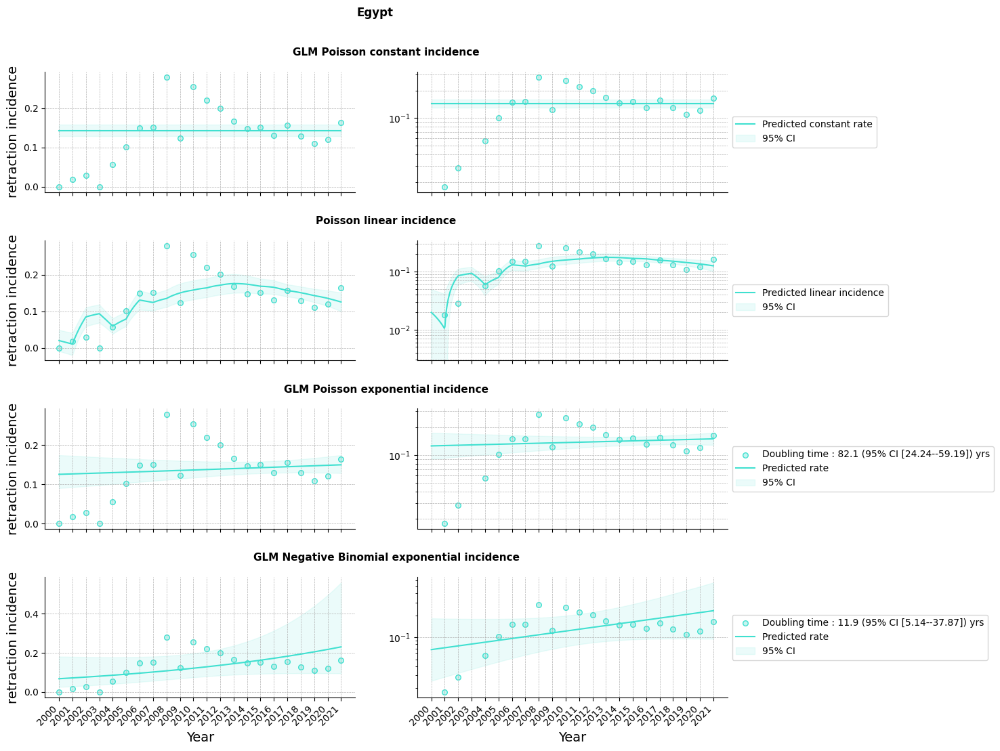

100%|██████████| 21/21 [00:15<00:00,  1.34it/s]


In [59]:
### robust analysis: different time period

SCALE = 1e2
alpha=1
df = works_retracted_count_bycountry.copy()
start_year=2000
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
title = 'retraction incidence works'
results_country_df2 = pd.DataFrame()
for i in tqdm(country_selected_set):
    df_i = df[df.country_code==i]
    results_df = try_all_fit(SCALE,alpha,df_i,start_year,end_year,True,output_folder,title,country_code_name_dict,i)
    results_country_df2 = pd.concat([results_country_df2,results_df])
results_country_df2 = results_country_df2.rename(columns={'field_id_scaled':'country_code','field_name':'country_name'})

In [60]:
## rolling window (5 years) average and std
df = works_retracted_count_bycountry.copy()
start_year=2000
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
SCALE = 1e2
df['retracted_incidence'] = (df['retracted'] / df['total'])*SCALE
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
window_size = 5
df_rolling = retracted_rolling_average(df,window_size,'country_code')
df_rolling

,country_code,year,mean,var
0,AU,2004,0.015045,0.000057
1,AU,2005,0.014649,0.000059
2,AU,2006,0.017148,0.000032
3,AU,2007,0.015261,0.000018
4,AU,2008,0.016435,0.000013
...,...,...,...,...
373,US,2017,0.029164,0.000018
374,US,2018,0.028574,0.000013
375,US,2019,0.028249,0.000011
376,US,2020,0.027981,0.000010


In [61]:
df = results_country_df[results_country_df.model!='GLM Negative Binomial exponential incidence']
df = df[['start year','end year','country_code','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df1 = df.sort_values(by=['country_code', 'model_order'])

df = results_country_df2[results_country_df2.model!='GLM Negative Binomial exponential incidence']
df = df[['start year','end year','country_code','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df2 = df.sort_values(by=['country_code', 'model_order'])

df = pd.concat([df1,df2]).drop(columns='model_order')
df.head()

,start year,end year,country_code,model,ΔBIC,ΔBIC_weighted
0,1992,2021,AU,constant,45.657763,1.217707e-10
0,1992,2021,AU,exponential,0.000000,1.000000e+00
0,1992,2021,BR,constant,0.000000,1.000000e+00
0,1992,2021,CA,constant,26.018152,2.239903e-06
0,1992,2021,CA,exponential,0.000000,9.999978e-01


In [ ]:
start_year = 1992
end_year = 2021
alpha = 1
model_func_name = {'GLM Poisson exponential incidence','GLM Negative Binomial exponential incidence'}
country_set = set((results_country_df[results_country_df.model.isin(model_func_name)].query('best_model==1').country_name))
country_set = country_set - {'Germany'}
df0 = results_country_df[results_country_df.country_name.isin(country_set)]
sorted_countrys = list(df0['country_code'].unique())
sorted_countrys.sort()
df1 = df0[df0.best_model==1][['start year','end year', 'country_code','country_name','doubling time','doubling_time_lower','doubling_time_upper']]
df2 = pd.DataFrame()
for country in sorted_countrys:
    temp = pd.read_csv(os.path.join('./Plots/plots_countries', f'observed_df_{country}_{start_year}_{end_year}_{'GLM Poisson exponential incidence'}.csv')).rename(columns={'field_id_scaled':'country_code','field_name':'country_name'})
    temp = temp[temp.year==29][['country_code','observed_rate']]
    df2 = pd.concat([df2,temp])
df3 = works_retracted_count_bycountry[works_retracted_count_bycountry.country_code.isin(sorted_countrys)]
df3 = df3[df3.year == end_year]
df3 = df3[['country_code','retracted']].reset_index(drop=True)
df = df1.merge(df2,on='country_code').merge(df3,on='country_code')
df = df[df.country_code.isin({'CN','IN','RU'})]
df = df[['start year','end year', 'country_code', 'country_name','doubling time','doubling_time_lower','doubling_time_upper','observed_rate','retracted']]
df = df.sort_values(by=['country_name'],ascending=[False]).reset_index(drop=True).reset_index()
temp1 = df.rename(columns={'doubling time':'doubling_time'}).drop(columns=['index','observed_rate','retracted'])

start_year = 2000
end_year = 2021
alpha = 1
model_func_name = {'GLM Poisson exponential incidence','GLM Negative Binomial exponential incidence'}
country_set = set((results_country_df2[results_country_df2.model.isin(model_func_name)].query('best_model==1').country_name))
df0 = results_country_df2[results_country_df2.country_name.isin(country_set)]
sorted_countrys = list(df0['country_code'].unique())
sorted_countrys.sort()
df1 = df0[df0.best_model==1][['start year','end year', 'country_code','country_name','doubling time','doubling_time_lower','doubling_time_upper']]
df2 = pd.DataFrame()
for country in sorted_countrys:
    temp = pd.read_csv(os.path.join('./Plots/plots_countries', f'observed_df_{country}_{start_year}_{end_year}_{'GLM Poisson exponential incidence'}.csv')).drop(columns='field_name').rename(columns={'field_id_scaled':'country_code'})
    temp = temp[temp.year==21][['country_code','observed_rate']]
    df2 = pd.concat([df2,temp])
df3 = works_retracted_count_bycountry[works_retracted_count_bycountry.country_code.isin(sorted_countrys)]
df3 = df3[df3.year == end_year]
df3 = df3[['country_code','retracted']].reset_index(drop=True)
df = df1.merge(df2,on='country_code').merge(df3,on='country_code')
df = df[df.country_code.isin({'CN','IN','RU'})]
df = df[['start year','end year', 'country_code', 'country_name','doubling time','doubling_time_lower','doubling_time_upper','observed_rate','retracted']]
df = df.sort_values(by=['country_code'],ascending=[False]).reset_index(drop=True).reset_index()
temp2 = df.rename(columns={'doubling time':'doubling_time'}).drop(columns=['index','observed_rate','retracted'])
df = pd.concat([temp1,temp2])
df

,start year,end year,country_code,country_name,doubling_time,doubling_time_lower,doubling_time_upper
0,1992,2021,RU,Russian Federation,3.922565,2.656798,7.491898
1,1992,2021,IN,India,4.847692,3.586137,7.478539
2,1992,2021,CN,China,3.346901,2.600997,4.692638
0,2000,2021,RU,Russian Federation,4.066629,2.593798,9.409748
1,2000,2021,IN,India,6.793077,3.973644,23.386759
2,2000,2021,CN,China,3.510058,2.559565,5.583482


## Publishers

In [ ]:
sql = """
  CREATE TABLE `project_name.dataset_name.works_retracted_count_bypublisher` AS

  WITH works_info_retracted_publisher AS (
    SELECT DISTINCT
      wir.work_id,
      wir.is_retracted,
      wir.publication_year,
      si.host_organization AS publisher_id,
      si.host_organization_name AS publisher_name
    FROM
      `project_name.dataset_name.works_info` wir
    JOIN
      `project_name.dataset_name.sources_info` si
    ON
      wir.journal_id = si.source_id
    WHERE 
      publication_year BETWEEN '1992-01-01' AND '2021-01-01'
  )

  SELECT
    publication_year,
    publisher_id,
    publisher_name,
    COUNT(work_id) AS total_works,
    SUM(CAST(is_retracted AS INT64)) AS retracted_works
  FROM
    works_info_retracted_publisher
  GROUP BY
    publication_year, publisher_id, publisher_name
  ORDER BY
    publication_year, publisher_id;
"""
##output info
new_table_name = "works_retracted_count_bypublisher"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)

In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
output_folder = './Plots/plots_publishers'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

works_retracted_count_bypublisher = pd.read_csv(f'./Data/works_retracted_count_bypublisher.csv.gz', compression='gzip').rename(columns={'publication_year':'year'}).dropna()
works_retracted_count_bypublisher['year'] = works_retracted_count_bypublisher['year'].str[:4].astype(int)
works_retracted_count_bypublisher['publisher_id'] = works_retracted_count_bypublisher['publisher_id'].str.extract(r'P(\d+)', expand=False).astype(int)
publisher_id_name_dict = works_retracted_count_bypublisher.drop_duplicates('publisher_id')[['publisher_id','publisher_name']].set_index('publisher_id').to_dict()['publisher_name']
publisher_name_id_dict = works_retracted_count_bypublisher.drop_duplicates('publisher_id')[['publisher_id','publisher_name']].set_index('publisher_name').to_dict()['publisher_id']
print(f'{len(set(works_retracted_count_bypublisher.publisher_id))} publishers')

9765 publishers


In [64]:
publisher_id_selected = set(works_retracted_count_bypublisher[works_retracted_count_bypublisher.year==2021].groupby(['publisher_id','publisher_name']).total_works.sum().to_frame().sort_values(by='total_works',ascending=False).reset_index().head(20).publisher_id)#.union({4310319869})
works_retracted_count_bypublisher = works_retracted_count_bypublisher[works_retracted_count_bypublisher.publisher_id.isin(publisher_id_selected)]
works_retracted_count_bypublisher = works_retracted_count_bypublisher.rename(columns={'total_works':'total','retracted_works':'retracted'})

with pd.option_context('display.max_colwidth', None):
    display(works_retracted_count_bypublisher[['publisher_id','publisher_name']].drop_duplicates().sort_values(by='publisher_id').reset_index(drop=True))

,publisher_id,publisher_name
0,4310310987,Multidisciplinary Digital Publishing Institute
1,4310311648,Oxford University Press
2,4310311721,Cambridge University Press
3,4310315671,Lippincott Williams & Wilkins
4,4310319748,EDP Sciences
5,4310319808,Institute of Electrical and Electronics Engineers
6,4310319869,Hindawi Publishing Corporation
7,4310319900,Springer Science+Business Media
8,4310319908,Nature Portfolio
9,4310319965,Springer Nature


In [65]:
#start_year publishers
start_year_dict = {
    4310310987 : 1996, 
    4310315671 : 1998, 
    4310319869 : 1997, 
    4310320256 : 2000, 
    4310320448 : 1997, 
    4310320527 : 2007
    }
start_year_keys = set(start_year_dict.keys())
temp = works_retracted_count_bypublisher[['publisher_id','publisher_name']].drop_duplicates().query('publisher_id.isin(@start_year_keys)')
temp['start_year'] = temp['publisher_id'].map(start_year_dict)
display(temp)
start_year_dict.update({key: 1992 for key in list(publisher_id_selected - start_year_keys)})

,publisher_id,publisher_name,start_year
2,4310310987,Multidisciplinary Digital Publishing Institute,1996
797,4310315671,Lippincott Williams & Wilkins,1998
1573,4310319869,Hindawi Publishing Corporation,1997
1697,4310320256,BioMed Central,2000
1774,4310320448,Medknow,1997
1796,4310320527,Frontiers Media,2007


  0%|          | 0/20 [00:00<?, ?it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


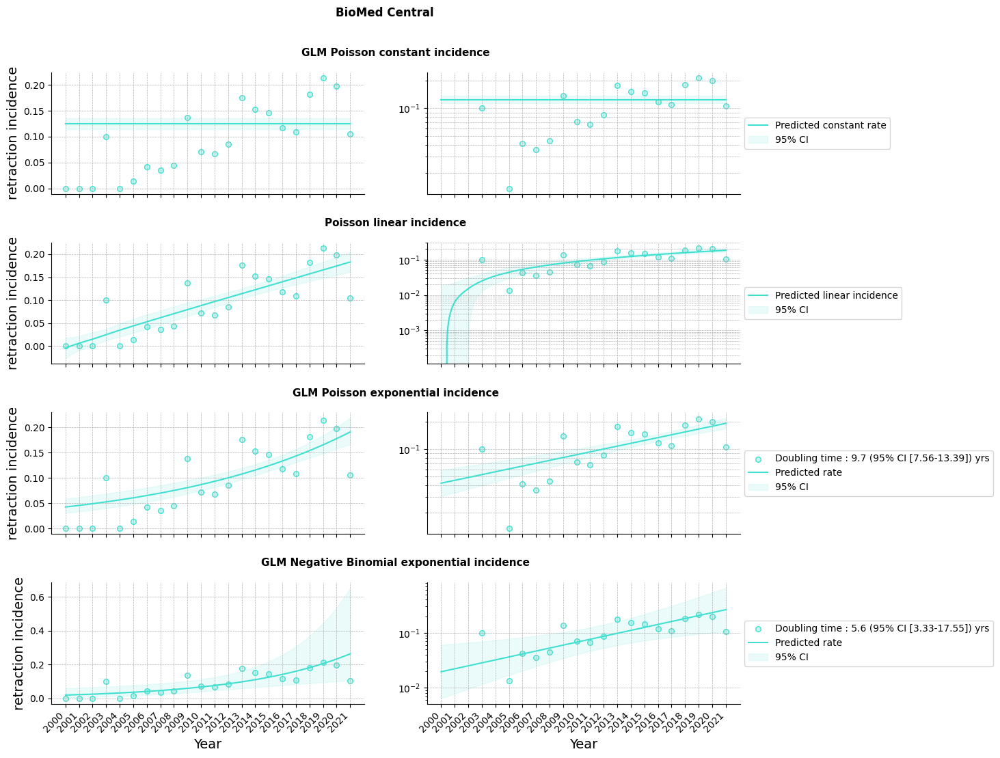

  5%|▌         | 1/20 [00:00<00:14,  1.27it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


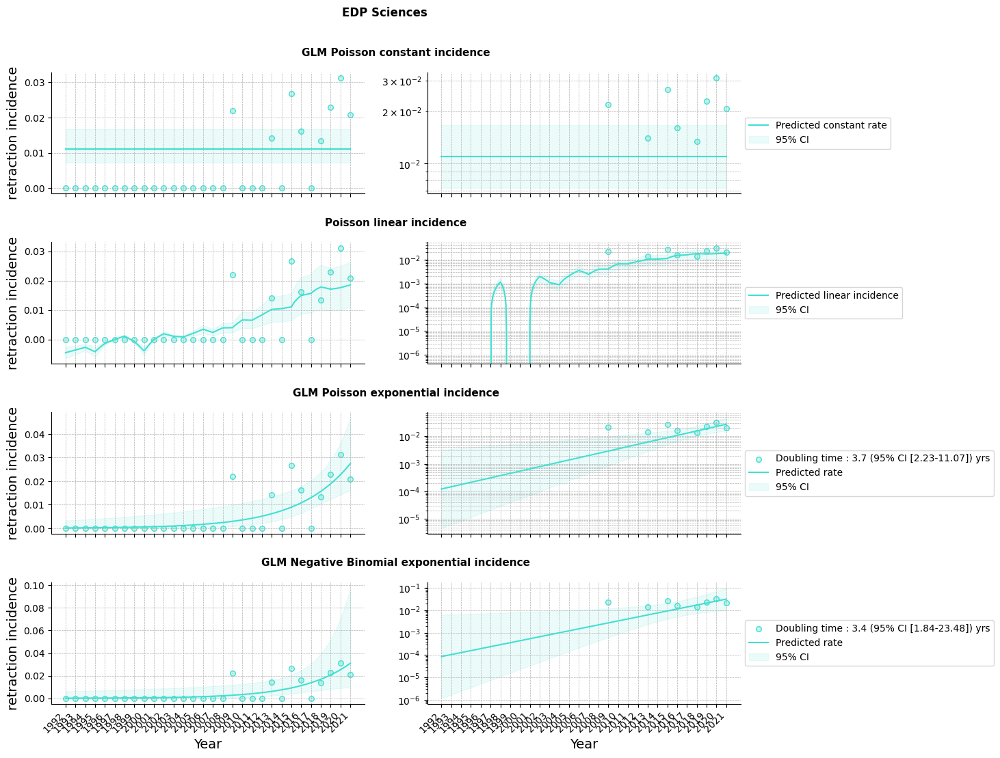

 10%|█         | 2/20 [00:01<00:15,  1.15it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


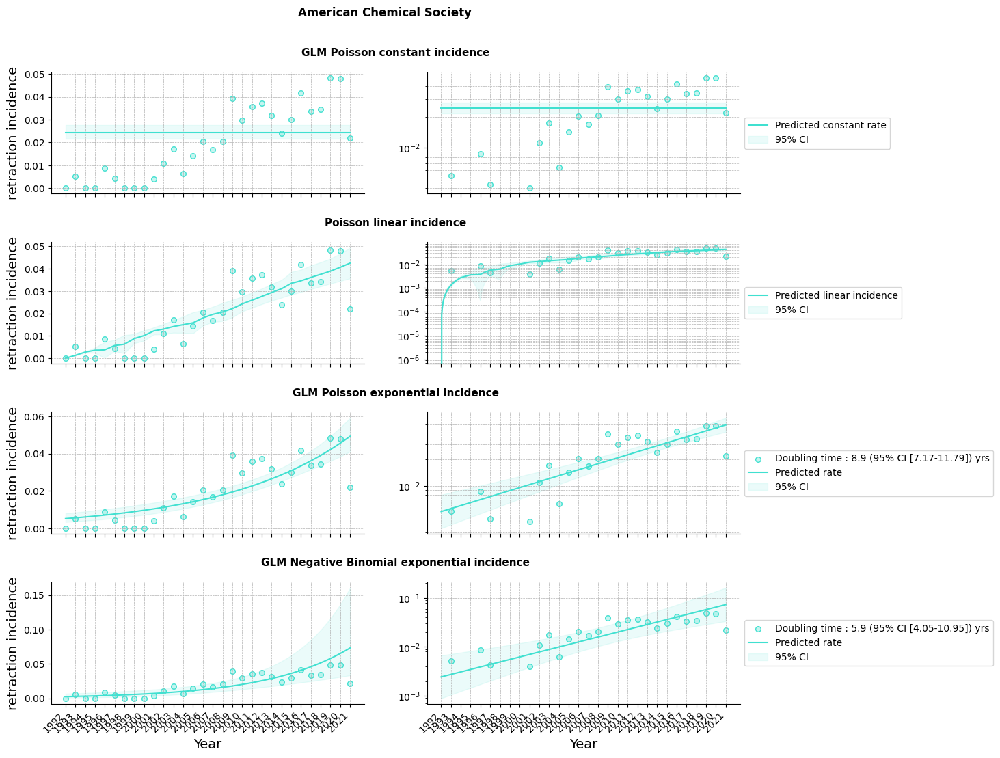

 15%|█▌        | 3/20 [00:02<00:14,  1.16it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


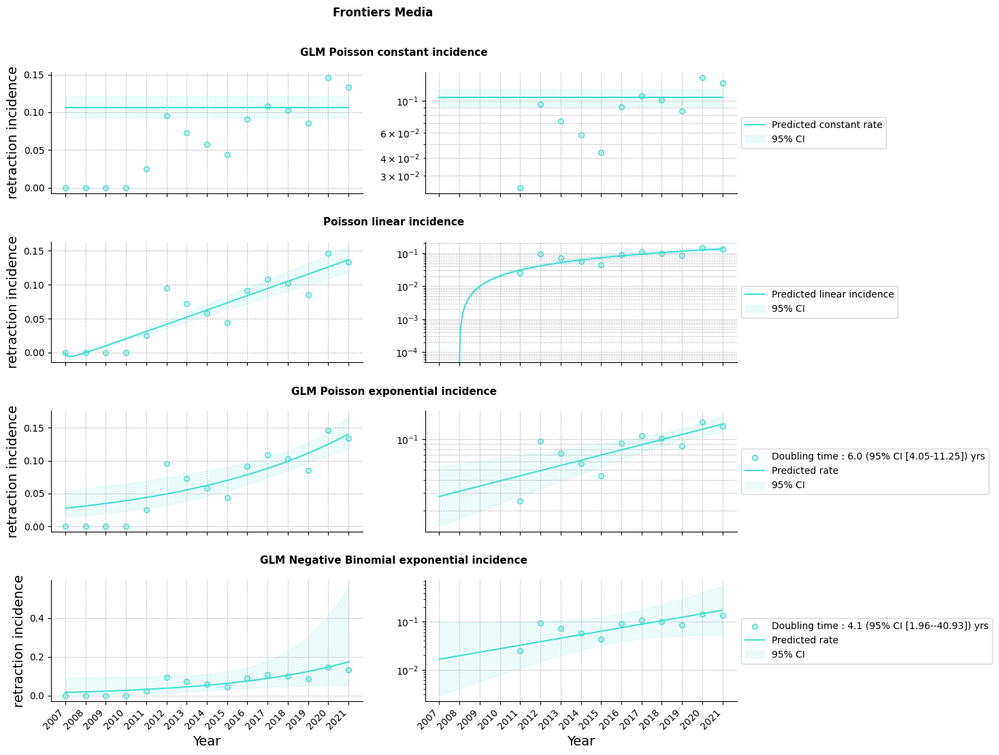

 20%|██        | 4/20 [00:03<00:12,  1.26it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


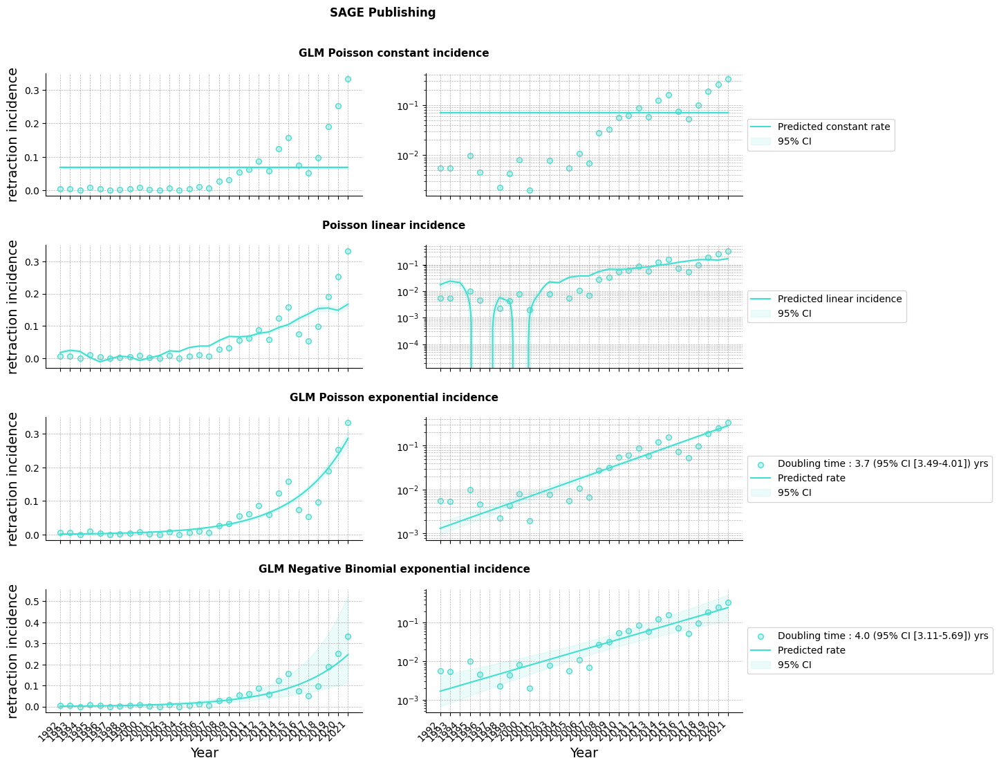

 25%|██▌       | 5/20 [00:04<00:12,  1.23it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


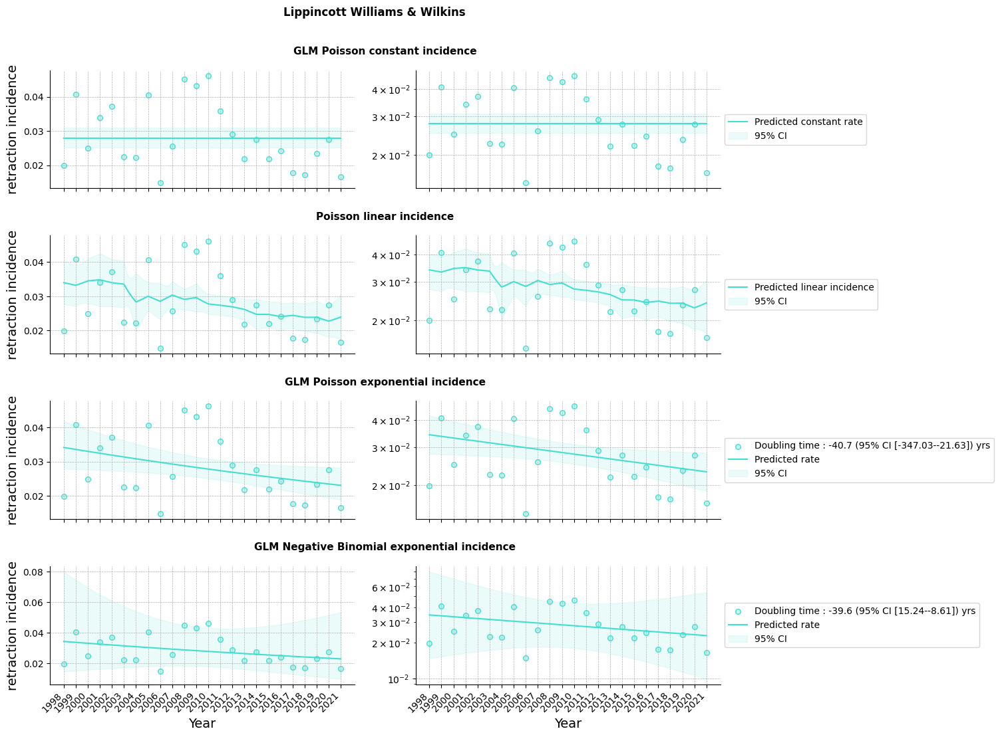

 30%|███       | 6/20 [00:04<00:11,  1.25it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


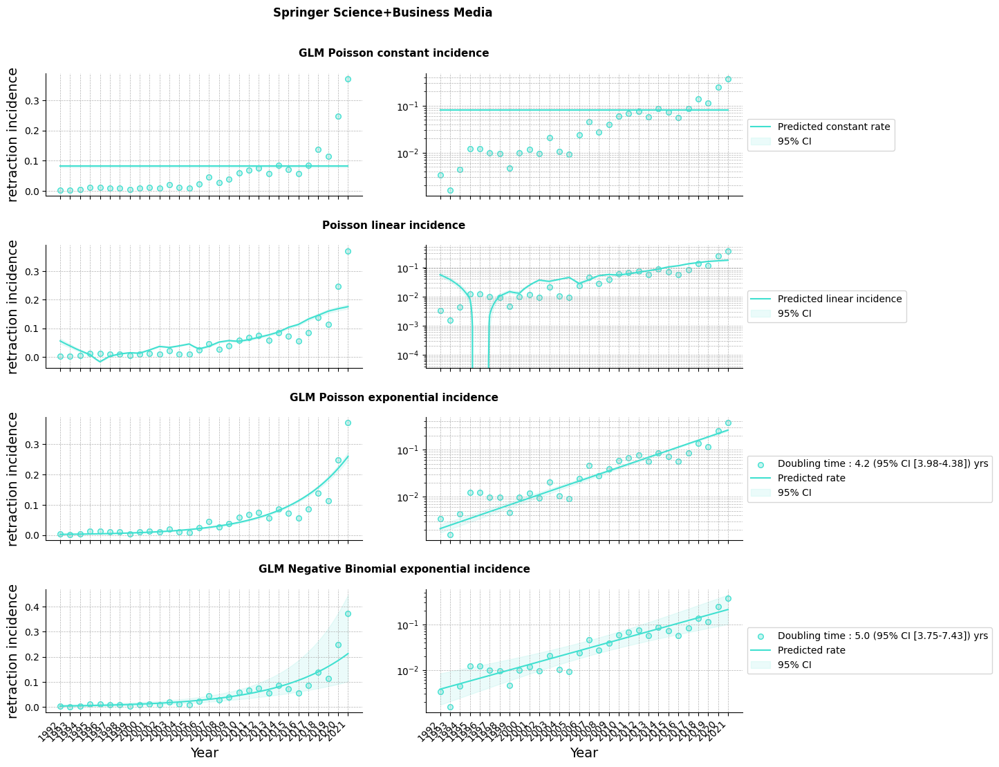

 35%|███▌      | 7/20 [00:05<00:10,  1.22it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


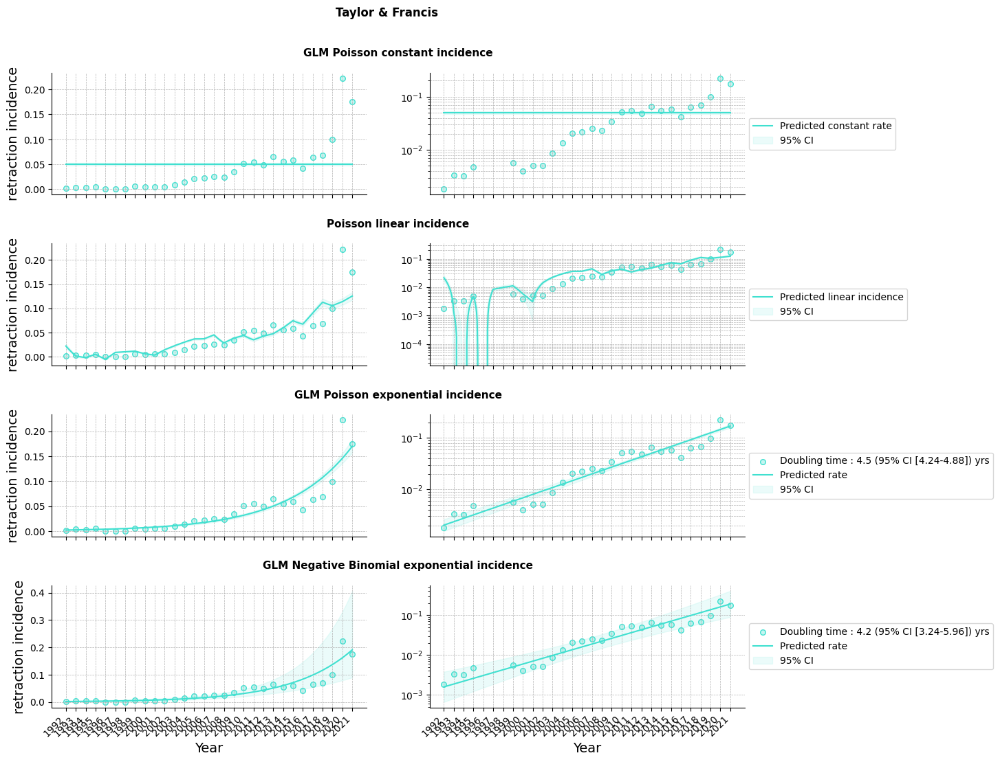

 40%|████      | 8/20 [00:06<00:10,  1.20it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


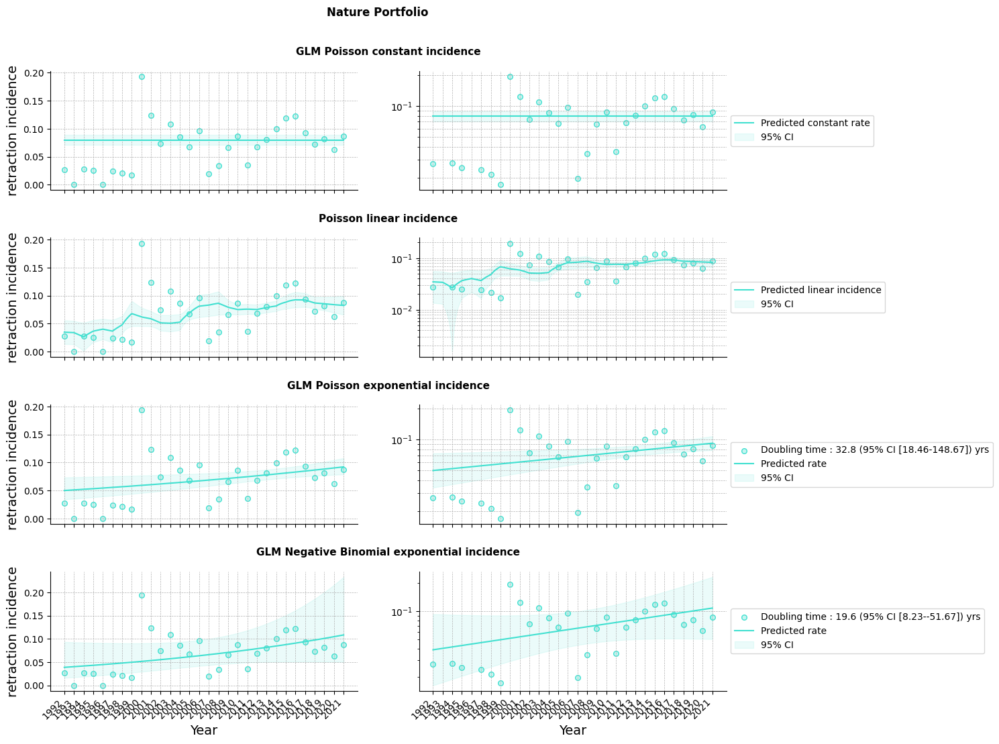

 45%|████▌     | 9/20 [00:07<00:08,  1.24it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


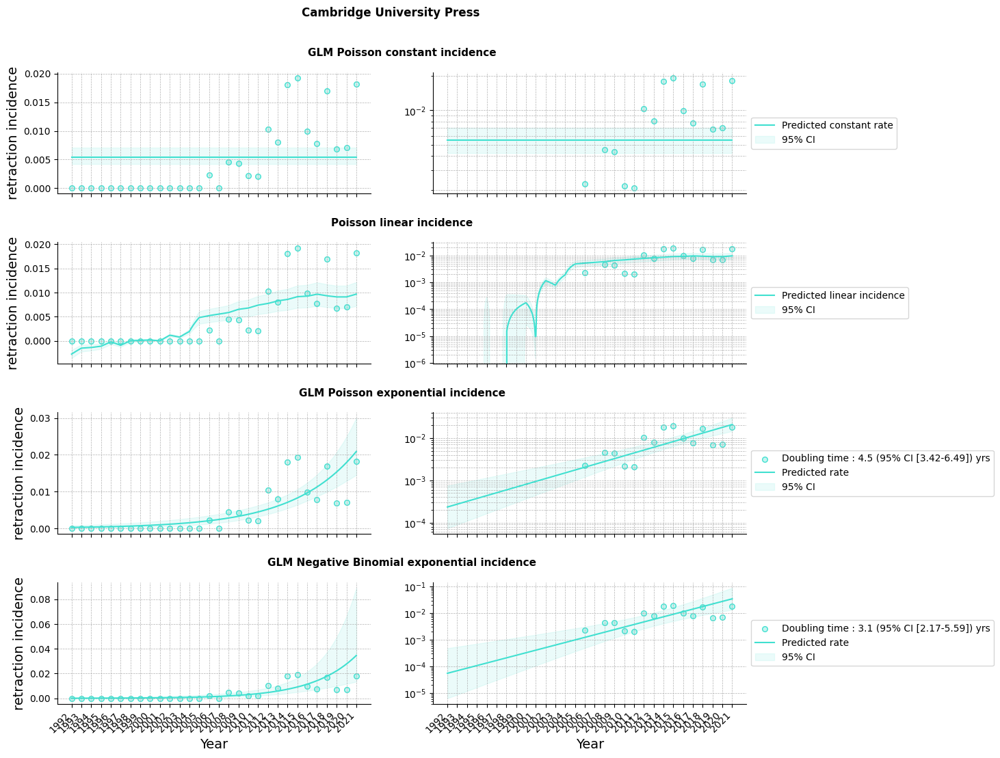

 50%|█████     | 10/20 [00:08<00:08,  1.19it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


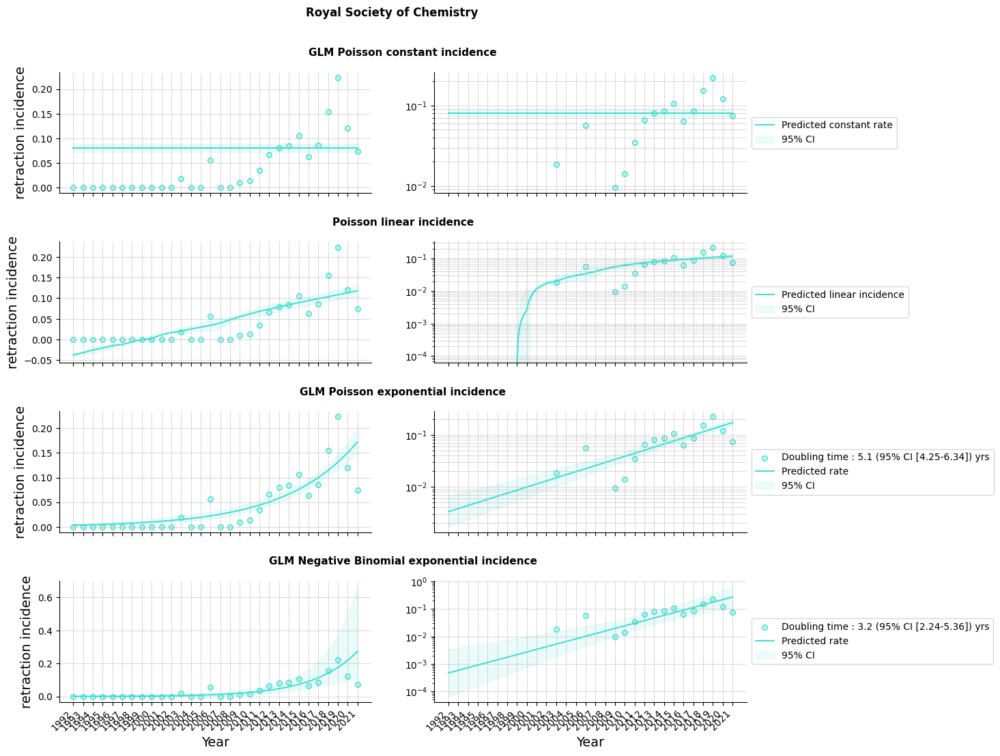

 55%|█████▌    | 11/20 [00:09<00:07,  1.18it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


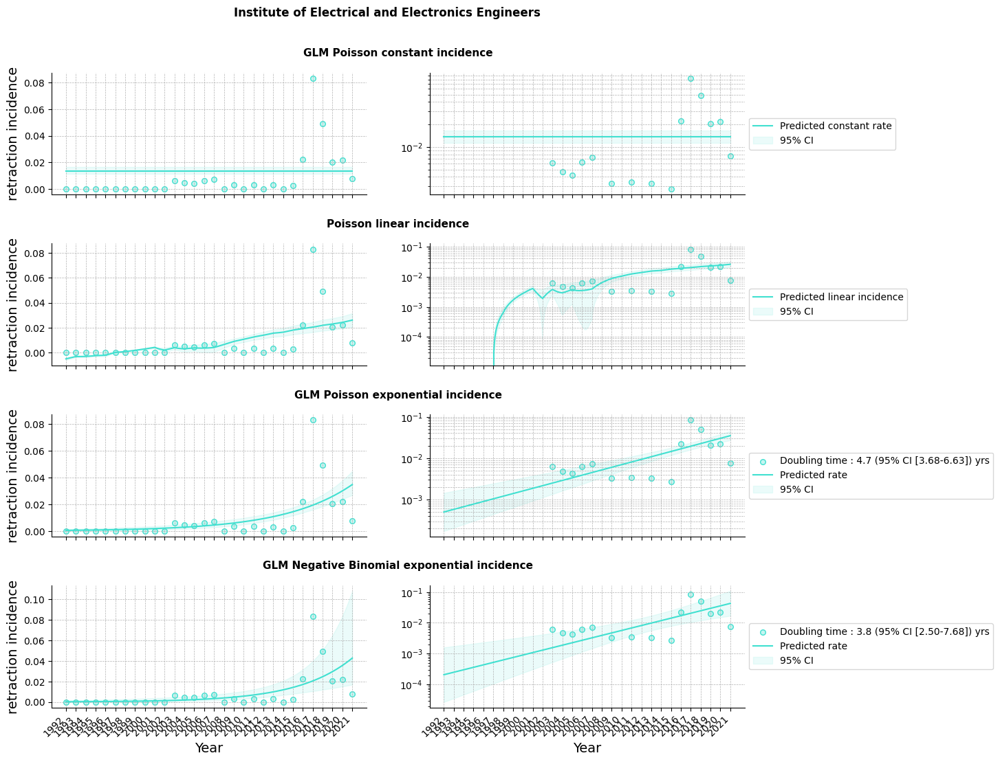

 60%|██████    | 12/20 [00:10<00:06,  1.17it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


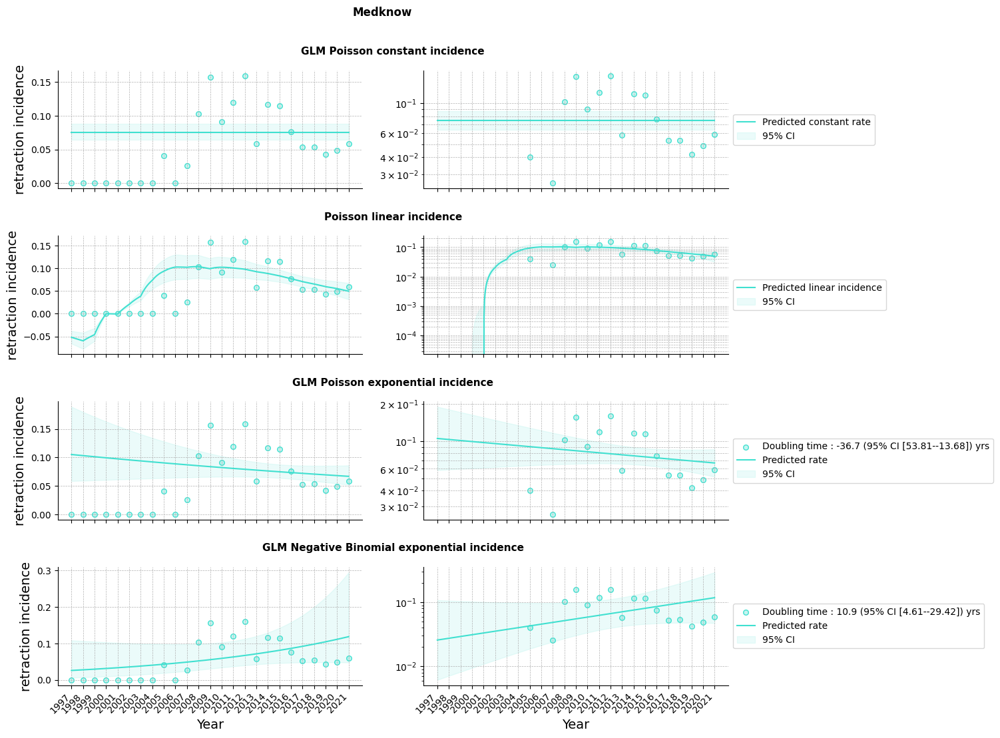

 65%|██████▌   | 13/20 [00:10<00:05,  1.18it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


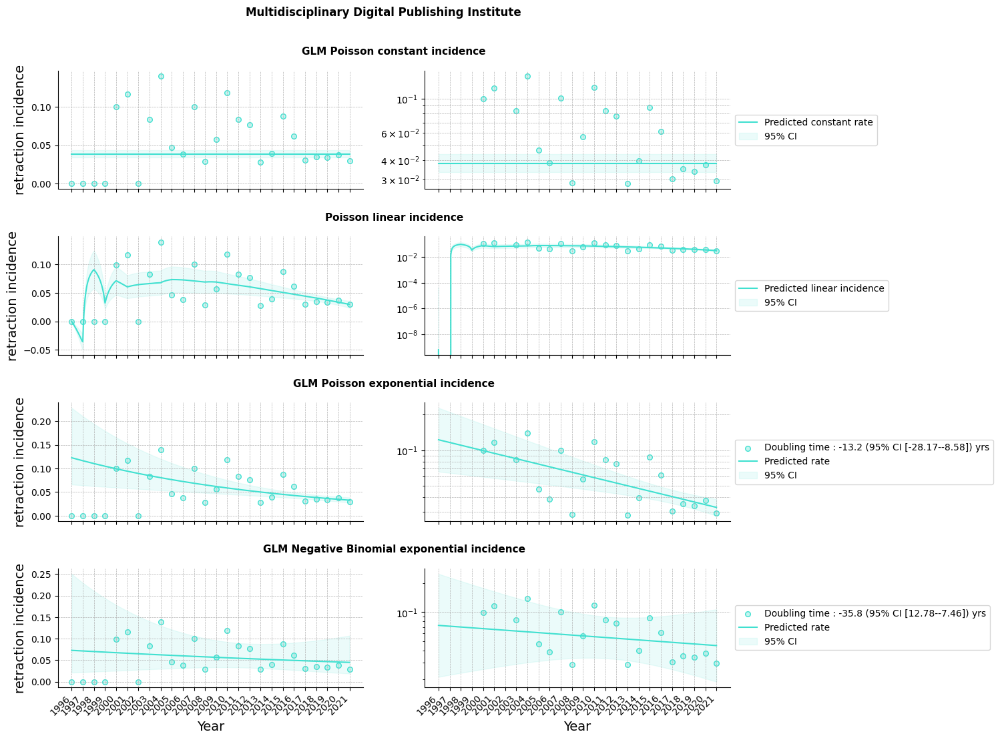

 70%|███████   | 14/20 [00:11<00:04,  1.23it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


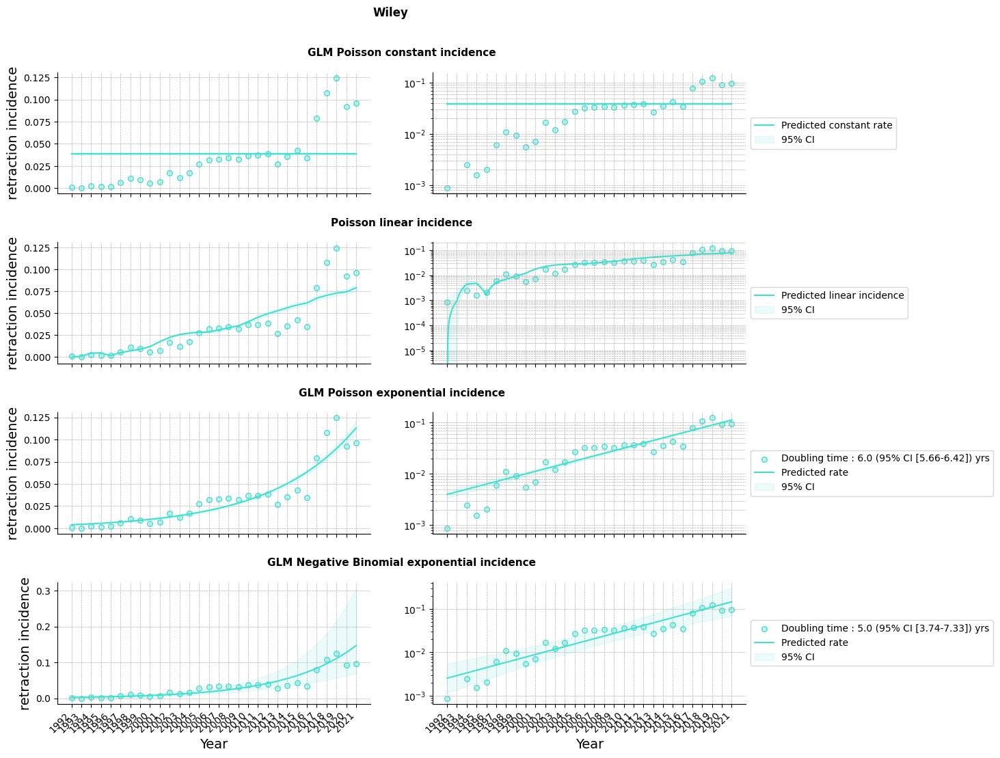

 75%|███████▌  | 15/20 [00:12<00:04,  1.20it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


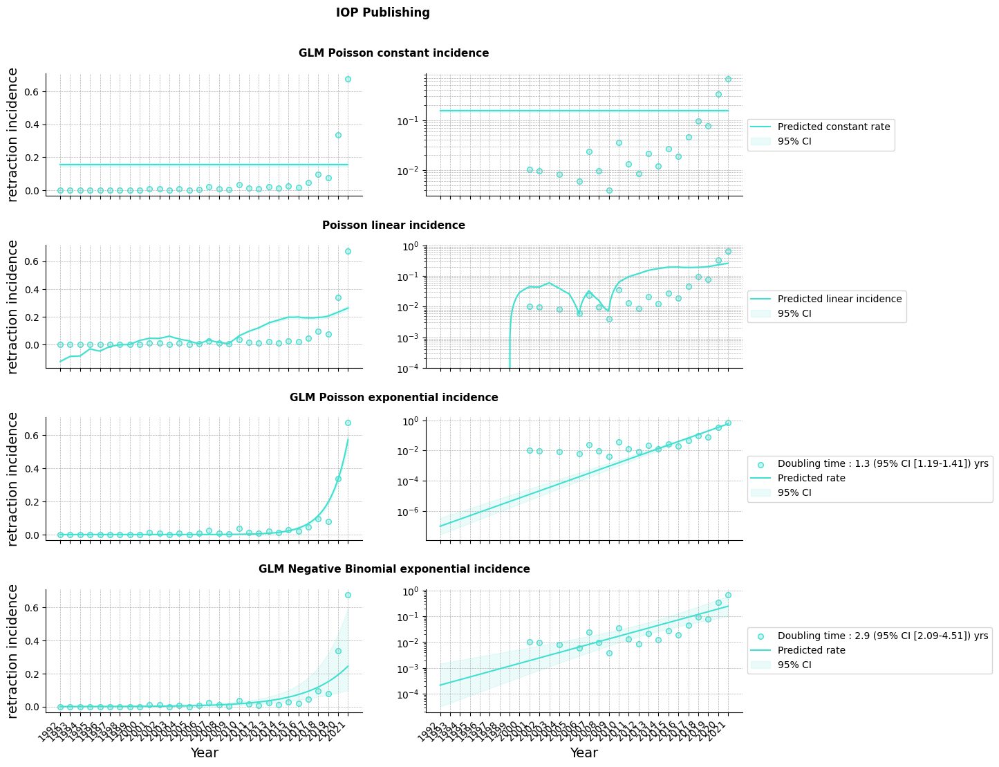

 80%|████████  | 16/20 [00:13<00:03,  1.19it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


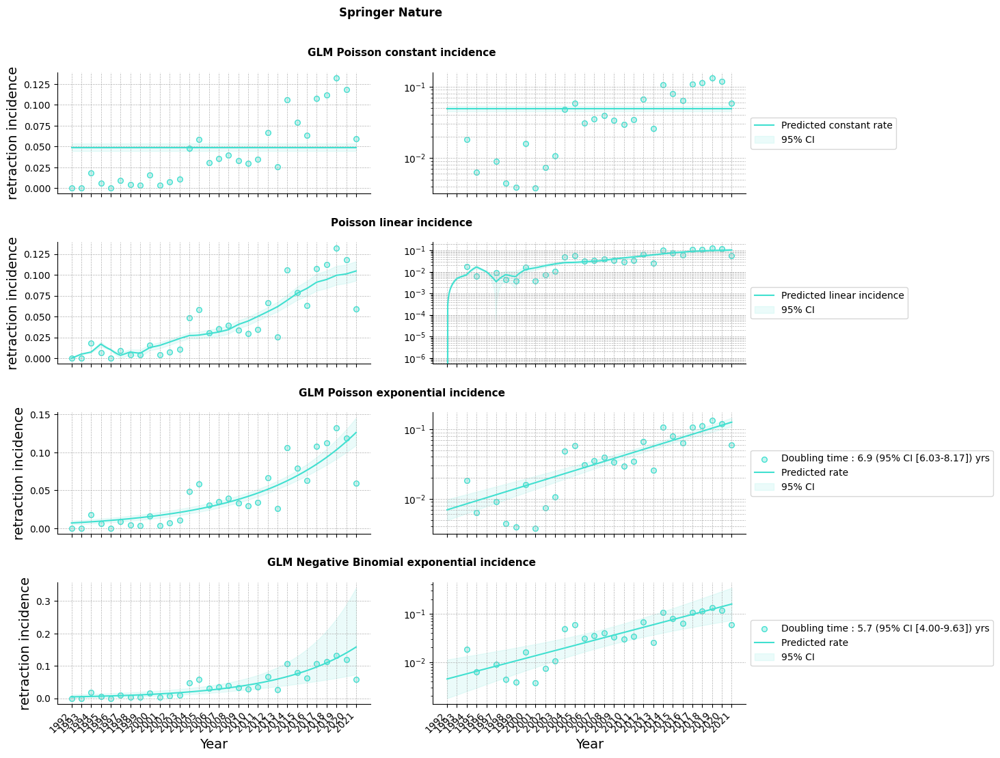

 85%|████████▌ | 17/20 [00:14<00:02,  1.17it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


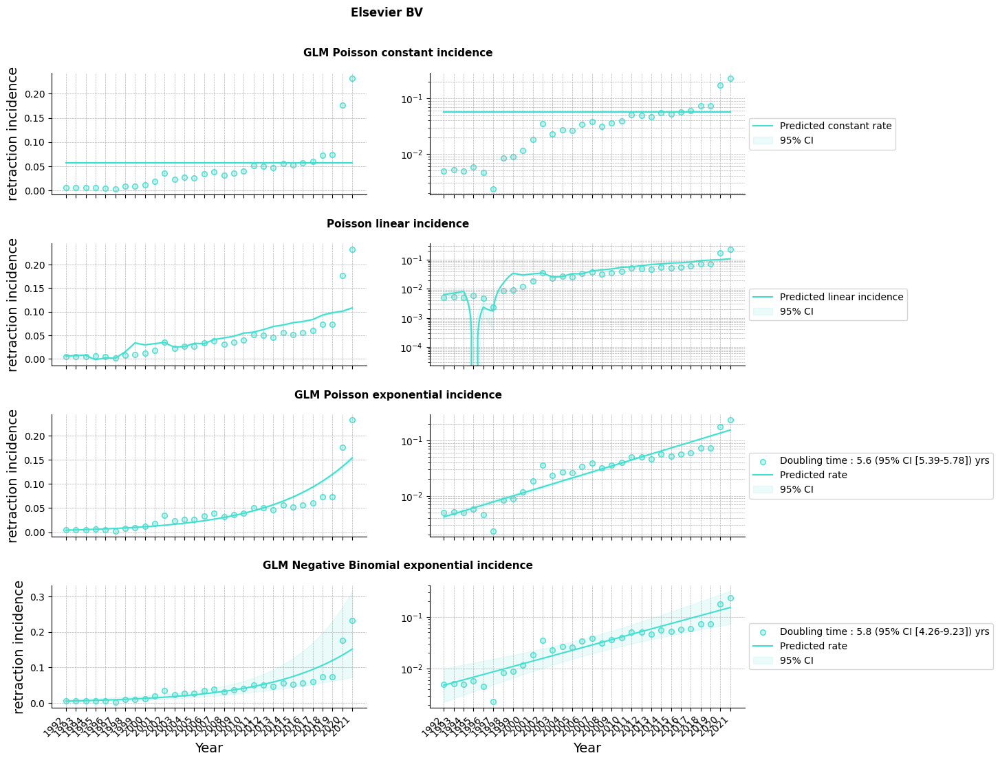

 90%|█████████ | 18/20 [00:15<00:01,  1.17it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


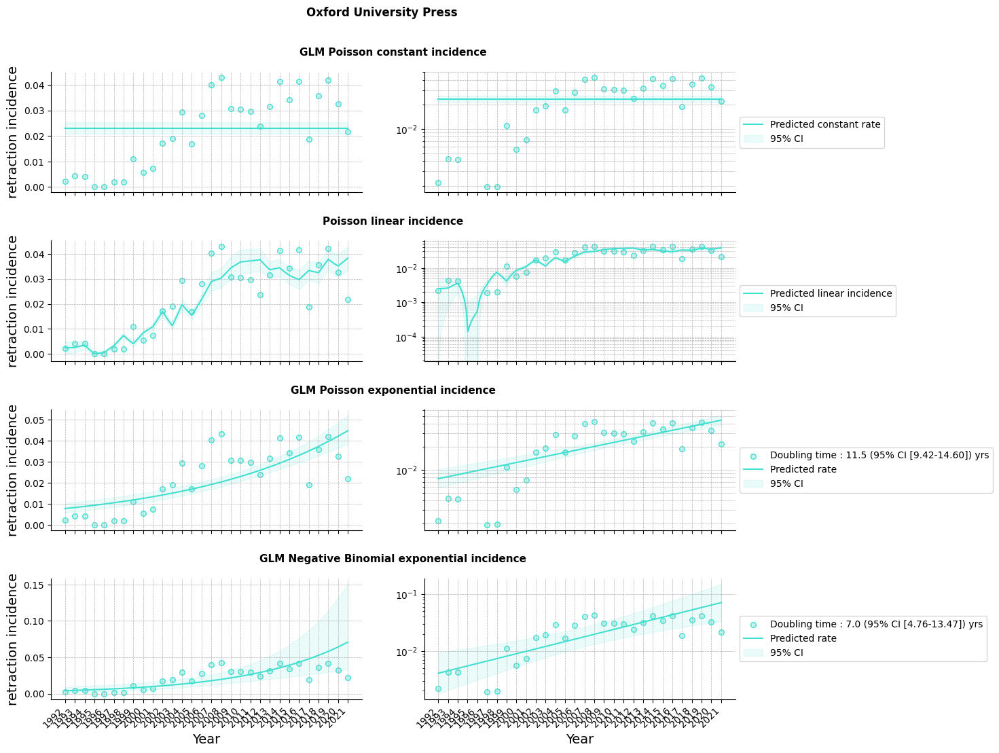

 95%|█████████▌| 19/20 [00:15<00:00,  1.20it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


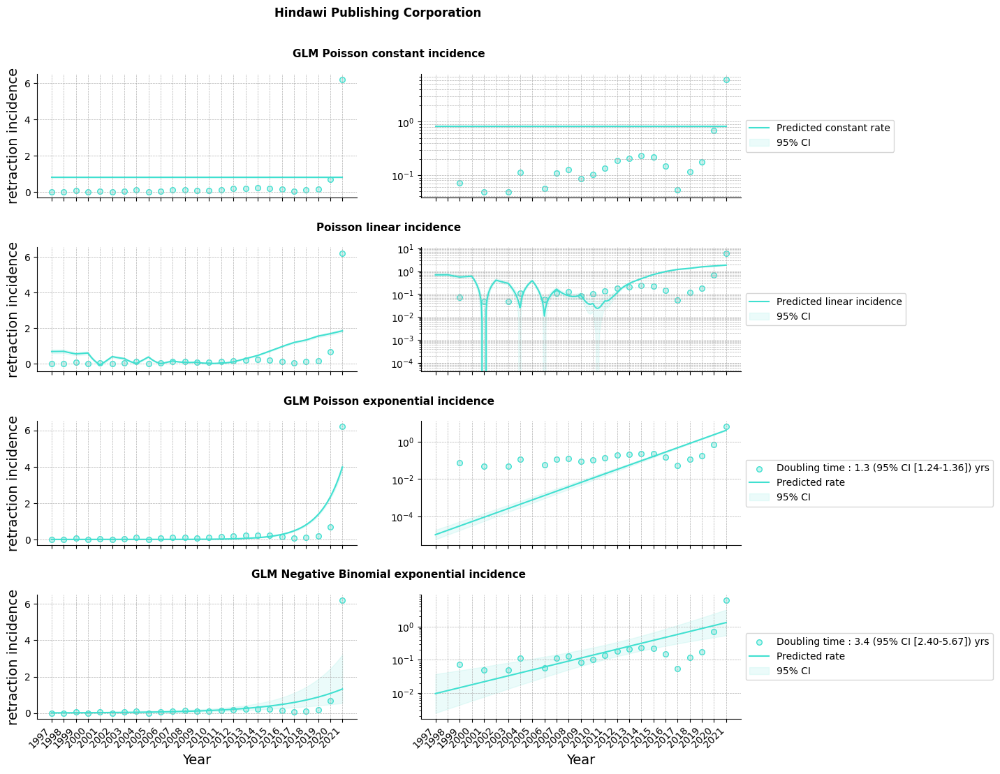

100%|██████████| 20/20 [00:16<00:00,  1.20it/s]


In [66]:
SCALE = 1e2
alpha=1
df = works_retracted_count_bypublisher
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
title = 'retraction incidence works'
results_publishers_df = pd.DataFrame()
for i in tqdm(list(publisher_id_selected)):
    df_i = df[df.publisher_id==i]
    df_i = df_i[df_i.year >= start_year_dict[i]]
    results_df = try_all_fit(SCALE,alpha,df_i,start_year,end_year,True,output_folder,title,publisher_id_name_dict,i)
    results_publishers_df = pd.concat([results_publishers_df,results_df])
results_publishers_df = results_publishers_df.rename(columns={'field_id_scaled':'publisher_id','field_name':'publisher_name'})

In [67]:
## rolling window (5 years) average and std
df = works_retracted_count_bypublisher.copy()
start_year=2000
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
SCALE = 1e2
df['retracted_incidence'] = (df['retracted'] / df['total'])*SCALE
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
window_size = 5
df_rolling = retracted_rolling_average(df,window_size,'publisher_id')
df_rolling

,publisher_id,year,mean,var
0,4310310987,2004,0.087811,0.002276
1,4310310987,2005,0.077276,0.002476
2,4310310987,2006,0.061700,0.002227
3,4310310987,2007,0.081733,0.001360
4,4310310987,2008,0.070768,0.001803
...,...,...,...,...
354,4310320990,2017,0.054059,0.000021
355,4310320990,2018,0.059383,0.000052
356,4310320990,2019,0.063009,0.000076
357,4310320990,2020,0.087792,0.001995


In [68]:
df = results_publishers_df[results_publishers_df.model!='GLM Negative Binomial exponential incidence']
df = df[['start year','end year','publisher_name','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df = df.sort_values(by=['publisher_name', 'model_order']).drop(columns='model_order')
df.head()

,start year,end year,publisher_name,model,ΔBIC,ΔBIC_weighted
0,1992,2021,American Chemical Society,constant,81.629001,1.881428e-18
0,1992,2021,American Chemical Society,exponential,0.000000,1.000000e+00
0,1992,2021,BioMed Central,constant,58.098405,2.421540e-13
0,1992,2021,BioMed Central,exponential,0.000000,1.000000e+00
0,1992,2021,Cambridge University Press,constant,62.353613,2.884596e-14


In [ ]:
start_year = 1992
end_year = 2021
alpha = 1
model_func_name = {'GLM Poisson exponential incidence','GLM Negative Binomial exponential incidence'}
publisher_set = set((results_publishers_df[results_publishers_df.model.isin(model_func_name)].query('best_model==1').publisher_name))
publisher_set = publisher_set - {'Lippincott Williams & Wilkins','Multidisciplinary Digital Publishing Institute','Nature Portfolio'}
df0 = results_publishers_df[results_publishers_df.publisher_name.isin(publisher_set)]
sorted_publishers = list(df0['publisher_id'].unique())
sorted_publishers.sort()
df1 = df0[df0.best_model==1][['publisher_id','publisher_name','doubling time','doubling_time_lower','doubling_time_upper']]
df2 = pd.DataFrame()
for publisher in sorted_publishers:
    temp = pd.read_csv(os.path.join('./Plots/plots_publishers', f'observed_df_{publisher}_{start_year}_{end_year}_{'GLM Poisson exponential incidence'}.csv')).rename(columns={'field_id_scaled':'publisher_id','field_name':'publisher_name'})
    temp = temp.tail(1)[['publisher_id','observed_rate']]
    df2 = pd.concat([df2,temp])
df3 = works_retracted_count_bypublisher[works_retracted_count_bypublisher.publisher_id.isin(sorted_publishers)]
df3 = df3[df3.year == end_year]
df3 = df3[['publisher_id','retracted']].reset_index(drop=True)
df = df1.merge(df2,on=['publisher_id']).merge(df3,on=['publisher_id'])
df = df[['publisher_name','doubling time','doubling_time_lower','doubling_time_upper','observed_rate','retracted']]
df = df.sort_values(by=['publisher_name'],ascending=[True]).reset_index(drop=True).reset_index()
df = df.rename(columns={'doubling time':'doubling_time'}).drop(columns=['index','observed_rate','retracted'])
df.head()

,publisher_name,doubling_time,doubling_time_lower,doubling_time_upper
0,American Chemical Society,5.910717,4.048522,10.945150
1,BioMed Central,5.603483,3.333848,17.553976
2,Cambridge University Press,3.123145,2.167070,5.588852
3,EDP Sciences,3.413043,1.840259,23.482082
4,Elsevier BV,5.826288,4.256911,9.228529


## Jitter plot

In [70]:
rand = 0.1

In [71]:
works_retracted_count['observed_rate'] = (works_retracted_count['retracted']/works_retracted_count['total'])*SCALE
works_incidence_2021 = works_retracted_count[works_retracted_count.year==2021].observed_rate.item()

In [72]:
if  'field_name' not in set(works_retracted_count_byfield.columns):
    works_retracted_count_byfield = works_retracted_count_byfield.merge(df_topics[['field_id','field_name']],on='field_id')
works_retracted_count_byfield['observed_rate'] = (works_retracted_count_byfield['retracted']/works_retracted_count_byfield['total'])*SCALE
df1 = works_retracted_count_byfield[works_retracted_count_byfield.year==2021][['field_name','field_id_scaled','observed_rate']]
end_year = 2021
df2 = works_retracted_count_byfield
df2 = df2[df2.year == end_year]
df2 = df2[['field_id_scaled','retracted']].reset_index(drop=True)
df = df1.merge(df2,on='field_id_scaled')
df['category'] = 'field'
df['observed_rate_norm'] = df['observed_rate']/works_incidence_2021
np.random.seed(42)
df['y_rand'] = np.random.uniform(1.5-rand, 1.5+rand, size=len(df)) #np.random.uniform(1.5, 1.5, size=len(df))
#Add horizontal jitter instead of vertical (since now observed_rate is on x-axis)
df['x'] = df['observed_rate_norm']
df['y'] = df['y_rand']
df['size'] = np.log10(df['retracted'])
df['label'] = df['field_name']
#df['size'] = df['retracted']
df = df.sort_values(by='field_name').reset_index(drop=True)
df_fields = df[['x','y','size','category','label']]

In [73]:
works_retracted_count_bycountry['observed_rate'] = (works_retracted_count_bycountry['retracted']/works_retracted_count_bycountry['total'])*SCALE
df1 = works_retracted_count_bycountry[works_retracted_count_bycountry.year==2021][['country_name','country_code','observed_rate']]

end_year = 2021
df2 = works_retracted_count_bycountry[works_retracted_count_bycountry.country_code.isin(country_selected_set)]
df2 = df2[df2.year == end_year]
df2 = df2[['country_code','retracted']].reset_index(drop=True)
df = df1.merge(df2,on='country_code')
df['category'] = 'country'
df['observed_rate_norm'] = df['observed_rate']/works_incidence_2021
np.random.seed(42)
df['y_rand'] = np.random.uniform(1.0-rand, 1.0+rand, size=len(df)) #np.random.uniform(0.5, 0.5, size=len(df)) #+0.025
#Add horizontal jitter instead of vertical (since now observed_rate is on x-axis)
df['x'] = df['observed_rate_norm']
df['y'] = df['y_rand']
df['size'] = np.log10(df['retracted']+1)
df['label'] = df['country_name']
#df['size'] = df['retracted']
df = df.sort_values(by='country_name').reset_index(drop=True)
df_countrys = df[['x','y','size','category','label']]

In [74]:
works_retracted_count_bypublisher['observed_rate'] = (works_retracted_count_bypublisher['retracted']/works_retracted_count_bypublisher['total'])*SCALE
df1 = works_retracted_count_bypublisher[works_retracted_count_bypublisher.year==2021][['publisher_name','publisher_id','observed_rate']]

end_year = 2021
df2 = works_retracted_count_bypublisher[works_retracted_count_bypublisher.publisher_id.isin(publisher_id_selected)]
df2 = df2[df2.year == end_year]
df2 = df2[['publisher_id','retracted']].reset_index(drop=True)

df = df1.merge(df2,on='publisher_id')
df['category'] = 'publisher'

df['observed_rate_norm'] = df['observed_rate']/works_incidence_2021
np.random.seed(42)
df['y_rand'] = np.random.uniform(0.5-rand, 0.5+rand, size=len(df)) #np.random.uniform(1, 1, size=len(df))

#Add horizontal jitter instead of vertical (since now observed_rate is on x-axis)
df['x'] = df['observed_rate_norm']
df['y'] = df['y_rand']
df['size'] = np.log10(df['retracted'])
df['label'] = df['publisher_name'].apply(lambda x:x.replace('&','\\&'))
#df['size'] = df['retracted']
df = df.sort_values(by='publisher_name').reset_index(drop=True)
df['publisher_name'] = df['publisher_name'].str.replace('&', '', regex=False)
df['publisher_name'] = df['publisher_name'].str.replace('+', '', regex=False)
df_publishers = df[['x','y','size','category','label']]

In [75]:
df_concat = pd.concat([df_fields,df_countrys])
df_concat = pd.concat([df_concat,df_publishers])
df_concat = df_concat.drop(columns='y')
df_concat = df_concat.rename(columns={'x':'observed_rate_norm','size':'retracted'})
display(df_concat.head())

,observed_rate_norm,retracted,category,label
0,0.612738,2.523313,field,Agricultural and Biological Sciences
1,0.612738,2.523313,field,Agricultural and Biological Sciences
2,0.612738,2.523313,field,Agricultural and Biological Sciences
3,0.612738,2.523313,field,Agricultural and Biological Sciences
4,0.612738,2.523313,field,Agricultural and Biological Sciences


## Authors

In [ ]:
sql = """
  CREATE TABLE `project_name.dataset_name.works_authorships_retracted_count` AS

  WITH works_authorships_retracted_distinct AS (
    SELECT DISTINCT
      publication_year,
      is_retracted,
      author_id
    FROM
      `project_name.dataset_name.works_authorships`
    WHERE
      publication_year BETWEEN '1992-01-01' AND '2021-01-01'
  )

  SELECT
    publication_year,
    COUNT(DISTINCT author_id) AS total_authors,
    SUM(CAST(is_retracted AS INT64)) AS retracted_authors
  FROM
    works_authorships_retracted_distinct
  GROUP BY
    publication_year
  ORDER BY
    publication_year;
"""
##output info
new_table_name = "works_authorships_retracted_count"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)


In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
output_folder = './Plots/plots_authors'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

In [ ]:
works_authorships_retracted_count = pd.read_csv(f'./Data/works_authorships_retracted_count.csv.gz', compression='gzip').rename(columns={'publication_year':'year'})
works_authorships_retracted_count['year'] = works_authorships_retracted_count['year'].str[:4].astype(int)
works_authorships_retracted_count = works_authorships_retracted_count.rename(columns={'total_authors':'total','retracted_authors':'retracted'})
works_authorships_retracted_count = works_authorships_retracted_count[(works_authorships_retracted_count.year>=1980) & (works_authorships_retracted_count.year<=2024)].reset_index(drop=True)

  0%|          | 0/4 [00:00<?, ?it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


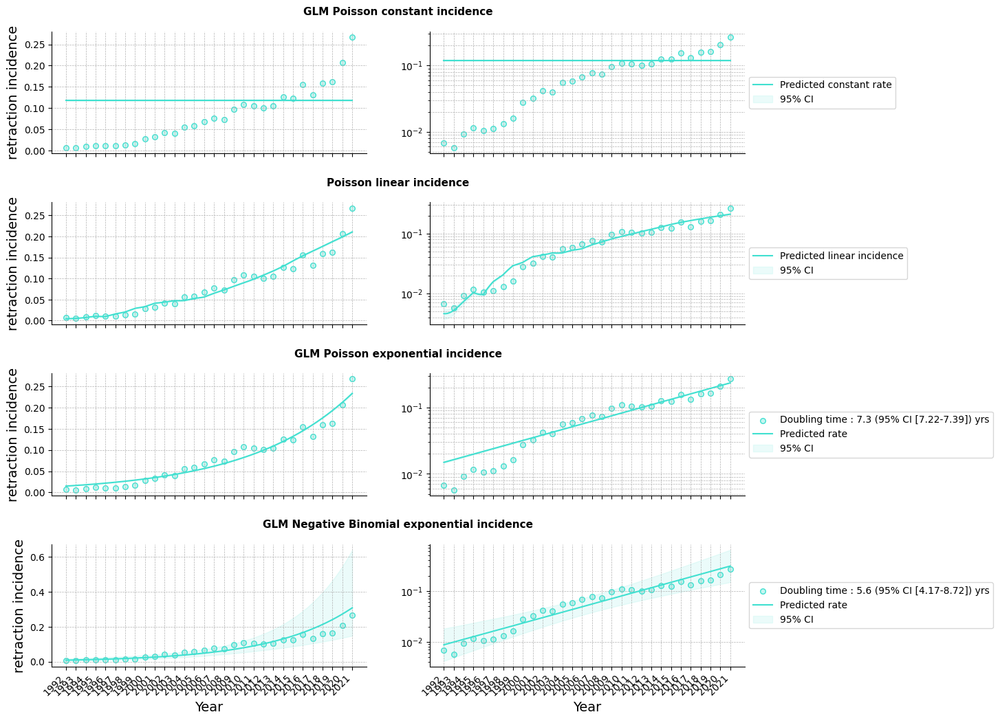

 25%|██▌       | 1/4 [00:00<00:02,  1.19it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


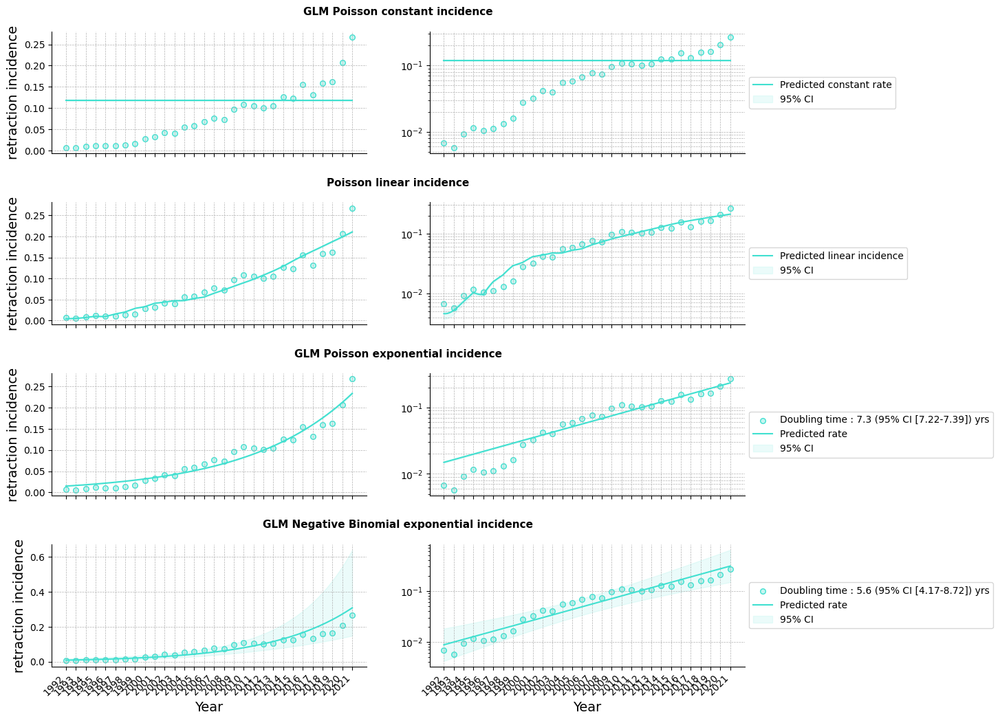

 50%|█████     | 2/4 [00:01<00:01,  1.22it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


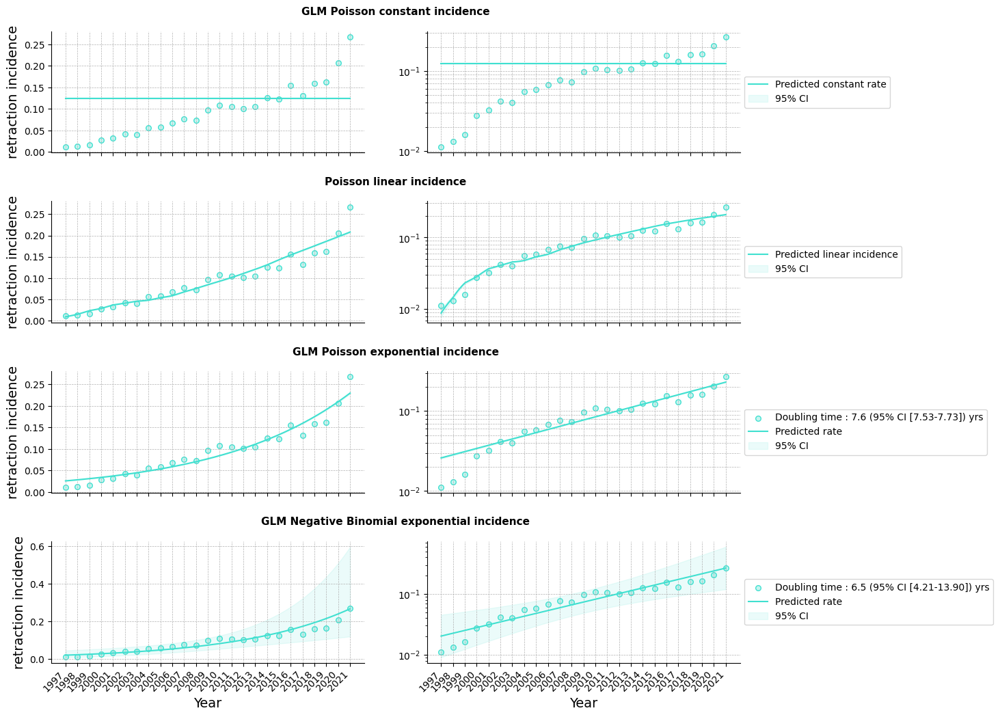

 75%|███████▌  | 3/4 [00:02<00:00,  1.30it/s]

GLM Poisson constant incidence
Poisson linear incidence
GLM Poisson exponential incidence
GLM Negative Binomial exponential incidence


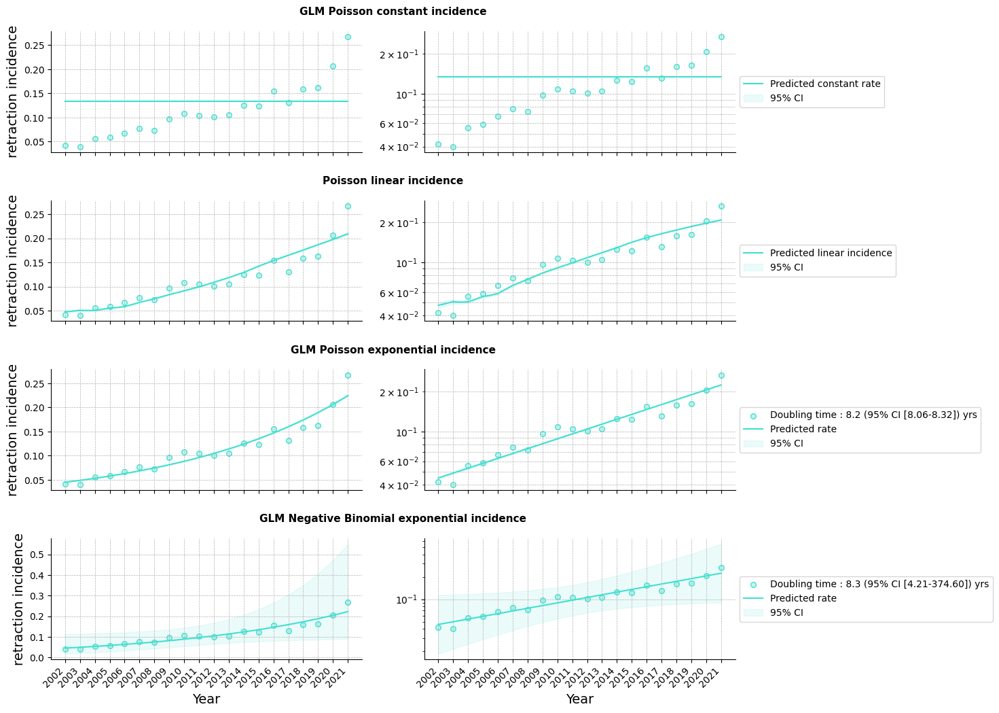

100%|██████████| 4/4 [00:03<00:00,  1.28it/s]


In [78]:
ranges_list = [(1992,2021),(1992,2022),(1997,2021),(2002,2021)]
SCALE = 1e2
alpha=1
title = 'retraction incidence authors'
results_authors_ranges_df = pd.DataFrame()
for (start_year,end_year) in tqdm(ranges_list):
    df = works_authorships_retracted_count
    df = df[(df.year >= start_year) & (df.year <= end_year)]
    results_df_ = try_all_fit(SCALE,alpha,df,start_year,end_year,True,output_folder,title)
    results_authors_ranges_df = pd.concat([results_authors_ranges_df,results_df_])
results_authors_ranges_df['range'] = results_authors_ranges_df.apply(lambda x : (x['start year'], x['end year']), axis=1)

In [79]:
df = results_authors_ranges_df[results_authors_ranges_df.model!='GLM Negative Binomial exponential incidence']
df = df[['range','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df = df.sort_values(by=['range', 'model_order']).drop(columns='model_order')
df

,range,model,ΔBIC,ΔBIC_weighted
0,"(1992, 2021)",constant,38819.872998,0.000000e+00
0,"(1992, 2021)",linear,35.369355,2.087575e-08
0,"(1992, 2021)",exponential,0.000000,1.000000e+00
0,"(1992, 2022)",constant,38819.872998,0.000000e+00
0,"(1992, 2022)",linear,35.369355,2.087575e-08
0,"(1992, 2022)",exponential,0.000000,1.000000e+00
0,"(1997, 2021)",constant,29126.932072,0.000000e+00
0,"(1997, 2021)",linear,270.682372,1.667515e-59
0,"(1997, 2021)",exponential,0.000000,1.000000e+00
0,"(2002, 2021)",constant,18979.724409,0.000000e+00


In [80]:
df = results_authors_ranges_df[results_authors_ranges_df.best_model==1][['range','b','p value b','doubling time','doubling_time_lower','doubling_time_upper']]
df = df.rename(columns={'b':'g','p value b':'p-value'})
df

,range,g,p-value,doubling time,doubling_time_lower,doubling_time_upper
0,"(1992, 2021)",0.122782,6.231853e-09,5.645341,4.173879,8.719220
0,"(1992, 2022)",0.122782,6.231853e-09,5.645341,4.173879,8.719220
0,"(1997, 2021)",0.107280,1.108838e-04,6.461108,4.208736,13.899812
0,"(2002, 2021)",0.083341,3.166398e-02,8.316973,4.205169,374.595442


## Retraction lag

Download Retraction Watch Database from https://gitlab.com/crossref/retraction-watch-data 

In [ ]:
watch_data = pd.read_csv(f'./Data/retraction-watch-data/retraction_watch.csv')

watch_data = watch_data[['OriginalPaperDate', 'RetractionDate', 'OriginalPaperPubMedID','OriginalPaperDOI', 'RetractionNature']]
watch_data['OriginalPaperDate'] = pd.to_datetime(watch_data['OriginalPaperDate'], errors='coerce')
watch_data.replace('unavailable', np.nan, inplace=True)
watch_data['RetractionDate'] = pd.to_datetime(watch_data['RetractionDate'], errors='coerce')
watch_data.replace('unavailable', np.nan, inplace=True)

watch_data1 = watch_data[['OriginalPaperDate', 'RetractionDate','OriginalPaperDOI', 'RetractionNature']].dropna().rename(columns={'OriginalPaperDOI':'doi'})
watch_data1.replace('unavailable', np.nan, inplace=True)
watch_data1['doi'] = watch_data1['doi'].astype(str)
watch_data1['doi'] = 'https://doi.org/' + watch_data1['doi']
watch_data2 = watch_data[['OriginalPaperDate','OriginalPaperPubMedID', 'RetractionNature']].dropna().rename(columns={'OriginalPaperPubMedID':'doi'})
watch_data2.replace('unavailable', np.nan, inplace=True)
watch_data2 = watch_data2[watch_data2.doi!=0]
watch_data2['doi'] = watch_data2['doi'].astype(int).astype(str)
watch_data2['doi'] = 'https://pubmed.ncbi.nlm.nih.gov/' + watch_data2['doi'] + '/'
watch_data = pd.concat([watch_data1,watch_data2]).sort_values(by='OriginalPaperDate').reset_index(drop=True)
watch_data['doi'] = watch_data['doi'].str.lower()

In [ ]:
sql = """
  CREATE TABLE `project_name.dataset_name.works_info_retracted_true` AS
  SELECT
      work_id,
      doi,
      publication_year,
    FROM
      `project_name.dataset_name.works_info`
    WHERE 
      is_retracted = 1 AND
      publication_year BETWEEN '1992-01-01' AND '2025-01-01';
"""
##output info
new_table_name = "works_authorships_retracted_count"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)

In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
works_info_retracted_true = pd.read_csv(f'./Data/works_info_retracted_true.csv.gz', compression='gzip').rename(columns={'publication_year':'year'})
works_info_retracted_true['year'] = works_info_retracted_true['year'].str[:4].astype(int)
works_info_retracted_true = works_info_retracted_true[['work_id','doi','year']]
works_info_retracted_true['doi'] = works_info_retracted_true['doi'].str.lower()
works_info_retracted_true_full = works_info_retracted_true.copy()
works_info_retracted_true = works_info_retracted_true[(works_info_retracted_true.year>=1992) & (works_info_retracted_true.year<=2021)]

df_merge = works_info_retracted_true.merge(watch_data[['doi','OriginalPaperDate', 'RetractionDate','RetractionNature']],on='doi')

print(f'{(len(df_merge) / len(works_info_retracted_true)) * 100:.2f}% retracted works matched')

93.40% retracted works matched


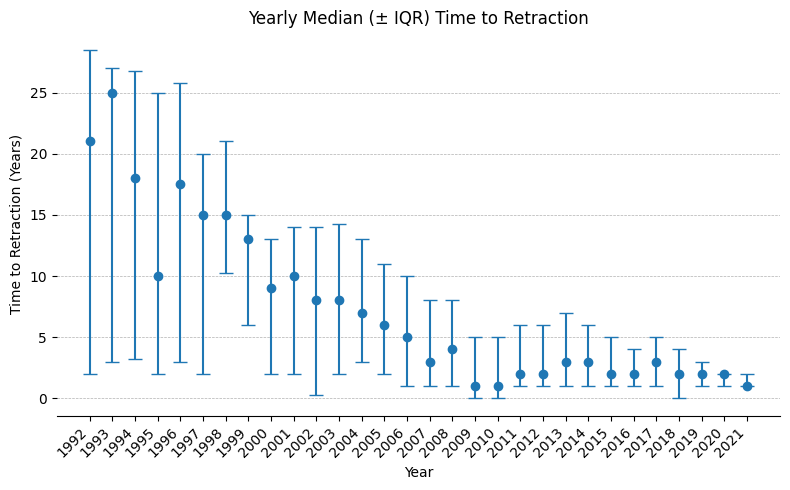

In [85]:
#time to retraction

df_time = df_merge[['year','RetractionDate']].dropna()
df_time['year_retraction'] = df_time['RetractionDate'].astype(str).str[:4].astype(int)
df_time = df_time.drop(columns='RetractionDate')
df_time['year_diff'] = df_time['year_retraction'] - df_time['year'] 

df_time_stats = df_time.groupby('year').year_diff.agg([('median', 'median'),('q25', lambda x: x.quantile(0.25)),('q75', lambda x: x.quantile(0.75))]).reset_index()

fig, ax = plt.subplots(figsize=(8, 5))

lower_err = df_time_stats['median'] - df_time_stats['q25']
upper_err = df_time_stats['q75'] - df_time_stats['median']
yerr = [lower_err, upper_err]

ax.errorbar(
    df_time_stats['year'],           # x-axis
    df_time_stats['median'],         # y-axis
    yerr=yerr,                       # asymmetric error bars
    fmt='o',                         # marker style
    capsize=5,                       # cap length for error bars
    label='Median ± IQR'
)

ax.set_xticks(df_time_stats['year'].values)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_xlabel('Year')
ax.set_ylabel('Time to Retraction (Years)')
ax.set_title('Yearly Median (± IQR) Time to Retraction')

ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, which="both", linestyle='--', linewidth=0.5)
ax.xaxis.grid(False)

plt.tight_layout()
plt.show()

91.73% retracted works matched


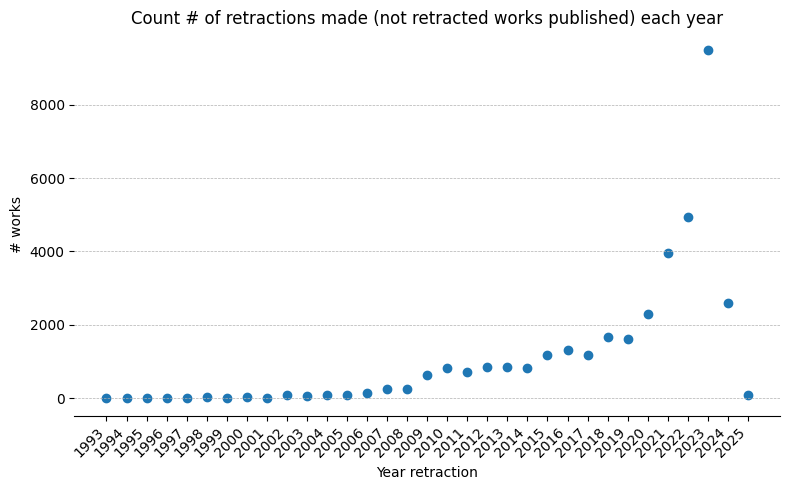

In [86]:
# number of retractions made (not retracted works published) each year

df_merge_full = works_info_retracted_true_full.merge(watch_data[['doi','OriginalPaperDate', 'RetractionDate','RetractionNature']],on='doi')
print(f'{(len(df_merge_full) / len(works_info_retracted_true_full)) * 100:.2f}% retracted works matched')
df_time_full = df_merge_full[['year','RetractionDate']].dropna()
df_time_full['year_retraction'] = df_time_full['RetractionDate'].astype(str).str[:4].astype(int)
df_time_full = df_time_full.drop(columns='RetractionDate')
df_time_full
df_count_full = df_time_full[(df_time_full.year_retraction>=1992) & (df_time_full.year_retraction<=2025)].groupby('year_retraction').year.count().to_frame().reset_index()

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df_count_full['year_retraction'].values, df_count_full['year'].values)

ax.set_xticks(df_count_full['year_retraction'].values)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_xlabel('Year retraction')
ax.set_ylabel('# works')
ax.set_title('Count # of retractions made (not retracted works published) each year')

ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, which="both", linestyle='--', linewidth=0.5)
ax.xaxis.grid(False)

plt.tight_layout()
plt.show()